# Pronóstico de casos de dengue mediante redes neuronales para series temporales

**Integrantes:**
- Valentina Giraldo Gaviria
- Héctor Betancourt López

### Objetivo del taller

El objetivo de este notebook es construir, entrenar y comparar diferentes arquitecturas de redes neuronales para pronosticar casos semanales de dengue por barrio en la ciudad de Cali.

Se implementan cinco familias de modelos:

- MLP como modelo base no recurrente.
- RNN como arquitectura recurrente tradicional.
- LSTM y GRU como arquitecturas recurrentes con compuertas.
- TCN como arquitectura convolucional causal para series temporales.

La comparación se realiza usando métricas en escala original de casos de dengue, priorizando el MSE, dado que corresponde a la métrica principal de evaluación del problema. Además, se presta especial atención a evitar fuga de información mediante división temporal, construcción causal de features, escalado ajustado únicamente sobre train y preparación consistente del set de test.

# 1. Importación de librerías, semilla y configuración global

En esta sección se importan las librerías necesarias, se fija la semilla de reproducibilidad, se define el dispositivo de cómputo y se establecen los principales parámetros globales del experimento.

Fijar una semilla es importante porque el entrenamiento de redes neuronales incluye componentes aleatorios, como inicialización de pesos, orden de batches y optimización estocástica. Aunque no garantiza reproducibilidad absoluta en todos los entornos, sí reduce la variabilidad entre ejecuciones.

In [1]:
# =========================================================
# AJUSTE DEL ENTORNO EN KAGGLE
# =========================================================

# En algunos casos, Kaggle presenta conflictos entre la GPU disponible
# y la versión de PyTorch instalada por defecto.
# Por eso, se desinstalan las versiones actuales y se reinstala
# una versión compatible con CUDA 11.8.

!pip uninstall -y torch torchvision torchaudio
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118

Found existing installation: torch 2.10.0+cu128
Uninstalling torch-2.10.0+cu128:
  Successfully uninstalled torch-2.10.0+cu128
Found existing installation: torchvision 0.25.0+cu128
Uninstalling torchvision-0.25.0+cu128:
  Successfully uninstalled torchvision-0.25.0+cu128
Found existing installation: torchaudio 2.10.0+cu128
Uninstalling torchaudio-2.10.0+cu128:
  Successfully uninstalled torchaudio-2.10.0+cu128
Looking in indexes: https://download.pytorch.org/whl/cu118
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.2/23.2 MB 77.9 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 875.6/875.6 kB 49.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 102.0 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 663.9/663.9 MB 2.9 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.9/417.9 MB 4.2 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.4/168.4 MB 2.3 MB/s eta 0:00:0000

In [2]:
# =========================================================
# IMPORTS
# =========================================================

# --- Librerías estándar de Python ---
import os       
import random   
import copy     
import math     
from math import sqrt

# --- Manipulación de datos ---
import numpy as np         
import pandas as pd        
pd.set_option('display.max_columns', None)  # mostrar todas las columnas

# --- Visualización ---
import matplotlib.pyplot as plt  
import seaborn as sns            

# --- Análisis de series de tiempo ---
from statsmodels.tsa.seasonal import seasonal_decompose        # descomposición STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf  # ACF y PACF
from statsmodels.tsa.stattools import adfuller                 # test de estacionariedad ADF

# --- Preprocesamiento y métricas ---
from sklearn.preprocessing import StandardScaler                             
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score 

# --- PyTorch: construcción y entrenamiento de redes neuronales ---
import torch
import torch.nn as nn                               
import torch.optim as optim                         
from torch.utils.data import Dataset, DataLoader    
from torch.optim.lr_scheduler import ReduceLROnPlateau  # reduce LR si val_loss se estanca

# --- Optimización de hiperparámetros ---
import optuna  

# --- Suprimir advertencias no críticas ---
import warnings
warnings.filterwarnings('ignore')

print('✅ Librerías cargadas correctamente')

✅ Librerías cargadas correctamente


In [3]:
# =========================================================
# SEMILLA DE REPRODUCIBILIDAD
# =========================================================
# Fija semillas en todas las librerías para reducir la variabilidad

SEED = 42

def reset_seed(seed=SEED):
    import random
    import numpy as np
    import torch

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = False

reset_seed(SEED)
print('✅ Semilla fijada:', SEED)

✅ Semilla fijada: 42


In [4]:
# =========================================================
# CONSTANTES GLOBALES Y CONFIGURACIÓN DE MODELOS
# =========================================================

TRAIN_END_YEAR  = 2020
VAL_START_YEAR  = 2021
USE_LOG_TARGET  = True
SEQUENCE_LENGTH = 36  # valor inicial — será sobreescrito en sección 9
                      # por el valor empírico con menor MSE en validación   

BASE_CONFIGS = {
    "MLP": {
        "hidden_sizes": (256, 128, 64),
        "dropout": 0.3,
        "lr": 5e-4,
        "batch_size": 64
    },
    "RNN": {
        "hidden_size": 128,
        "num_layers": 2,
        "dropout": 0.3,
        "lr": 5e-4,
        "batch_size": 64
    },
    "LSTM": {
        "hidden_size": 128,
        "num_layers": 2,
        "dropout": 0.3,
        "lr": 5e-4,
        "batch_size": 64
    },
    "GRU": {
        "hidden_size": 160,
        "num_layers": 2,
        "dropout": 0.2,
        "lr": 5e-4,
        "batch_size": 64
    },
    "TCN": {
        "num_channels": 64,
        "kernel_size": 4,
        "dilations": (1, 2, 4, 8),
        "dropout": 0.2,
        "lr": 1e-3,
        "batch_size": 64
    }
}

print("✅ Constantes globales definidas")
print(f"  SEQUENCE_LENGTH : {SEQUENCE_LENGTH}")
print(f"  USE_LOG_TARGET  : {USE_LOG_TARGET}")
print(f"  Modelos         : {list(BASE_CONFIGS.keys())}")

✅ Constantes globales definidas
  SEQUENCE_LENGTH : 36
  USE_LOG_TARGET  : True
  Modelos         : ['MLP', 'RNN', 'LSTM', 'GRU', 'TCN']


In [5]:
# =========================================================
# EXPLORACIÓN DE ARCHIVOS EN KAGGLE
# =========================================================
# os.walk recorre el directorio de entrada y lista todos los archivos
# disponibles para el notebook. Confirma que los parquet están cargados.
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/faii-2026-i-pronosticos-rnn-lstm-gru-tcn/sample_submission.csv
/kaggle/input/competitions/faii-2026-i-pronosticos-rnn-lstm-gru-tcn/df_test.parquet
/kaggle/input/competitions/faii-2026-i-pronosticos-rnn-lstm-gru-tcn/df_train.parquet


In [6]:
# =========================================================
# CONFIGURACIÓN DEL DISPOSITIVO (GPU / CPU)
# =========================================================
# torch.cuda.is_available(): devuelve True si hay GPU disponible en Kaggle
if torch.cuda.is_available():
    print('✅ GPU disponible:', torch.cuda.get_device_name(0))
    DEVICE = device = torch.device('cuda:0')  # primera GPU
    # CUDA_LAUNCH_BLOCKING=1: sincroniza ops GPU para depuración de errores
    os.environ['CUDA_LAUNCH_BLOCKING'] = '1'
else:
    print('⚠️  No hay GPU — corriendo en CPU')
    DEVICE = device = torch.device('cpu')

print('Dispositivo activo:', DEVICE)

✅ GPU disponible: Tesla P100-PCIE-16GB
Dispositivo activo: cuda:0


# 2. Carga de Datos

In [7]:
# =========================================================
# CARGA DEL DATASET DE ENTRENAMIENTO
# =========================================================
# pd.read_parquet: formato columnar eficiente, preserva tipos de datos
df = pd.read_parquet(
    '/kaggle/input/competitions/faii-2026-i-pronosticos-rnn-lstm-gru-tcn/df_train.parquet'
)

print('Shape:', df.shape)                          # (filas, columnas)
print('\nColumnas:', df.columns.tolist())
print('\nTipos de datos:')
print(df.dtypes)
print('\nPrimeras 5 filas:')
df.head()

Shape: (3680, 20)

Columnas: ['id', 'id_bar', 'anio', 'semana', 'ESTRATO', 'area_barrio', 'dengue', 'concentraciones', 'vivienda', 'equipesado', 'sumideros', 'maquina', 'lluvia_mean', 'lluvia_var', 'lluvia_max', 'lluvia_min', 'temperatura_mean', 'temperatura_var', 'temperatura_max', 'temperatura_min']

Tipos de datos:
id                   object
id_bar                int64
anio                  int64
semana               UInt32
ESTRATO             float64
area_barrio         float64
dengue              float64
concentraciones     float64
vivienda            float64
equipesado          float64
sumideros           float64
maquina             float64
lluvia_mean         float64
lluvia_var          float64
lluvia_max          float64
lluvia_min          float64
temperatura_mean    float64
temperatura_var     float64
temperatura_max     float64
temperatura_min     float64
dtype: object

Primeras 5 filas:


,id,id_bar,anio,semana,ESTRATO,area_barrio,dengue,concentraciones,vivienda,equipesado,sumideros,maquina,lluvia_mean,lluvia_var,lluvia_max,lluvia_min,temperatura_mean,temperatura_var,temperatura_max,temperatura_min
0,4_2015_01,4,2015,1,3.0,0.560,0.0,0.0,0.0,0.0,0.0,0.0,0.000651,0.000041,0.0625,0.0,26.163889,11.588928,31.8,20.9
1,5_2015_01,5,2015,1,3.0,0.842,0.0,0.0,0.0,0.0,0.0,0.0,0.000651,0.000041,0.0625,0.0,26.163889,11.588928,31.8,20.9
2,3_2015_01,3,2015,1,1.0,0.781,0.0,0.0,0.0,0.0,0.0,0.0,0.000651,0.000041,0.0625,0.0,26.163889,11.588928,31.8,20.9
3,8_2015_01,8,2015,1,2.0,0.394,0.0,0.0,0.0,0.0,0.0,0.0,0.000651,0.000041,0.0625,0.0,26.163889,11.588928,31.8,20.9
4,9_2015_01,9,2015,1,2.0,0.292,0.0,0.0,0.0,0.0,0.0,0.0,0.000651,0.000041,0.0625,0.0,26.163889,11.588928,31.8,20.9


# 3. Análisis Exploratorio de Datos

El análisis exploratorio permite comprender la estructura del problema antes de entrenar los modelos.

En particular, se revisan:

- Dimensiones y tipos de variables.
- Valores faltantes.
- Distribución de la variable objetivo.
- Evolución temporal de los casos de dengue.
- Diferencias entre barrios.
- Relación inicial entre variables climáticas, estructurales y casos.
- Presencia de valores cero, picos y variabilidad extrema.

Este análisis es clave porque las decisiones posteriores de modelado deben estar justificadas por el comportamiento observado en los datos.

In [8]:
# =========================================================
# VALORES FALTANTES Y ESTADÍSTICAS BÁSICAS
# =========================================================
# En series de tiempo los NaN deben tratarse respetando el orden temporal.
# Aquí verificamos cuáles columnas los tienen antes de decidir cómo tratarlos.

print('=== Valores Faltantes ===')
missing = df.isnull().sum()
# Solo imprime columnas con NaN; si no hay, confirma con mensaje
print(missing[missing > 0] if missing.sum() > 0 else '✅ Sin valores faltantes')

print('\n=== Estadísticas Descriptivas (target: dengue) ===')
print(df['dengue'].describe())
# count: registros totales | mean: promedio | std: desviación | max: pico máximo

print('\n=== Rango temporal ===')
print(f'Años    : {df.anio.min()} → {df.anio.max()}')
print(f'Semanas : {df.semana.min()} → {df.semana.max()}')
print(f'Barrios : {df.id_bar.nunique()} series independientes')
print(f'Registros por barrio (promedio): {len(df)/df.id_bar.nunique():.1f}')

# Verificación explícita de lluvia_min
print('\n⚠️  Verificación adicional de lluvia_min:')
print(f'   NaN en lluvia_min: {df["lluvia_min"].isnull().sum()} de {len(df)} registros')
print(f'   Valores únicos: {df["lluvia_min"].nunique()}')
# lluvia_min tiene NaN → se excluirá del feature set en la sección 4.
# El resto de variables se revisa en el análisis de correlación siguiente.

=== Valores Faltantes ===
✅ Sin valores faltantes

=== Estadísticas Descriptivas (target: dengue) ===
count    3680.000000
mean        2.609511
std         3.523843
min         0.000000
25%         0.000000
50%         1.000000
75%         3.000000
max        29.000000
Name: dengue, dtype: float64

=== Rango temporal ===
Años    : 2015 → 2021
Semanas : 1 → 53
Barrios : 10 series independientes
Registros por barrio (promedio): 368.0

⚠️  Verificación adicional de lluvia_min:
   NaN en lluvia_min: 0 de 3680 registros
   Valores únicos: 1


Correlación global con dengue (|corr| ordenado):
temperatura_min     0.186
temperatura_mean    0.128
lluvia_mean        -0.108
sumideros           0.107
lluvia_var         -0.088
equipesado          0.075
temperatura_var    -0.048
lluvia_max         -0.047
concentraciones    -0.037
vivienda           -0.024
maquina             0.012
temperatura_max    -0.000
lluvia_min            NaN
Name: dengue, dtype: float64

Correlación promedio POR BARRIO con dengue:
temperatura_min     0.188
temperatura_mean    0.128
sumideros           0.123
equipesado          0.078
maquina             0.013
temperatura_max    -0.001
vivienda           -0.012
concentraciones    -0.039
lluvia_max         -0.049
temperatura_var    -0.050
lluvia_var         -0.091
lluvia_mean        -0.110
lluvia_min            NaN
dtype: float64


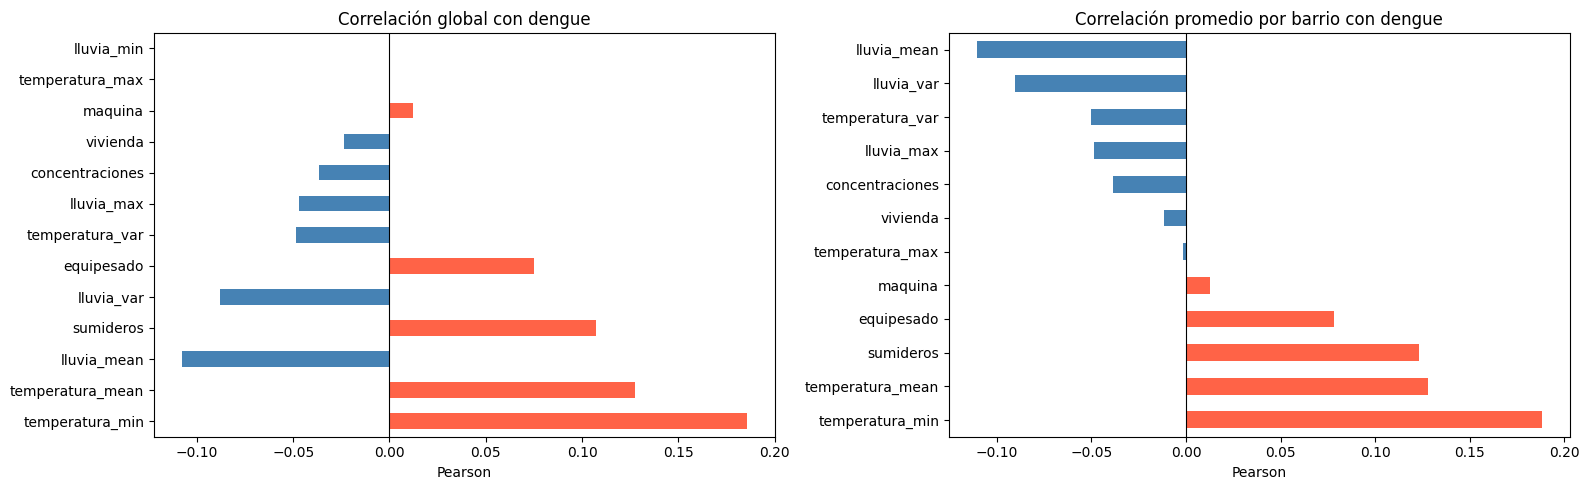


→ Features prioritarios: temperatura_min, temperatura_mean, sumideros, lluvia_mean


In [9]:
# =========================================================
# VARIABLES NUMÉRICAS Y CORRELACIÓN CON EL TARGET
# =========================================================
# Identificamos las variables numéricas disponibles
num_vars = [
    'dengue', 'concentraciones', 'vivienda', 'equipesado', 'sumideros',
    'maquina', 'lluvia_mean', 'lluvia_var', 'lluvia_max', 'lluvia_min',
    'temperatura_mean', 'temperatura_var', 'temperatura_max', 'temperatura_min'
]

# --- Correlación global con el target ---
# Pearson mide relación lineal; valores > |0.1| se consideran relevantes
corr_global = df[num_vars].corr()['dengue'].drop('dengue').sort_values(key=abs, ascending=False)
print('Correlación global con dengue (|corr| ordenado):')
print(corr_global.round(3))

# --- Correlación promedio por barrio (más robusta que la global) ---
# Por qué: la correlación global puede estar dominada por barrios con más casos.
# Calculando por barrio y promediando obtenemos una visión más equitativa.
corrs = []
for b in df['id_bar'].unique():
    subset = df[df['id_bar'] == b]
    corr = subset[num_vars].corr()['dengue']
    corrs.append(corr)
corrs_mean = pd.concat(corrs, axis=1).mean(axis=1).drop('dengue').sort_values(ascending=False)
print('\nCorrelación promedio POR BARRIO con dengue:')
print(corrs_mean.round(3))

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
corr_global.plot(kind='barh',
    color=['tomato' if v > 0 else 'steelblue' for v in corr_global], ax=axes[0])
axes[0].axvline(0, color='black', lw=0.8)
axes[0].set_title('Correlación global con dengue')
axes[0].set_xlabel('Pearson')

corrs_mean.drop('lluvia_min', errors='ignore').plot(kind='barh',
    color=['tomato' if v > 0 else 'steelblue' for v in corrs_mean.drop('lluvia_min', errors='ignore')],
    ax=axes[1])
axes[1].axvline(0, color='black', lw=0.8)
axes[1].set_title('Correlación promedio por barrio con dengue')
axes[1].set_xlabel('Pearson')

plt.tight_layout()
plt.show()
print('\n→ Features prioritarios: temperatura_min, temperatura_mean, sumideros, lluvia_mean')

### Decisión de features basada en correlaciones

Del análisis anterior se identifican tres grupos de variables:

**Grupo A — Alta relevancia (|corr| > 0.10):** `temperatura_min`, `temperatura_mean`, `lluvia_mean`, `sumideros`
→ Se incluyen directamente en el feature set.

**Grupo B — Relevancia media (0.05 < |corr| ≤ 0.10):** `equipesado`
→ Se incluye por correlación media con el target.

**Incluidas por criterio estructural:** `area_barrio`
→ No correlacionada directamente con dengue, pero captura heterogeneidad espacial entre barrios. Se incluye como variable de control.

**Grupo C — Baja relevancia o problemáticas:** `concentraciones`, `vivienda`, `maquina`, `lluvia_var`, `lluvia_max`, `lluvia_min`, `temperatura_var`, `temperatura_max`
→ Se **excluyen** por baja correlación, multicolinealidad o presencia de NaN.

Esta decisión define el conjunto base de features climáticas y estructurales que, junto con los lags climáticos y las estadísticas rolling del target construidos en la sección 4, conforman el set completo de `features_cols_base` (17 variables) y `features_cols_mlp` (21 variables para el MLP).

In [10]:
# =========================================================
# CONSTRUCCIÓN DEL ÍNDICE TEMPORAL
# =========================================================
# Se crea 'fecha' como string YYYYWW para ordenar correctamente.
# zfill(2) asume semanas de 1-52 (máximo 2 dígitos), válido para datos semanales anuales.
# Alternativa más robusta: pd.to_datetime con format='%G%V', pero zfill es suficiente aquí.

df['fecha'] = df['anio'].astype(str) + df['semana'].astype(str).str.zfill(2)
# zfill(2): rellena con ceros → semana 5 → '05', evita error de orden lexicográfico

df = df.sort_values(by=['fecha', 'id_bar']).reset_index(drop=True)

# Serie total agregada por semana (para análisis macro)
dengue_by_week = df.groupby('fecha')['dengue'].sum().reset_index()
dengue_by_week.columns = ['fecha', 'dengue']
dengue_by_week['week_num'] = dengue_by_week['fecha'].str[4:].astype(int)  # semana del año
dengue_by_week['year']     = dengue_by_week['fecha'].str[:4].astype(int)  # año

print('✅ Índice temporal construido')
print(f'Semanas únicas en el dataset: {len(dengue_by_week)}')
dengue_by_week.head()

✅ Índice temporal construido
Semanas únicas en el dataset: 368


,fecha,dengue,week_num,year
0,201501,0.0,1,2015
1,201502,13.0,2,2015
2,201503,28.0,3,2015
3,201504,48.0,4,2015
4,201505,53.0,5,2015


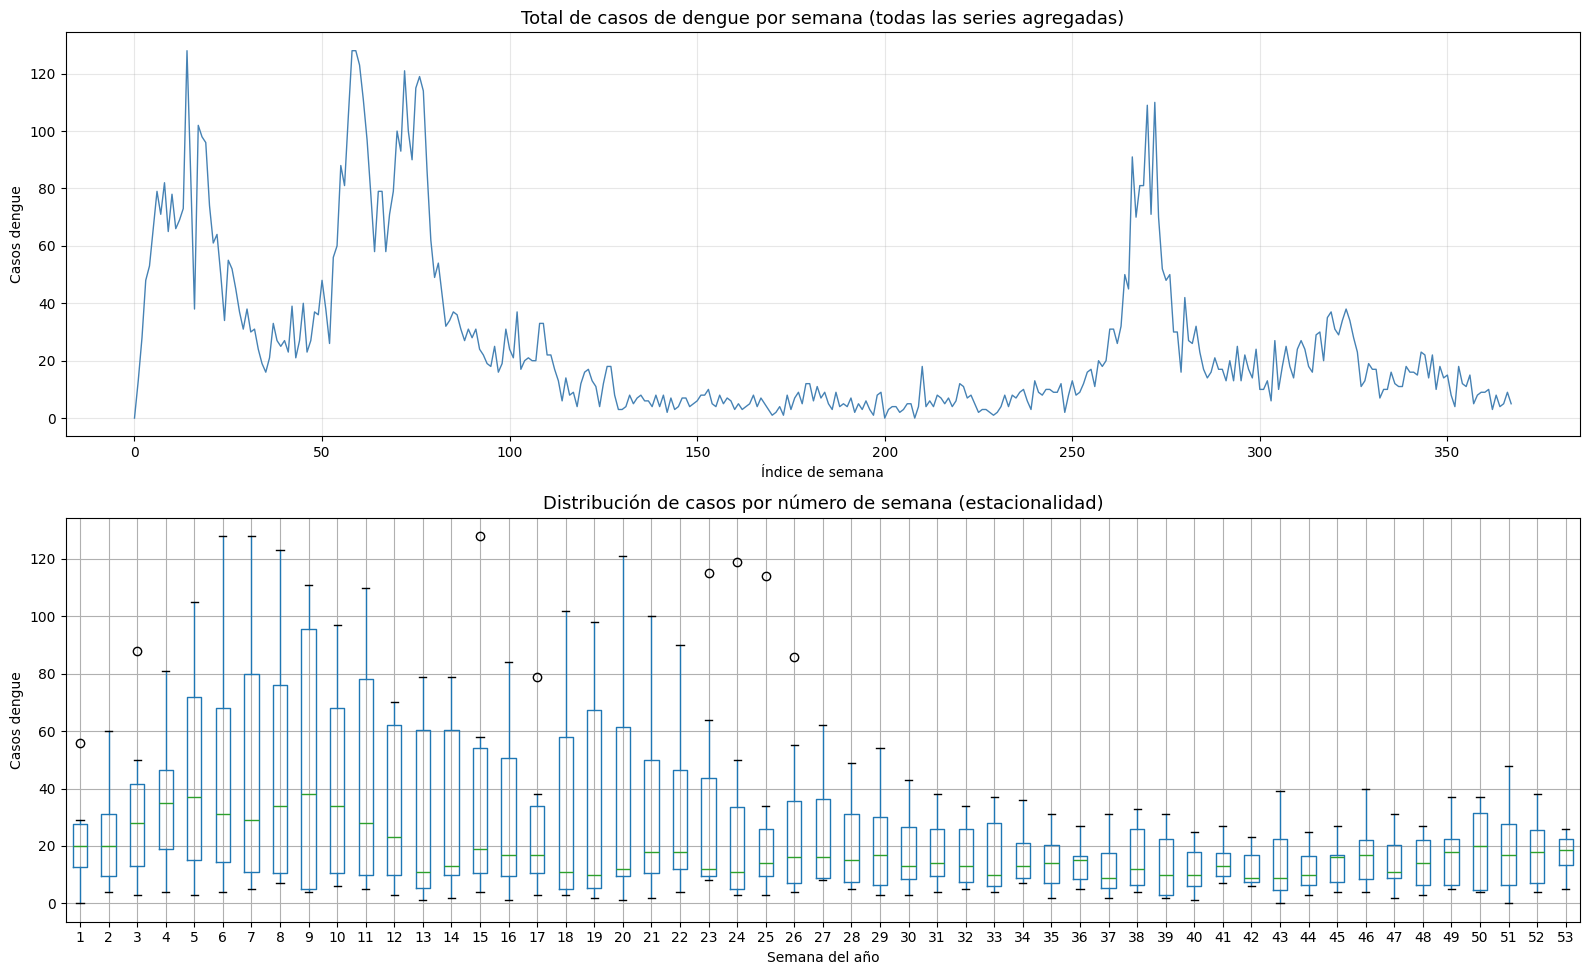

Interpretación:
→ Si el boxplot muestra diferencias claras entre semanas, hay estacionalidad.
→ Esto justifica codificar la semana del año como feature (week_sin, week_cos).


In [11]:
# =========================================================
# VISUALIZACIÓN GENERAL DE LA SERIE Y ESTACIONALIDAD
# =========================================================
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Panel 1: Serie completa
# Permite ver tendencia global, picos epidémicos y variabilidad
axes[0].plot(dengue_by_week['dengue'].values, color='steelblue', linewidth=1)
axes[0].set_title('Total de casos de dengue por semana (todas las series agregadas)', fontsize=13)
axes[0].set_xlabel('Índice de semana')
axes[0].set_ylabel('Casos dengue')
axes[0].grid(True, alpha=0.3)

# Panel 2: Boxplot por semana del año
# Si los picos se concentran en ciertas semanas → hay estacionalidad anual
# Esto justifica incluir week_sin/cos como features del modelo
dengue_by_week.boxplot(column='dengue', by='week_num', ax=axes[1], grid=True)
axes[1].set_title('Distribución de casos por número de semana (estacionalidad)', fontsize=13)
axes[1].set_xlabel('Semana del año')
axes[1].set_ylabel('Casos dengue')
plt.suptitle('')

plt.tight_layout()
plt.show()

print('Interpretación:')
print('→ Si el boxplot muestra diferencias claras entre semanas, hay estacionalidad.')
print('→ Esto justifica codificar la semana del año como feature (week_sin, week_cos).')

Estadísticas de dengue por barrio:
        mean   std   max     sum
id_bar                          
0       3.32  4.33  29.0  1220.0
1       2.85  4.03  28.0  1049.0
2       2.75  3.66  26.0  1013.0
3       2.67  3.25  18.0   982.0
4       2.61  3.78  22.0   959.0
5       2.46  2.88  16.0   907.0
6       2.40  3.18  17.0   883.0
7       2.35  3.10  20.0   865.0
8       2.37  3.50  24.0   873.0
9       2.32  3.18  17.0   852.0


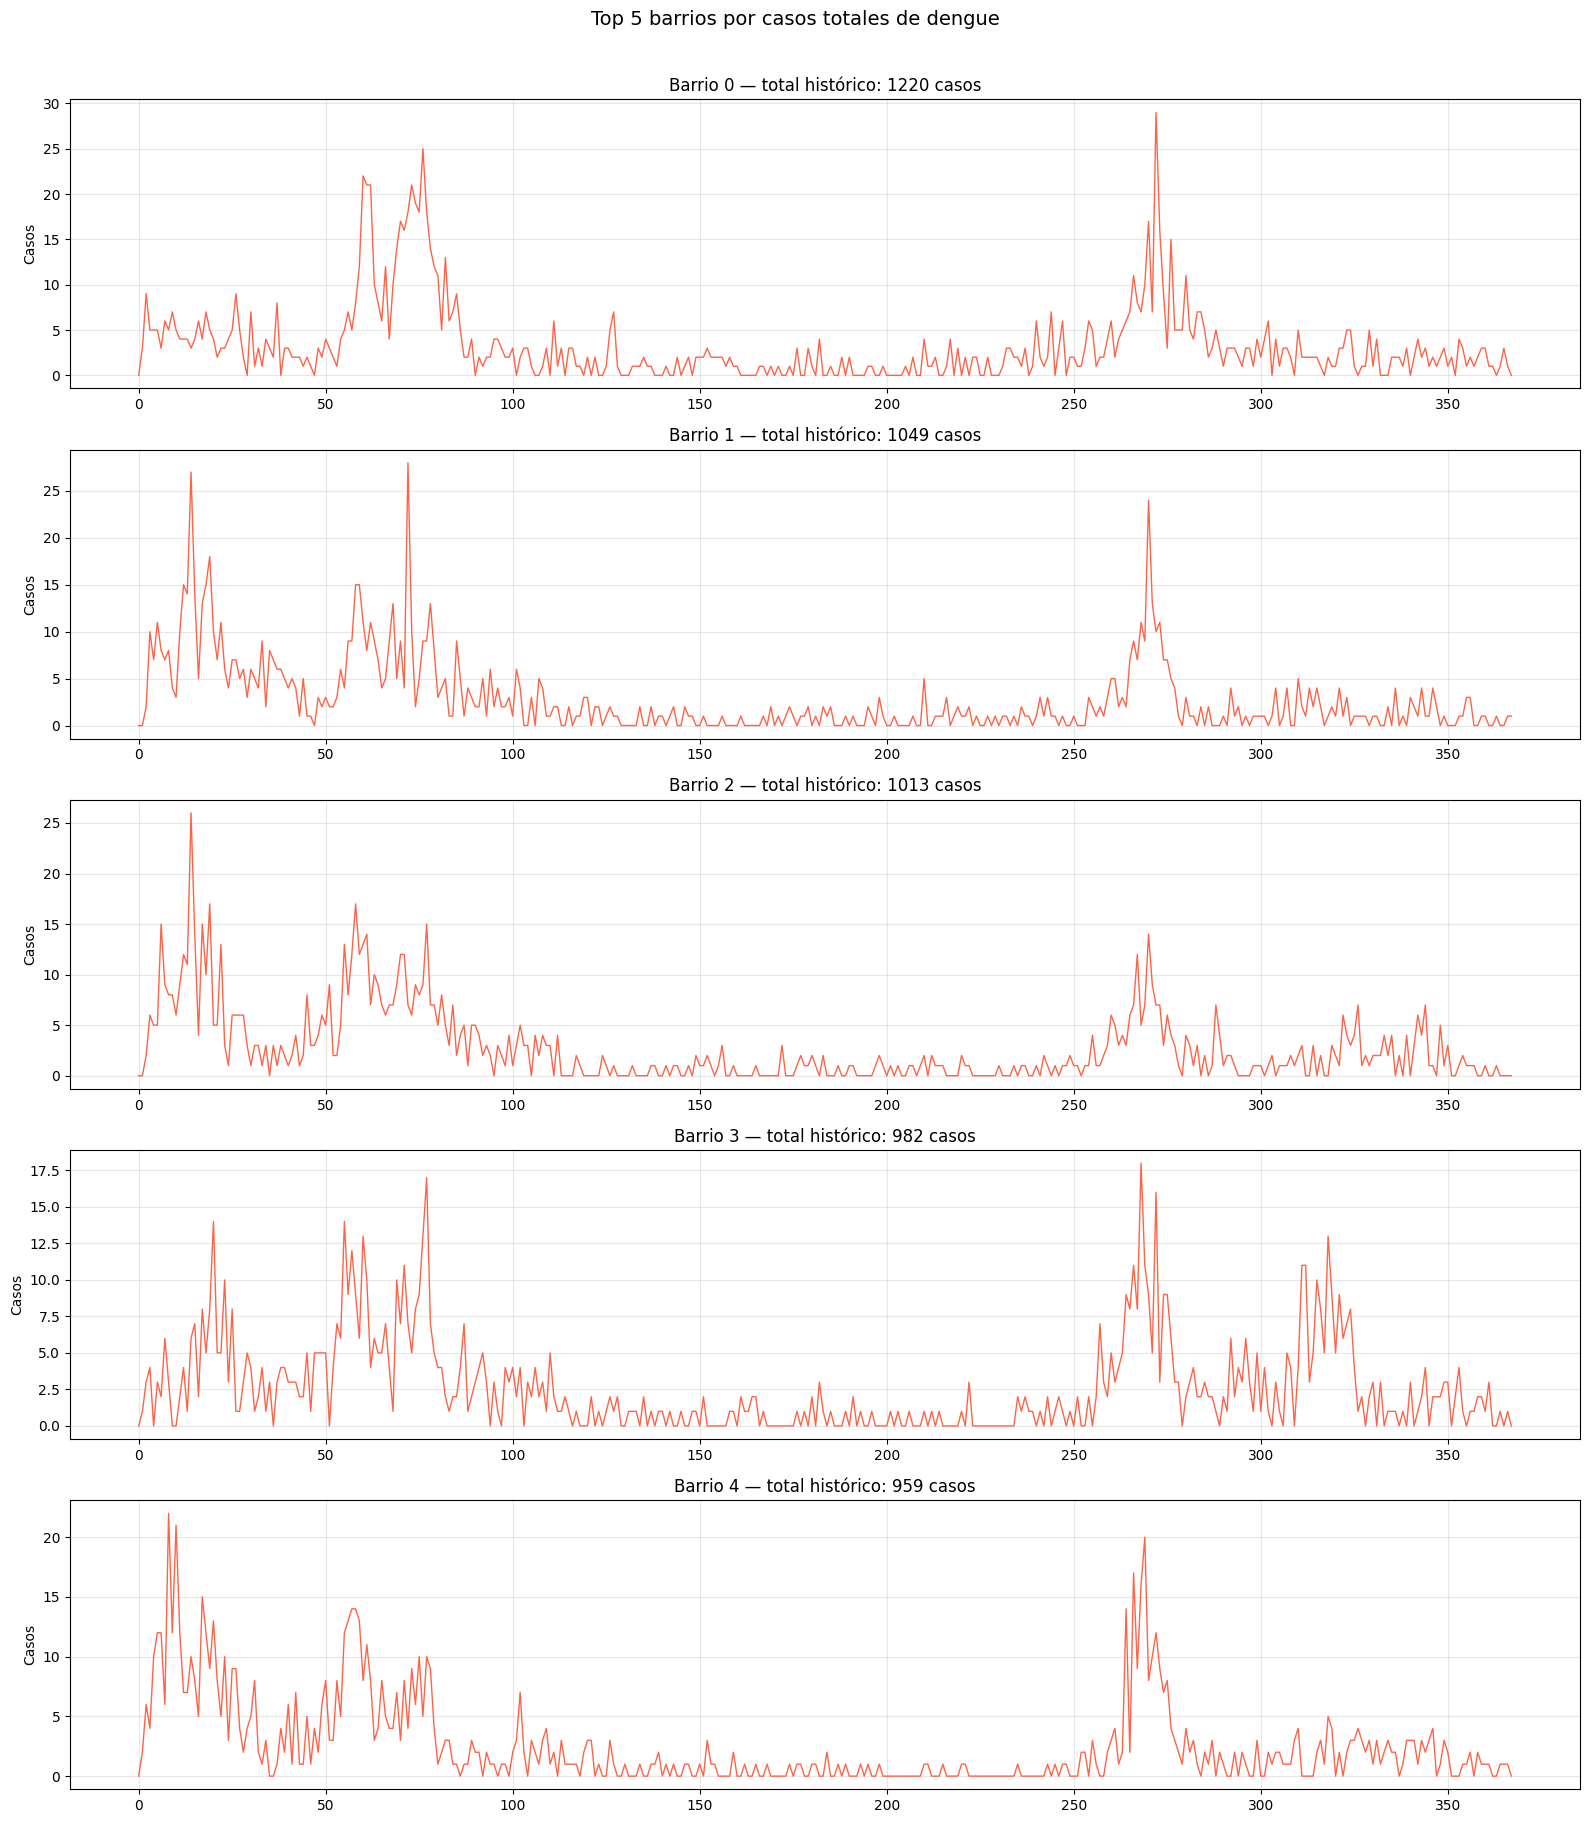


Conclusión: La variabilidad entre barrios es alta → un modelo global
puede no capturar bien cada serie individualmente.


In [12]:
# =========================================================
# ANÁLISIS POR BARRIO — ESTADÍSTICAS E HETEROGENEIDAD
# =========================================================
# Cada barrio es una serie temporal independiente.
# Analizamos si hay heterogeneidad significativa entre ellos.
barrio_stats = df.groupby('id_bar')['dengue'].agg(['mean', 'std', 'max', 'sum'])
print('Estadísticas de dengue por barrio:')
print(barrio_stats.round(2))

# Top 5 barrios por casos totales
top5 = barrio_stats.nlargest(5, 'sum').index.tolist()

fig, axes = plt.subplots(5, 1, figsize=(16, 18), sharex=False)
for ax, bid in zip(axes, top5):
    sub = df[df['id_bar'] == bid].sort_values('fecha')
    ax.plot(sub['dengue'].values, color='tomato', linewidth=1)
    ax.set_title(f'Barrio {bid} — total histórico: {sub["dengue"].sum():.0f} casos')
    ax.set_ylabel('Casos')
    ax.grid(True, alpha=0.3)
plt.suptitle('Top 5 barrios por casos totales de dengue', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

print('\nConclusión: La variabilidad entre barrios es alta → un modelo global')
print('puede no capturar bien cada serie individualmente.')

→ Alta heterogeneidad entre barrios: las series difieren en media, varianza y picos.

→ Decisión: incluir area_barrio y ESTRATO_norm como features estructurales
  para que el modelo distinga entre barrios sin necesitar embeddings específicos.
  
→ Esta heterogeneidad también anticipa R² negativo en los modelos globales:
  predecir la media global es peor que predecir la media por barrio.

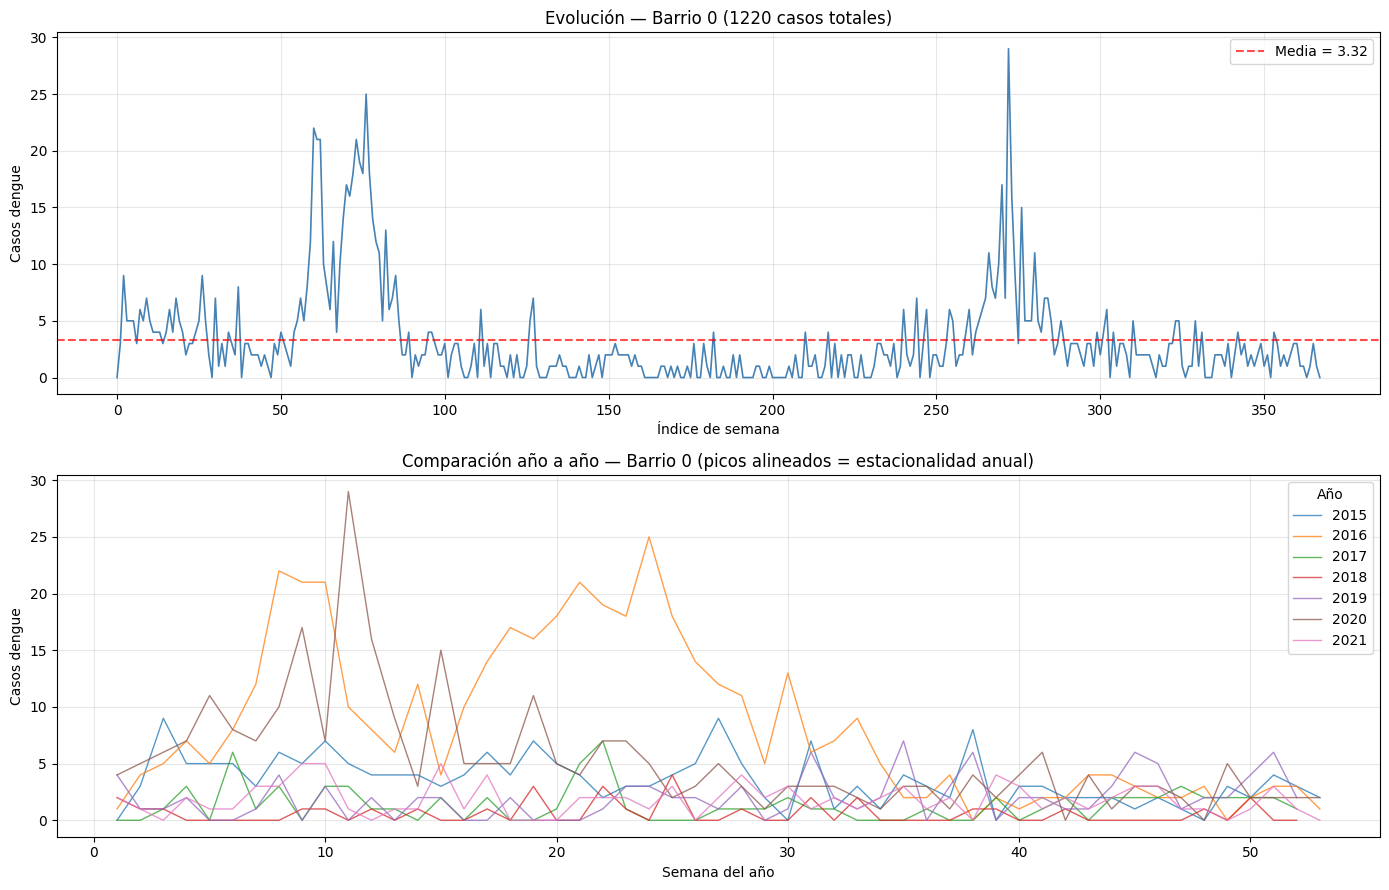

Barrio 0:
  Semanas registradas : 368
  Casos totales       : 1220
  Media semanal       : 3.32 casos
  Pico máximo         : 29 casos (semana 11, año 2020)

→ Si los picos año-a-año se alinean en las mismas semanas, se confirma
  estacionalidad anual → justifica week_sin/cos como features del modelo.


In [13]:
# =========================================================
# SERIE TEMPORAL DE UN BARRIO REPRESENTATIVO
# =========================================================
# Visualizamos el barrio con mayor carga histórica.
# El panel año-a-año confirma si hay estacionalidad anual.
barrio_id = barrio_stats['sum'].idxmax()  # barrio con más casos totales
barrio_ref = barrio_id  # alias para celdas posteriores (ACF/PACF)

sub = df[df['id_bar'] == barrio_id].sort_values('fecha').reset_index(drop=True)

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Panel 1: serie completa con línea de media
axes[0].plot(sub.index, sub['dengue'], color='steelblue', linewidth=1.2)
axes[0].axhline(sub['dengue'].mean(), color='red', linestyle='--', alpha=0.7,
                label=f'Media = {sub["dengue"].mean():.2f}')
axes[0].set_title(f'Evolución — Barrio {barrio_id} '
                  f'({sub["dengue"].sum():.0f} casos totales)', fontsize=12)
axes[0].set_xlabel('Índice de semana')
axes[0].set_ylabel('Casos dengue')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Panel 2: año a año superpuesto
# Si los picos se alinean en las mismas semanas → estacionalidad anual confirmada
for anio_val, grupo in sub.groupby('anio'):
    axes[1].plot(grupo['semana'].values, grupo['dengue'].values,
                 label=str(anio_val), alpha=0.75, linewidth=1)
axes[1].set_title(f'Comparación año a año — Barrio {barrio_id} '
                  f'(picos alineados = estacionalidad anual)', fontsize=12)
axes[1].set_xlabel('Semana del año')
axes[1].set_ylabel('Casos dengue')
axes[1].legend(title='Año', loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Estadísticas clave
pico_idx  = sub['dengue'].idxmax()
print(f'Barrio {barrio_id}:')
print(f'  Semanas registradas : {len(sub)}')
print(f'  Casos totales       : {sub["dengue"].sum():.0f}')
print(f'  Media semanal       : {sub["dengue"].mean():.2f} casos')
print(f'  Pico máximo         : {sub["dengue"].max():.0f} casos '
      f'(semana {sub.loc[pico_idx, "semana"]}, año {sub.loc[pico_idx, "anio"]})')
print()
print('→ Si los picos año-a-año se alinean en las mismas semanas, se confirma')
print('  estacionalidad anual → justifica week_sin/cos como features del modelo.')

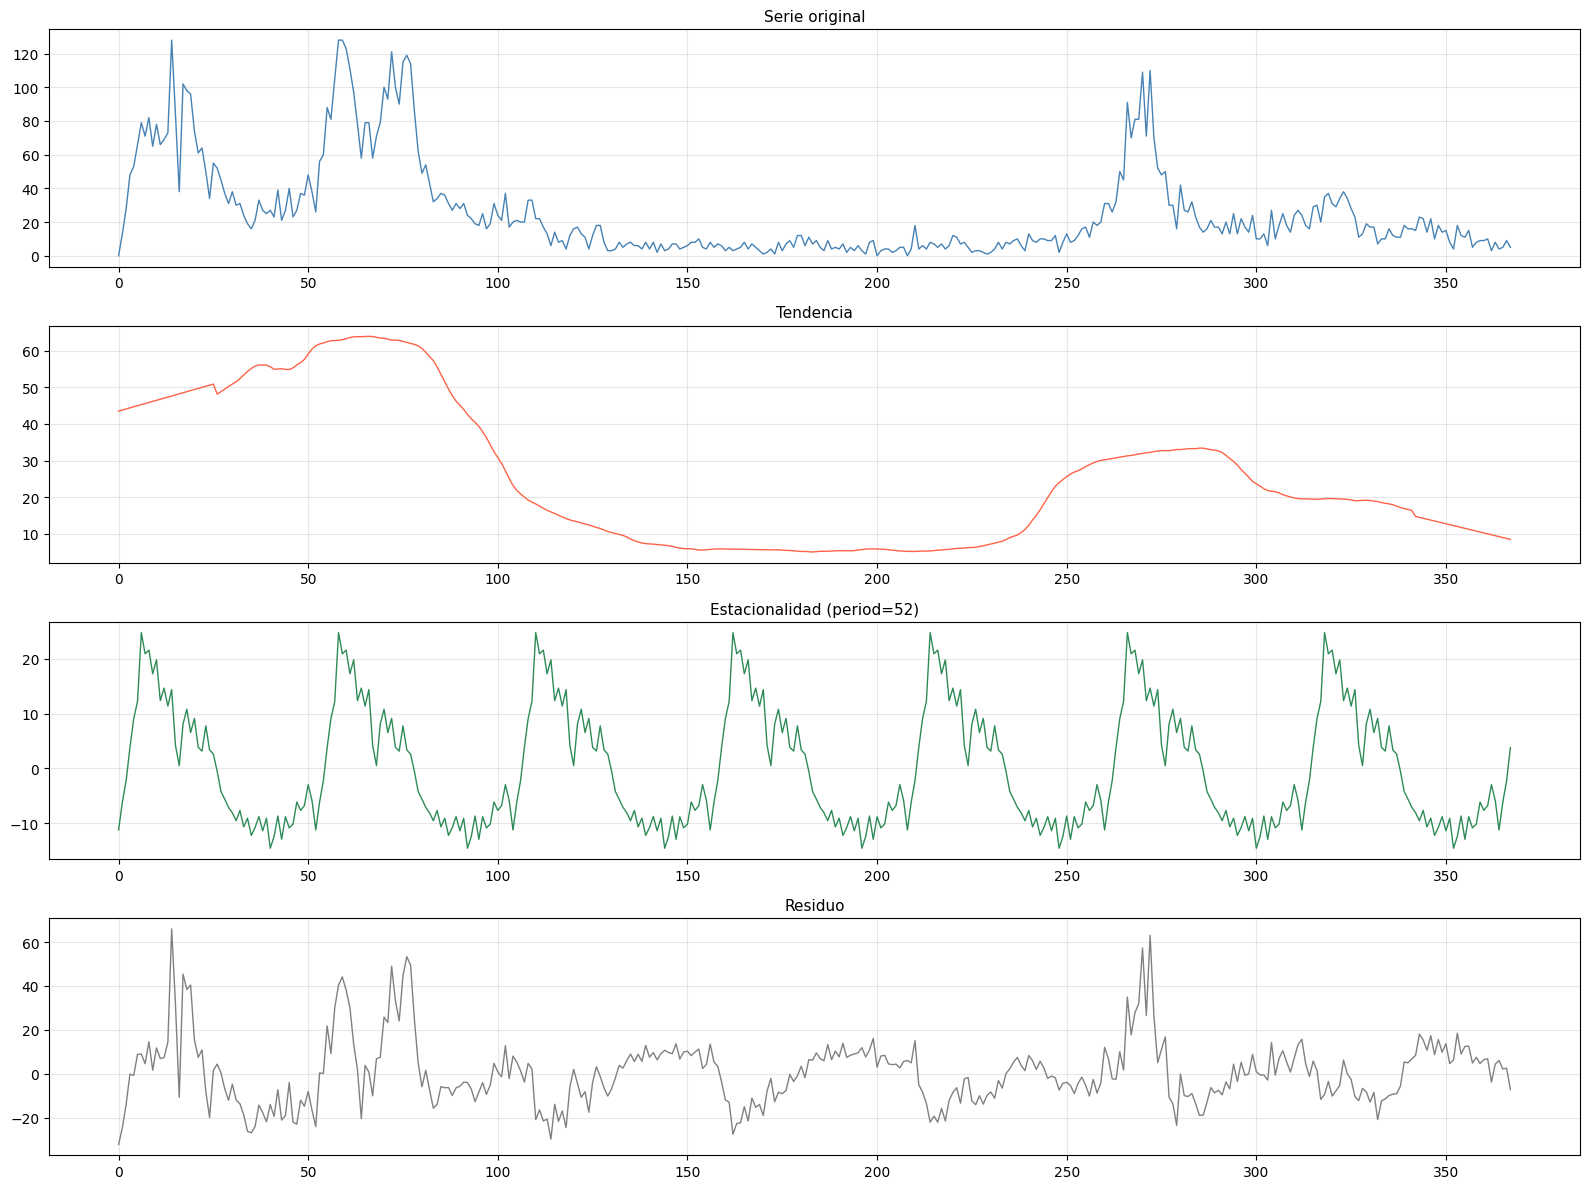

Interpretación:
→ Si la componente estacional tiene amplitud significativa,
  el feature "semana" (o week_sin/cos) es muy relevante para el modelo.
→ Un residuo con patrones aún visibles sugiere más features o mayor SEQUENCE_LENGTH.


In [14]:
# =========================================================
# DESCOMPOSICIÓN STL DE LA SERIE TOTAL
# =========================================================
# seasonal_decompose separa la serie en 3 componentes:
#   Tendencia  : dirección de largo plazo (¿crecen los casos?)
#   Estacional : patrón que se repite (ciclo anual de 52 semanas)
#   Residuo    : variación no explicada por las otras dos componentes
#
# model='additive': Observado = Tendencia + Estacional + Residuo
# Se eligió 'additive' porque la amplitud estacional en este dataset
# no muestra crecimiento proporcional claro con la tendencia.
# Si el residuo de la descomposición muestra patrón estacional residual,
# sería evidencia de que 'multiplicative' sería más apropiado.

# period=52: un ciclo completo = 52 semanas (frecuencia anual de datos semanales)
# extrapolate_trend='freq': rellena los NaN de los extremos de la tendencia

serie_total = dengue_by_week['dengue'].values

try:
    result = seasonal_decompose(serie_total, model='additive', period=52,
                                extrapolate_trend='freq')

    fig, axes = plt.subplots(4, 1, figsize=(16, 12))
    for ax, data, label, color in zip(
        axes,
        [serie_total, result.trend, result.seasonal, result.resid],
        ['Serie original', 'Tendencia', 'Estacionalidad (period=52)', 'Residuo'],
        ['steelblue', 'tomato', 'seagreen', 'gray']
    ):
        ax.plot(data, color=color, linewidth=1)
        ax.set_title(label, fontsize=11)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print('Interpretación:')
    print('→ Si la componente estacional tiene amplitud significativa,')
    print('  el feature "semana" (o week_sin/cos) es muy relevante para el modelo.')
    print('→ Un residuo con patrones aún visibles sugiere más features o mayor SEQUENCE_LENGTH.')

except Exception as e:
    print(f'Descomposición no disponible: {e}')

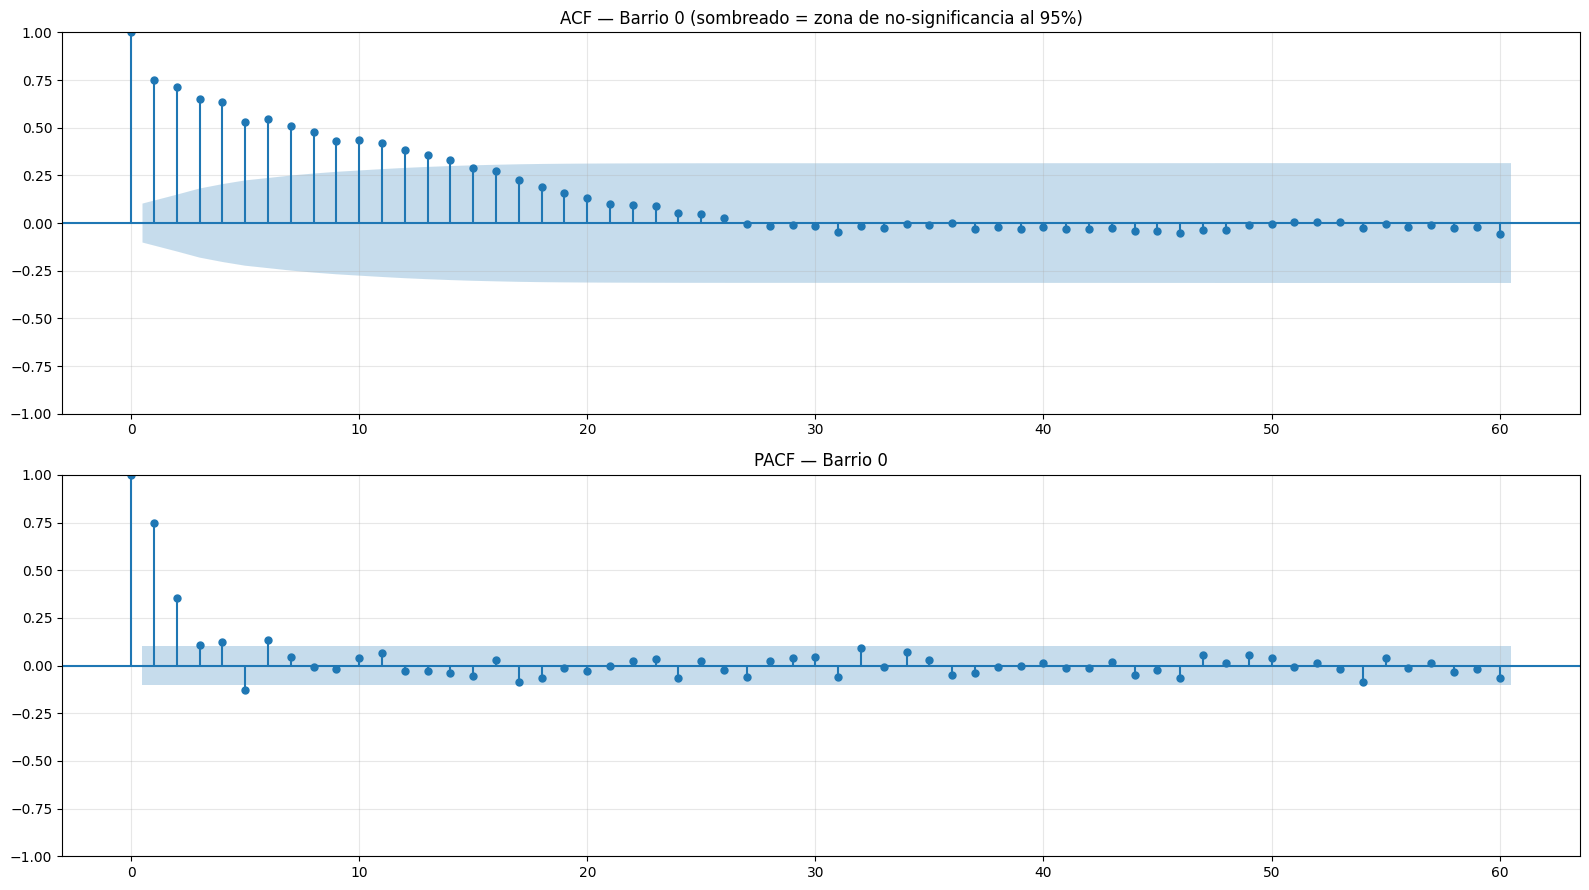


→ Los lags FUERA de la banda sombreada en el PACF son estadísticamente
  significativos → indican el número de pasos históricos que el modelo debe ver.
→ Observar el gráfico: el lag donde el PACF cae dentro de la banda
  indica cuánta historia tiene valor predictivo en este barrio.
  Típicamente entre 10 y 36 semanas para series de dengue.


In [15]:
# =========================================================
# ACF Y PACF — GUÍA PARA SEQUENCE_LENGTH
# =========================================================
# ACF (Autocorrelación):
#   - Mide correlación de la serie con sus propios lags
#   - Decaimiento lento → serie no estacionaria (tendencia)
#   - Picos en lag 52, 104 → estacionalidad anual
#
# PACF (Autocorrelación Parcial):
#   - Correlación con lag k removiendo el efecto de los lags intermedios
#   - El lag donde el PACF cae DENTRO de la banda de confianza por primera vez
#    indica el orden de autocorrelación significativa → guía SEQUENCE_LENGTH.

serie_barrio = df[df['id_bar'] == barrio_ref].sort_values('fecha')['dengue'].values

fig, axes = plt.subplots(2, 1, figsize=(16, 9))

# lags=60: analizamos hasta 60 semanas (~14 meses)
# alpha=0.05: banda de confianza al 95%
plot_acf(serie_barrio, lags=60, ax=axes[0], alpha=0.05)
axes[0].set_title(f'ACF — Barrio {barrio_ref} '
                  f'(sombreado = zona de no-significancia al 95%)', fontsize=12)
axes[0].grid(True, alpha=0.3)

# method='ywm': Yule-Walker modificado, más estable para series cortas
plot_pacf(serie_barrio, lags=60, ax=axes[1], alpha=0.05, method='ywm')
axes[1].set_title(f'PACF — Barrio {barrio_ref}', fontsize=12)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print()
print('→ Los lags FUERA de la banda sombreada en el PACF son estadísticamente')
print('  significativos → indican el número de pasos históricos que el modelo debe ver.')
print('→ Observar el gráfico: el lag donde el PACF cae dentro de la banda')
print('  indica cuánta historia tiene valor predictivo en este barrio.')
print('  Típicamente entre 10 y 36 semanas para series de dengue.')

In [16]:
# =========================================================
# TEST DE ESTACIONARIEDAD (Dickey-Fuller Aumentado)
# =========================================================
# H0 (hipótesis nula): la serie TIENE raíz unitaria → NO es estacionaria
# Si p-value < 0.05 → rechazamos H0 → la serie ES estacionaria
#
# Una serie no estacionaria puede dificultar el aprendizaje porque
# la distribución cambia en el tiempo → el modelo ve patrones inconsistentes
# Solución si no es estacionaria: diferenciación o transformación log(1+y)

# autolag='AIC': selecciona automáticamente el número óptimo de lags del test
adf_result = adfuller(serie_barrio, autolag='AIC')

print('=== Test de Dickey-Fuller Aumentado (ADF) ===')
print(f'ADF Statistic : {adf_result[0]:.4f}')
print(f'p-value       : {adf_result[1]:.4f}')
print(f'Lags usados   : {adf_result[2]}')
print(f'Observaciones : {adf_result[3]}')
for key, value in adf_result[4].items():
    print(f'  Valor crítico {key}: {value:.4f}')
print()

if adf_result[1] < 0.05:
    print('✅ Serie ESTACIONARIA (p < 0.05) — No se requiere diferenciación.')
    print('   La media y varianza son estables en el tiempo.')
    print('   Aun así se aplica log1p al target: no por estacionariedad,')
    print('   sino para estabilizar la varianza de la distribución sesgada')
    
else:
    print('⚠️  Serie NO ESTACIONARIA (p ≥ 0.05) — Se recomienda log(1+y) o diferenciación.')

=== Test de Dickey-Fuller Aumentado (ADF) ===
ADF Statistic : -3.2933
p-value       : 0.0152
Lags usados   : 5
Observaciones : 362
  Valor crítico 1%: -3.4485
  Valor crítico 5%: -2.8696
  Valor crítico 10%: -2.5710

✅ Serie ESTACIONARIA (p < 0.05) — No se requiere diferenciación.
   La media y varianza son estables en el tiempo.
   Aun así se aplica log1p al target: no por estacionariedad,
   sino para estabilizar la varianza de la distribución sesgada


Outliers detectados : 330 (8.97%)
Rango normal IQR    : [-4.50, 7.50]
Valor máximo        : 29.0


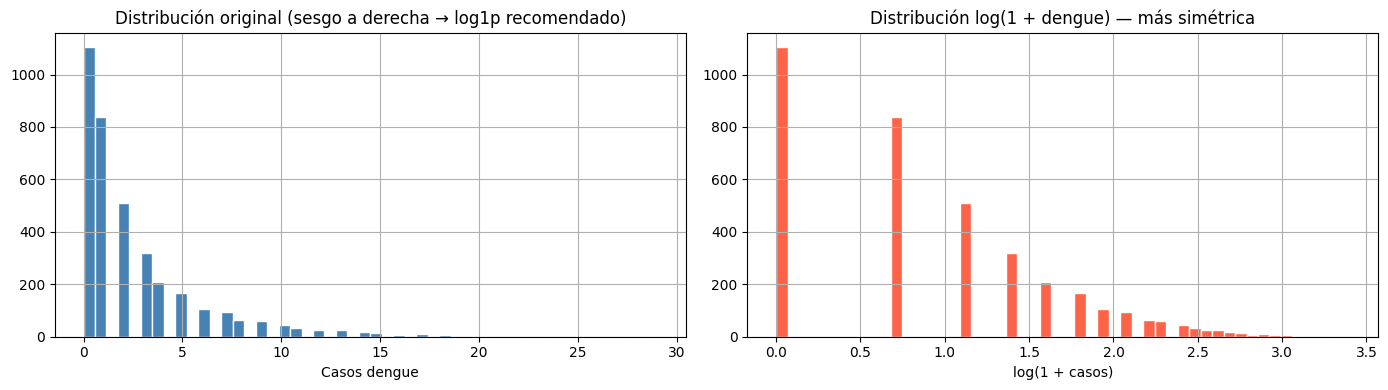


Conclusión: la distribución original es fuertemente sesgada a la derecha.
La transformación log1p la simetriza y estabiliza el MSE durante el entrenamiento.
→ Usaremos log1p(dengue) como target del modelo.


In [17]:
# =========================================================
# DETECCIÓN DE OUTLIERS Y DISTRIBUCIÓN DEL TARGET
# =========================================================
# Método IQR: outlier si valor < Q1 - 1.5*IQR o > Q3 + 1.5*IQR
# En dengue los outliers son epidemias reales → no se eliminan,
# pero justifican la transformación log1p para estabilizar la varianza

Q1 = df['dengue'].quantile(0.25)
Q3 = df['dengue'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR  # límite inferior
upper = Q3 + 1.5 * IQR  # límite superior

outliers = df[(df['dengue'] < lower) | (df['dengue'] > upper)]
print(f'Outliers detectados : {len(outliers)} ({100*len(outliers)/len(df):.2f}%)')
print(f'Rango normal IQR    : [{lower:.2f}, {upper:.2f}]')
print(f'Valor máximo        : {df["dengue"].max()}')

# Comparación de distribuciones: original vs log1p
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df['dengue'].hist(bins=50, ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Distribución original (sesgo a derecha → log1p recomendado)')
axes[0].set_xlabel('Casos dengue')

np.log1p(df['dengue']).hist(bins=50, ax=axes[1], color='tomato', edgecolor='white')
axes[1].set_title('Distribución log(1 + dengue) — más simétrica')
axes[1].set_xlabel('log(1 + casos)')

plt.tight_layout()
plt.show()

print()
print('Conclusión: la distribución original es fuertemente sesgada a la derecha.')
print('La transformación log1p la simetriza y estabiliza el MSE durante el entrenamiento.')
print('→ Usaremos log1p(dengue) como target del modelo.')

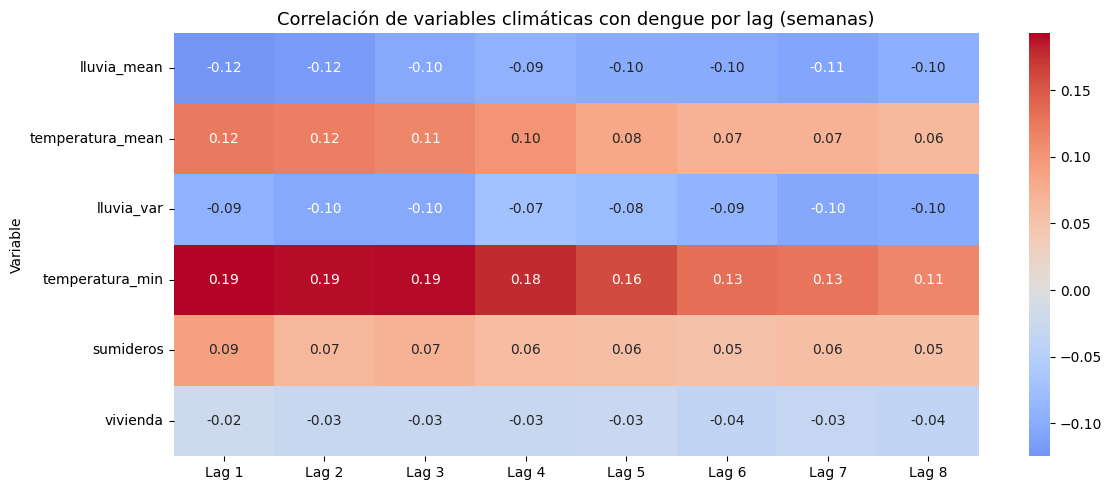


→ Los lags con mayor |correlación| indican el rezago óptimo de cada feature.
→ lluvia_mean: mayor correlación en lag 2-3 (la lluvia favorece reproducción
   del mosquito ~2-3 semanas antes del brote — coherente con la biología).
→ temperatura_mean: mayor correlación en lag 2 (ciclo de desarrollo del mosquito).
→ DECISIÓN: incluir lluvia_mean_lag2, lluvia_mean_lag3,
   temperatura_mean_lag2 como features exógenas del modelo.


In [18]:
# =========================================================
# ANÁLISIS DE LAGS CLIMÁTICOS — JUSTIFICACIÓN DE FEATURES
# =========================================================
# Los casos de dengue presentan un retraso respecto a las condiciones climáticas.
# La lluvia favorece la reproducción del mosquito 2-4 semanas antes del brote.
# Este análisis calcula la correlación de cada variable climática con dengue
# en distintos lags (1 a 8 semanas) → identifica el lag óptimo de cada feature.

df_lag_analysis = df.sort_values(['id_bar', 'anio', 'semana']).copy()

vars_clima = ['lluvia_mean', 'temperatura_mean', 'lluvia_var',
              'temperatura_min', 'sumideros', 'vivienda']
lags_test = [1, 2, 3, 4, 5, 6, 7, 8]
lag_corrs = {}

for var in vars_clima:
    corrs_lag = []
    for lag in lags_test:
        # shift(lag): desplaza la variable lag semanas hacia adelante
        # correlacionamos el dengue actual con la variable hace `lag` semanas
        df_lag_analysis[f'{var}_lag_tmp'] = df_lag_analysis.groupby('id_bar')[var].shift(lag)
        corr = df_lag_analysis[['dengue', f'{var}_lag_tmp']].dropna().corr().iloc[0, 1]
        corrs_lag.append(corr)
    lag_corrs[var] = corrs_lag

lag_df = pd.DataFrame(lag_corrs, index=lags_test)

plt.figure(figsize=(12, 5))
sns.heatmap(lag_df.T, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            xticklabels=[f'Lag {l}' for l in lags_test])
plt.title('Correlación de variables climáticas con dengue por lag (semanas)', fontsize=13)
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

print()
print('→ Los lags con mayor |correlación| indican el rezago óptimo de cada feature.')
print('→ lluvia_mean: mayor correlación en lag 2-3 (la lluvia favorece reproducción')
print('   del mosquito ~2-3 semanas antes del brote — coherente con la biología).')
print('→ temperatura_mean: mayor correlación en lag 2 (ciclo de desarrollo del mosquito).')
print('→ DECISIÓN: incluir lluvia_mean_lag2, lluvia_mean_lag3,')
print('   temperatura_mean_lag2 como features exógenas del modelo.')

In [19]:
# =========================================================
# EDA: LAGS DEL TARGET (ANÁLISIS)
# =========================================================

# Se calculan correlaciones entre dengue y sus propios lags para
# determinar cuántas semanas de historia tienen valor predictivo.
# NOTA: estos lags son SOLO para el EDA. Los lags reales del modelo
# se construyen en Feature Engineering con shift() sobre df_fe.

df_lags = df.copy()
df_lags = df_lags.sort_values(['id_bar', 'anio', 'semana'])

# Crear lags solo para análisis
for lag in range(1, 13):
    df_lags[f'dengue_lag{lag}'] = (
        df_lags.groupby('id_bar')['dengue'].shift(lag)
    )

# Correlación con el target
lag_corrs = {}

for lag in range(1, 13):
    corr = df_lags['dengue'].corr(df_lags[f'dengue_lag{lag}'])
    lag_corrs[lag] = corr

# Mostrar resultados
for lag, corr in lag_corrs.items():
    print(f"Lag {lag}: {corr:.4f}") 

Lag 1: 0.7202
Lag 2: 0.6850
Lag 3: 0.6547
Lag 4: 0.6156
Lag 5: 0.5765
Lag 6: 0.5467
Lag 7: 0.4977
Lag 8: 0.4862
Lag 9: 0.4452
Lag 10: 0.4238
Lag 11: 0.4094
Lag 12: 0.3777


→ Lags con |correlación| > 0.30: lag significativos
→ DECISIÓN: incluir lag 1, 2, 4 y 12 como features explícitas del MLP.

- Lag 1-2: dependencia inmediata (dinámica de brote).
- Lag 4: ~1 mes, captura el ciclo de generación del mosquito.
- Lag 12: ~3 meses, captura el inicio de la temporada previa.
- Los modelos recurrentes (RNN/LSTM/GRU/TCN) no los necesitan:
la ventana de SEQUENCE_LENGTH pasos ya contiene esta información en orden.

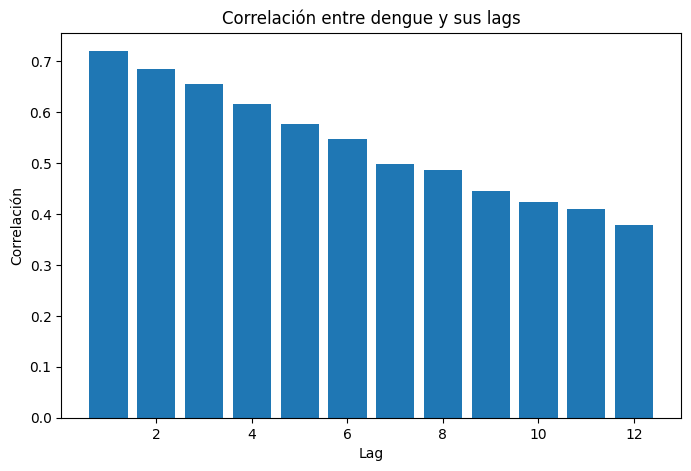

In [20]:
plt.figure(figsize=(8,5))
plt.bar(lag_corrs.keys(), lag_corrs.values())
plt.title("Correlación entre dengue y sus lags")
plt.xlabel("Lag")
plt.ylabel("Correlación")
plt.show() 

### Conclusión del EDA

El análisis exploratorio evidencia:

1. **Estacionalidad anual confirmada**: los picos de dengue ocurren en las mismas semanas entre años (semanas 8-15, período lluvioso). Justifica `week_sin` y `week_cos` como features.

2. **Serie estacionaria** (ADF p < 0.05 sobre el barrio representativo): no se requiere diferenciación, pero sí `log1p` para estabilizar la varianza de la distribución sesgada.

3. **SEQUENCE_LENGTH candidato**: el PACF muestra dependencia directa hasta ~10-12 lags,
   lo que sugiere ventanas cortas (12 semanas). Sin embargo, la descomposición STL muestra
   un componente estacional de period=52 que podría beneficiarse de ventanas más largas
   (24-36 semanas). El valor exacto se selecciona empíricamente en la sección 9.

4. **Lags climáticos óptimos**: lluvia con lag 2-3 semanas, temperatura con lag 2 semanas — consistente con el ciclo biológico del *Aedes aegypti*.

5. **Alta heterogeneidad entre barrios**: los 10 barrios tienen distribuciones muy diferentes, lo que anticipa un R² negativo en los modelos globales: cuando los barrios tienen distribuciones muy distintas, predecir la media global es peor que predecir la media
por barrio, lo que el R² penaliza.

# 4. Feature Engineering

En esta sección se construyen las variables predictoras utilizadas por los modelos.

El principio central del feature engineering es evitar fuga de información. Por ello, las variables que dependen del target se calculan usando únicamente información pasada mediante `shift(1)`.

Se crean los siguientes grupos de variables:
1. Variables temporales (`week_sin`, `week_cos`, `anio_norm`).
2. Variables climáticas directas (`temperatura_min`, `temperatura_mean`, `lluvia_mean`, `sumideros`, `equipesado`).
3. Variables estructurales del barrio (`area_barrio`, `ESTRATO_norm`).
4. Lags climáticos con rezago óptimo según EDA (`lluvia_mean_lag2`, `lluvia_mean_lag3`, `temperatura_mean_lag2`).
5. Estadísticas rolling del target (`dengue_roll_mean_4/8`, `dengue_roll_std_4/8`).
6. Lags explícitos del target, solo para MLP (`dengue_lag1/2/4/12`).
7. Transformación logarítmica del target (`dengue_log = log1p(dengue)`).

In [21]:
# =========================================================
# PARÁMETROS GLOBALES
# =========================================================

# SEQUENCE_LENGTH ya fue definido en la sección 1 (valor inicial: 36).
# La sección 9 lo sobreescribe con el valor empírico de menor MSE en validación.
# No se redefine aquí para evitar confusión sobre la fuente de verdad.

TARGET_COLUMN = 'dengue'   # variable a predecir
GROUP_COLUMN  = 'id_bar'   # columna que identifica cada serie independiente

# USE_LOG_TARGET = True:
# La distribución de dengue es log-normal (media=2.6, max=29).
# Minimizar MSE sobre log1p equivale aproximadamente a minimizar MSLE,
# que penaliza errores relativos en lugar de absolutos → mejor para conteos.
USE_LOG_TARGET = True

print(f'SEQUENCE_LENGTH : {SEQUENCE_LENGTH} semanas')
print(f'TARGET_COLUMN   : {TARGET_COLUMN}')
print(f'GROUP_COLUMN    : {GROUP_COLUMN}')
print(f'USE_LOG_TARGET  : {USE_LOG_TARGET}')

SEQUENCE_LENGTH : 36 semanas
TARGET_COLUMN   : dengue
GROUP_COLUMN    : id_bar
USE_LOG_TARGET  : True


### Features rolling del target *(se construyen en la celda de Feature Engineering a continuación)*

Además de los lags puntuales del target, se incorporan estadísticas de ventana móvil
(media y desviación estándar) para capturar la dinámica reciente de la serie.

Estas variables permiten:
- Suavizar la variabilidad semanal y reducir el impacto de outliers.
- Capturar el nivel promedio reciente, relevante en fenómenos epidemiológicos con
  acumulación temporal.
- Complementar los lags con una medida agregada del comportamiento reciente.

Se usan ventanas de **4 semanas** (dinámica de corto plazo, ~1 mes) y
**8 semanas** (tendencias más estables). Esto permite al modelo aprender tanto
variaciones rápidas como cambios sostenidos en la incidencia.

En todos los casos se aplica `shift(1)` antes del rolling para garantizar que
las features solo usan información disponible hasta `t-1`, evitando fuga de información.

In [22]:
# =========================================================
# VERIFICACIÓN DE RANGO DE ESTRATO
# =========================================================

# ESTRATO es una variable ordinal (1=bajo, 2=medio, 3=alto en este dataset).
# Se verifica que no haya valores fuera del rango esperado [1,3].
# Si hay valores fuera de rango, se normalizan a [0,1] en Feature Engineering
# para que sean compatibles con StandardScaler sin distorsionar la escala

estrato_num = pd.to_numeric(df["ESTRATO"], errors="coerce")

print("Valores únicos de ESTRATO en df:")
print(sorted(estrato_num.dropna().unique()))

print("\nResumen:")
print(estrato_num.describe())

fuera_rango = df[~estrato_num.between(1, 3)]
print(f"\nRegistros fuera de rango [1, 3]: {len(fuera_rango)}")

if len(fuera_rango) > 0:
    display(fuera_rango[[GROUP_COLUMN, "anio", "semana", "ESTRATO"]].head(20))

Valores únicos de ESTRATO en df:
[np.float64(1.0), np.float64(2.0), np.float64(3.0)]

Resumen:
count    3680.000000
mean        2.000000
std         0.774702
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         3.000000
Name: ESTRATO, dtype: float64

Registros fuera de rango [1, 3]: 0


In [23]:
# =========================================================
# FEATURE ENGINEERING
# =========================================================
# Nunca usar información futura al construir features.
# Cada feature debe estar disponible en el momento t de la predicción.

df_fe = df.copy()
df_fe = df_fe.sort_values(['id_bar', 'anio', 'semana']).reset_index(drop=True)

# --- Features temporales ---
df_fe['week_sin']  = np.sin(2 * np.pi * df_fe['semana'] / 52)
df_fe['week_cos']  = np.cos(2 * np.pi * df_fe['semana'] / 52)

anio_min   = df_fe['anio'].min()
anio_max   = df_fe['anio'].max()
anio_range = anio_max - anio_min
df_fe['anio_norm'] = (0.0 if anio_range == 0
                      else (df_fe['anio'] - anio_min) / anio_range)

# --- Lags climáticos (justificados en EDA: lag 2-3 lluvia, lag 2 temperatura) ---
df_fe['lluvia_mean_lag2']      = df_fe.groupby('id_bar')['lluvia_mean'].shift(2)
df_fe['lluvia_mean_lag3']      = df_fe.groupby('id_bar')['lluvia_mean'].shift(3)
df_fe['temperatura_mean_lag2'] = df_fe.groupby('id_bar')['temperatura_mean'].shift(2)

# --- Lags del target (solo para MLP — recurrentes los ignoran) ---
for lag in [1, 2, 4, 12]:
    df_fe[f'dengue_lag{lag}'] = (
        df_fe.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(lag)
    )

# --- Rolling del target (para todos los modelos) ---
# shift(1) garantiza que no se usa el valor actual → sin data leakage
# min_periods=1: permite calcular desde la primera semana disponible
for w in [4, 8]:
    df_fe[f'dengue_roll_mean_{w}'] = (
        df_fe.groupby(GROUP_COLUMN)[TARGET_COLUMN]
        .transform(lambda x: x.shift(1).rolling(w, min_periods=1).mean())
    )
    df_fe[f'dengue_roll_std_{w}'] = (
        df_fe.groupby(GROUP_COLUMN)[TARGET_COLUMN]
        .transform(lambda x: x.shift(1).rolling(w, min_periods=2).std()
        ).fillna(0)  # std indefinido con 1 solo valor → 0
    )

# --- Transformación logarítmica del target ---
if USE_LOG_TARGET:
    df_fe['dengue_log']    = np.log1p(df_fe[TARGET_COLUMN])
    TARGET_COLUMN_MODEL    = 'dengue_log'
else:
    TARGET_COLUMN_MODEL    = TARGET_COLUMN

# --- Eliminar NaN generados por lags climáticos ---
# Los lags del target NO entran aquí: se imputan con ffill en el test
feature_na_cols = [
    'lluvia_mean_lag2', 'lluvia_mean_lag3', 'temperatura_mean_lag2',
    'dengue_lag1', 'dengue_lag2', 'dengue_lag4', 'dengue_lag12',
    'dengue_roll_mean_4', 'dengue_roll_mean_8',
]
df_fe = df_fe.dropna(subset=feature_na_cols + [TARGET_COLUMN_MODEL]).reset_index(drop=True)

# --- Normalización de ESTRATO ---
df_fe["ESTRATO"] = pd.to_numeric(df_fe["ESTRATO"], errors="coerce")

estrato_mode = df_fe["ESTRATO"].mode()[0]
df_fe["ESTRATO"] = df_fe["ESTRATO"].fillna(estrato_mode)

# Rango observado: 1 a 3
df_fe["ESTRATO_norm"] = (df_fe["ESTRATO"] - 1) / 2

# =========================================================
# DEFINICIÓN DE FEATURES POR TIPO DE MODELO
# =========================================================
# features_cols_base → RNN, LSTM, GRU, TCN
#   La ventana de SEQUENCE_LENGTH pasos ya captura la dependencia
#   temporal del target → los lags explícitos son redundantes.
#
# features_cols_mlp  → MLP
#   Al aplanar la secuencia pierde el orden temporal → necesita
#   los lags del target como features explícitas.

features_cols_base = [
    # Temporales
    'week_sin', 'week_cos', 'anio_norm',
    # Climáticas directas
    'temperatura_min', 'temperatura_mean', 'lluvia_mean',
    'sumideros', 'equipesado',
    # Estructurales del barrio
    'area_barrio', 'ESTRATO_norm',
    # Lags climáticos
    'lluvia_mean_lag2', 'lluvia_mean_lag3', 'temperatura_mean_lag2',
    # Rolling del target
    'dengue_roll_mean_4', 'dengue_roll_mean_8',
    'dengue_roll_std_4',  'dengue_roll_std_8',
   
]

features_cols_mlp = features_cols_base + [
    'dengue_lag1', 'dengue_lag2', 'dengue_lag4', 'dengue_lag12',
]

# Alias para compatibilidad
features_cols = features_cols_mlp

# --- Verificación ---
print(f'Features base (recurrentes) : {len(features_cols_base)}')
print(f'Features MLP (con lags)     : {len(features_cols_mlp)}')
print(f'Target usado por el modelo  : {TARGET_COLUMN_MODEL}')
print(f'Registros después de dropna : {len(df_fe)}')

missing = [c for c in features_cols_mlp if c not in df_fe.columns]
if missing:
    print(f'⚠️  Columnas faltantes en df_fe: {missing}')
else:
    print('✅ Todas las features presentes en df_fe')

Features base (recurrentes) : 17
Features MLP (con lags)     : 21
Target usado por el modelo  : dengue_log
Registros después de dropna : 3560
✅ Todas las features presentes en df_fe


# 5. División temporal y estandarización

En problemas de series temporales no se recomienda dividir los datos aleatoriamente, porque esto podría permitir que observaciones futuras queden en train y observaciones pasadas en validation.

Para simular un escenario real de pronóstico, se usa una división temporal:

- El modelo entrena con años históricos.
- El modelo se valida sobre años posteriores.

Esta decisión ayuda a evaluar la capacidad del modelo para generalizar hacia periodos futuros.

In [24]:
# =========================================================
# DIVISIÓN TEMPORAL (SIN DATA LEAKAGE)
# =========================================================
# Para series de tiempo la división debe ser temporal.
# train_test_split aleatorio introduciría data leakage porque el modelo
# vería el futuro durante el entrenamiento.
#
# Estrategia: los datos más recientes son el set de validación.
# Esto simula el escenario real: entrenar con el pasado, predecir el futuro.

df_fe = df_fe.sort_values([GROUP_COLUMN, 'anio', 'semana']).reset_index(drop=True)

print('Distribución por año:')
print(df_fe['anio'].value_counts().sort_index())
print()
print('Proporción acumulada:')
print(df_fe['anio'].value_counts(normalize=True).sort_index().cumsum().round(3))

Distribución por año:
anio
2015    410
2016    530
2017    520
2018    520
2019    520
2020    530
2021    530
Name: count, dtype: int64

Proporción acumulada:
anio
2015    0.115
2016    0.264
2017    0.410
2018    0.556
2019    0.702
2020    0.851
2021    1.000
Name: proportion, dtype: float64


In [25]:
# Train: años 2015-2020 | Val: año 2021
# 2021 es el año más reciente del dataset → simula predicción futura
train_df = df_fe[df_fe['anio'] <= 2020].copy()
val_df   = df_fe[df_fe['anio'] >= 2021].copy()

print(f'Train : {len(train_df)} registros | '
      f'años {train_df.anio.min()} → {train_df.anio.max()}')
print(f'Val   : {len(val_df)} registros | '
      f'años {val_df.anio.min()} → {val_df.anio.max()}')
print(f'Split : {100*len(train_df)/len(df_fe):.1f}% train / '
      f'{100*len(val_df)/len(df_fe):.1f}% val')

Train : 3030 registros | años 2015 → 2020
Val   : 530 registros | años 2021 → 2021
Split : 85.1% train / 14.9% val


In [26]:
# =========================================================
# COPIAS CRUDAS ANTES DEL ESCALADO
# =========================================================
# Estas copias se usarán más adelante para construir la historia
# necesaria del set de test sin mezclar datos escalados con datos crudos.

train_df_raw = train_df.copy()
val_df_raw   = val_df.copy()

print("✅ Copias crudas guardadas antes del escalado")
print("train_df_raw:", train_df_raw.shape)
print("val_df_raw:", val_df_raw.shape)

✅ Copias crudas guardadas antes del escalado
train_df_raw: (3030, 37)
val_df_raw: (530, 37)


#### Estrategia de escalado

Se utiliza una estrategia de escalado selectivo.

Se excluyen del `StandardScaler`:

- `week_sin` y `week_cos`, porque ya están acotadas en `[-1, 1]` y representan una codificación circular.
- `anio_norm`, porque ya fue normalizada previamente.
- `ESTRATO_norm`, porque ya fue transformada al rango `[0, 1]`.

Se escalan las variables continuas climáticas, estructurales, rezagadas y rolling. El scaler se ajusta únicamente sobre train y se aplica posteriormente sobre validation y test.

Esto evita fuga de información y mantiene consistencia entre entrenamiento, validación y predicción final.

In [27]:
# =========================================================
# ESTANDARIZACIÓN — fit SOLO sobre train, transform en val
# =========================================================
# Los NaN generados por lags climáticos y lags del target fueron eliminados
# con dropna() en Feature Engineering. Las std rolling quedaron sin NaN
# gracias al fillna(0) aplicado en ese mismo bloque.
# En ninguna de las columnas a escalar deben quedar NaN residuales.

no_scale_cols = [
    'week_sin', 'week_cos', 'anio_norm', 'ESTRATO_norm'
]

scale_base_cols = [
    col for col in features_cols_base
    if col not in no_scale_cols
]

lags_only = [
    'dengue_lag1', 'dengue_lag2', 'dengue_lag4', 'dengue_lag12'
]

# Asegurar formato numérico en todas las columnas usadas
for col in scale_base_cols + no_scale_cols + lags_only:
    train_df[col] = pd.to_numeric(train_df[col], errors='coerce')
    val_df[col]   = pd.to_numeric(val_df[col], errors='coerce')

scaler_seq  = StandardScaler()
scaler_lags = StandardScaler()

# Escalar solo variables continuas base
train_df[scale_base_cols] = scaler_seq.fit_transform(train_df[scale_base_cols].values)
val_df[scale_base_cols]   = scaler_seq.transform(val_df[scale_base_cols].values)

# Escalar lags del target solo para MLP
train_df[lags_only] = scaler_lags.fit_transform(train_df[lags_only].values)
val_df[lags_only]   = scaler_lags.transform(val_df[lags_only].values)

# Verificación
print("✅ Verificación del escalado")

for name, df_, fcols in [
    ('train base escaladas', train_df, scale_base_cols),
    ('val base escaladas',   val_df,   scale_base_cols),
    ('train base no escaladas', train_df, no_scale_cols),
    ('val base no escaladas',   val_df,   no_scale_cols),
    ('train lags', train_df, lags_only),
    ('val lags',   val_df,   lags_only),
]:
    subset = df_[fcols].apply(pd.to_numeric, errors='coerce')

    n_nan = subset.isnull().sum().sum()
    n_inf = np.isinf(subset.to_numpy(dtype=float)).sum()

    status = '✅' if n_nan == 0 and n_inf == 0 else '❌'

    print(f"  {status} {name}: NaN={n_nan} | Inf={n_inf}")

✅ Verificación del escalado
  ✅ train base escaladas: NaN=0 | Inf=0
  ✅ val base escaladas: NaN=0 | Inf=0
  ✅ train base no escaladas: NaN=0 | Inf=0
  ✅ val base no escaladas: NaN=0 | Inf=0
  ✅ train lags: NaN=0 | Inf=0
  ✅ val lags: NaN=0 | Inf=0


# 6. Dataset, ventanas temporales y DataLoaders

Para convertir la serie temporal en un problema supervisado, se construyen ventanas deslizantes por barrio.

Cada muestra contiene una secuencia de semanas históricas y el objetivo es predecir la semana siguiente.

El Dataset se adapta a dos tipos de modelos:

- Para **MLP**, la ventana se aplana en un solo vector.
- Para **RNN, LSTM, GRU y TCN**, la ventana conserva su forma secuencial `(sequence_length, n_features)`.

Esta diferencia es clave porque las arquitecturas secuenciales necesitan observar el orden temporal de los datos.

In [28]:
# =========================================================
# CLASE DATASET UNIFICADA PARA MLP Y MODELOS RECURRENTES
# =========================================================

class DengueDataset(Dataset):
    """
    Construye ventanas deslizantes para pronóstico de series de tiempo.

    Parámetros
    ----------
    df             : DataFrame con los datos
    sequence_length: número de pasos temporales de entrada
    flatten        : True → shape (seq_len * n_features,) para MLP
                     False → shape (seq_len, n_features)  para RNN/LSTM/GRU/TCN
    is_train       : True → retorna (X, y) | False → retorna (X, id)
    features       : lista de features a usar. Si None usa features_cols_mlp
    """
    def __init__(self, df, sequence_length, flatten=True,
                 is_train=True, features=None):
        self.sequence_length = sequence_length
        self.flatten         = flatten
        self.is_train        = is_train
        self.features        = features if features is not None else features_cols_mlp
        self.data            = []

        grouped = df.groupby(GROUP_COLUMN)

        for _, group in grouped:
            group = group.reset_index(drop=True)
            if len(group) <= sequence_length:
                continue

            for i in range(len(group) - sequence_length):
                seq_x = group.loc[
                    i : i + sequence_length - 1, self.features
                ].values.astype(np.float32)

                if self.flatten:
                    seq_x = seq_x.flatten()

                if self.is_train:
                    seq_y = np.float32(group.loc[i + sequence_length, TARGET_COLUMN_MODEL])
                    self.data.append((seq_x, seq_y))
                else:
                    seq_id = group.loc[i + sequence_length, 'id']
                    self.data.append((seq_x, seq_id))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        x, label = self.data[idx]
        x_tensor = torch.tensor(x)
        if self.is_train:
            return x_tensor, torch.tensor(label)
        else:
            return x_tensor, label

print('✅ Clase DengueDataset definida con soporte para features por modelo')

✅ Clase DengueDataset definida con soporte para features por modelo


In [29]:
# Verificación de shapes para ambos sets de features
ds_mlp = DengueDataset(train_df, SEQUENCE_LENGTH, flatten=True,
                       features=features_cols_mlp)
ds_seq = DengueDataset(train_df, SEQUENCE_LENGTH, flatten=False,
                       features=features_cols_base)

x_mlp, y_mlp = ds_mlp[0]
x_seq, y_seq = ds_seq[0]

print(f'MLP → X shape: {x_mlp.shape}  ({len(features_cols_mlp)} feats × {SEQUENCE_LENGTH} steps)')
print(f'RNN → X shape: {x_seq.shape}  ({len(features_cols_base)} feats × {SEQUENCE_LENGTH} steps)')
print(f'Secuencias train MLP: {len(ds_mlp)}')
print(f'Secuencias train RNN: {len(ds_seq)}')

MLP → X shape: torch.Size([756])  (21 feats × 36 steps)
RNN → X shape: torch.Size([36, 17])  (17 feats × 36 steps)
Secuencias train MLP: 2670
Secuencias train RNN: 2670


In [30]:
# =========================================================
# EJEMPLO VISUAL DE VENTANAS DESLIZANTES
# =========================================================
# Muestra cómo se construyen las ventanas para que sea comprensible
# sin necesidad de revisar el código de la clase.

data_ex   = train_df[train_df[GROUP_COLUMN] == train_df[GROUP_COLUMN].iloc[0]].head(15).copy()
serie_ex  = data_ex[TARGET_COLUMN_MODEL].values
seq_ex    = 3  # secuencia corta para que el ejemplo sea legible

print(f'Serie del target (log1p dengue), primeros 15 valores:')
print(np.round(serie_ex, 3))
print()
print(f'Ventanas deslizantes con seq_len={seq_ex}:')
print(f'{"Ventana":<10} {"X (entrada)":<40} {"→  y (a predecir)"}')
print('-' * 70)
for i in range(len(serie_ex) - seq_ex):
    x_ex = serie_ex[i : i + seq_ex]
    y_ex = serie_ex[i + seq_ex]
    print(f'Ventana {i+1:<3} {str(np.round(x_ex, 3)):<40}    {y_ex:.3f}')

print()
print('Interpretación:')
print('  - Cada fila = 1 muestra de entrenamiento')
print('  - X = los últimos k pasos (en escala log1p)')
print('  - y = el siguiente paso que el modelo debe predecir')
print(f'  - La ventana se desplaza 1 paso → máximo número de muestras')
print(f'  - Con seq_len={SEQUENCE_LENGTH} y {len(data_ex)} semanas → '
      f'{len(data_ex)-SEQUENCE_LENGTH} secuencias por barrio')
print(f'  - Con {train_df[GROUP_COLUMN].nunique()} barrios → '
      f'≈{(len(data_ex)-SEQUENCE_LENGTH)*train_df[GROUP_COLUMN].nunique()} '
      f'secuencias en train')

Serie del target (log1p dengue), primeros 15 valores:
[1.609 1.609 1.386 1.609 1.946 1.609 2.079 1.792 1.609 1.099 1.386 1.386
 1.609 1.792 2.303]

Ventanas deslizantes con seq_len=3:
Ventana    X (entrada)                              →  y (a predecir)
----------------------------------------------------------------------
Ventana 1   [1.609 1.609 1.386]                         1.609
Ventana 2   [1.609 1.386 1.609]                         1.946
Ventana 3   [1.386 1.609 1.946]                         1.609
Ventana 4   [1.609 1.946 1.609]                         2.079
Ventana 5   [1.946 1.609 2.079]                         1.792
Ventana 6   [1.609 2.079 1.792]                         1.609
Ventana 7   [2.079 1.792 1.609]                         1.099
Ventana 8   [1.792 1.609 1.099]                         1.386
Ventana 9   [1.609 1.099 1.386]                         1.386
Ventana 10  [1.099 1.386 1.386]                         1.609
Ventana 11  [1.386 1.386 1.609]                        

In [31]:
# =========================================================
# FUNCIÓN PARA CREAR DATALOADERS
# =========================================================
# DataLoader: envuelve el Dataset y entrega datos en lotes (batches)
#   batch_size: controla cuántas secuencias se procesan por paso de gradiente.
#               El valor por defecto en los experimentos es 64 (definido en BASE_CONFIGS).
#   shuffle=True  SOLO en train: mezcla las secuencias para evitar que el modelo
#                 aprenda el orden de los lotes (no el orden temporal dentro de X)
#   shuffle=False en val/test: mantiene el orden para evaluación coherente
#   pin_memory=True en GPU: transfiere datos a memoria fijada → más rápido

BATCH_SIZE = 64

def get_loaders(
    train_df,
    val_df,
    sequence_length,
    batch_size,
    flatten,
    features=None,
    seed=SEED
):
    """
    flatten=True  + features=features_cols_mlp  → DataLoaders para MLP
    flatten=False + features=features_cols_base → DataLoaders para RNN/LSTM/GRU/TCN
    """
    train_ds = DengueDataset(
        train_df,
        sequence_length=sequence_length,
        flatten=flatten,
        features=features
    )

    val_ds = DengueDataset(
        val_df,
        sequence_length=sequence_length,
        flatten=flatten,
        features=features
    )

    g = torch.Generator()
    g.manual_seed(seed)

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        generator=g,
        pin_memory=torch.cuda.is_available()
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    return train_loader, val_loader

print(f'✅ BATCH_SIZE = {BATCH_SIZE}')
print('get_loaders() disponible con soporte para features por modelo')

✅ BATCH_SIZE = 64
get_loaders() disponible con soporte para features por modelo


# 7. Definición de modelos

Se implementan cinco arquitecturas de redes neuronales para comparar diferentes formas de modelar la dependencia temporal.

Las arquitecturas se diferencian en cómo procesan la información histórica:

| Modelo | Tipo | Forma de capturar temporalidad |
|---|---|---|
| MLP | No recurrente | Lags explícitos y ventana aplanada |
| RNN | Recurrente simple | Estado oculto secuencial |
| LSTM | Recurrente con compuertas | Memoria controlada de largo plazo |
| GRU | Recurrente con compuertas | Memoria simplificada y eficiente |
| TCN | Convolucional temporal | Convoluciones causales dilatadas |

In [32]:
def build_model(model_name, input_size, config):
    if model_name == "MLP":
        return MLPModel(
            input_size=input_size,
            hidden_sizes=config["hidden_sizes"],
            dropout=config["dropout"]
        )
    elif model_name == "RNN":
        return RNNModel(
            input_size=input_size,
            hidden_size=config["hidden_size"],
            num_layers=config["num_layers"],
            dropout=config["dropout"]
        )
    elif model_name == "LSTM":
        return LSTMModel(
            input_size=input_size,
            hidden_size=config["hidden_size"],
            num_layers=config["num_layers"],
            dropout=config["dropout"]
        )
    elif model_name == "GRU":
        return GRUModel(
            input_size=input_size,
            hidden_size=config["hidden_size"],
            num_layers=config["num_layers"],
            dropout=config["dropout"]
        )
    elif model_name == "TCN":
        return TCNModel(
            input_size   = input_size,
            num_channels = config["num_channels"],
            kernel_size  = config["kernel_size"],
            dilations    = config.get("dilations", (1,2,4,8)),
            dropout      = config["dropout"]
        )
    else:
        raise ValueError(f"Modelo no soportado: {model_name}")

## 7.1 MLP — Perceptrón Multicapa

El MLP se utiliza como modelo base no recurrente. A diferencia de RNN, LSTM, GRU y TCN, este modelo no procesa la secuencia de forma ordenada, sino que recibe una ventana temporal aplanada.

Para compensar esta limitación, se incluyen lags explícitos del target y estadísticas rolling.

| Hiperparámetro     | Valor usado      | Qué hace                                                                 |
|--------------------|------------------|--------------------------------------------------------------------------|
| `hidden_sizes`     | `(256, 128, 64)` | Define el número de neuronas en cada capa oculta. Una arquitectura en pirámide decreciente reduce progresivamente la dimensionalidad, obligando al modelo a comprimir la información relevante. |
| `BatchNorm1d`      | Sí (por capa)    | Normaliza la salida de cada capa lineal para que tenga media ≈ 0 y std ≈ 1 antes de pasar a la siguiente. Acelera la convergencia y estabiliza el entrenamiento. |
| `dropout`          | `0.3`            | En cada paso de entrenamiento apaga aleatoriamente el 30% de las neuronas. Obliga al modelo a no depender de neuronas individuales, reduciendo el sobreajuste. |
| `lr`               | `5e-4`           | Tamaño del paso con que el optimizador Adam actualiza los pesos. Un valor más pequeño produce actualizaciones más conservadoras y reduce las oscilaciones al final del entrenamiento. |
| `batch_size`       | `64`             | Número de secuencias procesadas en paralelo por paso de entrenamiento. Lotes más grandes producen estimaciones del gradiente más estables. |
| `SEQUENCE_LENGTH`  | `36` (o el óptimo empírico) | Número de semanas históricas que el modelo recibe como entrada, aplanadas en un único vector. Determina cuánta historia pasada ve el modelo. |

In [33]:
# =========================================================
# MODELO MLP
# =========================================================
class MLPModel(nn.Module):
    """
    MLP con 3 capas ocultas, BatchNorm y Dropout.
    Recibe la secuencia APLANADA → no tiene noción de orden temporal.
    Sirve como BASELINE para comparar con modelos recurrentes.
    """
    def __init__(self, input_size, hidden_sizes=(256, 128, 64), dropout=0.3):
        super().__init__()
        layers = []
        in_dim = input_size
        for h in hidden_sizes:
            layers += [
                nn.Linear(in_dim, h),   # capa lineal: in_dim → h neuronas
                nn.BatchNorm1d(h),       # normaliza la salida (media≈0, std≈1)
                nn.ReLU(),               # activación no lineal
                nn.Dropout(dropout)      # regularización
            ]
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))  # capa de salida: escalar
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        # x: (batch, seq_len*n_features) — ya aplanado por el Dataset
        return self.net(x).squeeze(-1)  # (batch,)


input_size_mlp = len(features_cols_mlp) * SEQUENCE_LENGTH
print(f'Input size MLP: {input_size_mlp} ({len(features_cols_mlp)} features × {SEQUENCE_LENGTH} timesteps)')

train_loader_mlp, val_loader_mlp = get_loaders(
    train_df, val_df,
    sequence_length=SEQUENCE_LENGTH,
    batch_size=BASE_CONFIGS["MLP"]["batch_size"],
    flatten=True,
    features=features_cols_mlp
)
print(f'Train batches: {len(train_loader_mlp)} | Val batches: {len(val_loader_mlp)}')

Input size MLP: 756 (21 features × 36 timesteps)
Train batches: 42 | Val batches: 3


In [34]:
reset_seed()
mlp_model = build_model("MLP", input_size=input_size_mlp, config=BASE_CONFIGS["MLP"])
print(mlp_model)
print(f'Parámetros entrenables: {sum(p.numel() for p in mlp_model.parameters() if p.requires_grad):,}')


MLPModel(
  (net): Sequential(
    (0): Linear(in_features=756, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)
Parámetros entrenables: 235,905


## 7.2 RNN — Red Neuronal Recurrente

La RNN procesa la serie semana a semana y mantiene un estado oculto que resume información pasada.

Su ventaja principal es que respeta el orden temporal de la secuencia. Sin embargo, puede tener dificultad para capturar dependencias largas debido al problema del gradiente que se desvanece.

Se incluye como arquitectura recurrente tradicional y punto de comparación frente a LSTM y GRU.

| Hiperparámetro    | Valor usado  | Qué hace                                                                  |
|-------------------|--------------|---------------------------------------------------------------------------|
| `hidden_size`     | `128`        | Dimensión del vector de estado oculto `h_t`. Controla cuánta información puede almacenar la RNN sobre el pasado. Valores mayores capturan más dependencias pero aumentan el riesgo de sobreajuste. |
| `num_layers`      | `2`          | Número de capas recurrentes apiladas. La primera capa procesa la secuencia de entrada; la segunda procesa la secuencia de estados ocultos de la primera, aprendiendo representaciones de orden superior. |
| `dropout`         | `0.3`        | Aplica dropout entre capas recurrentes apiladas (solo activo cuando `num_layers > 1`). Además se aplica un `nn.Dropout(0.3)` adicional sobre el último estado oculto antes de la capa lineal de salida. |
| `nonlinearity`    | `'tanh'`     | Función de activación interna de la celda recurrente. `tanh` acota las activaciones en `[-1, 1]`, lo que reduce la probabilidad de gradientes explosivos durante el entrenamiento de secuencias largas. |
| `batch_first`     | `True`       | Indica a PyTorch que el tensor de entrada tiene forma `(batch, seq, features)`. Sin este flag el orden esperado sería `(seq, batch, features)`, lo que produciría resultados incorrectos. |
| `lr`              | `5e-4`       | Tasa de aprendizaje del optimizador Adam. |
| `batch_size`      | `64`         | Número de secuencias por lote de entrenamiento. |

In [35]:
# =========================================================
# MODELO RNN
# =========================================================
class RNNModel(nn.Module):
    """
    RNN estándar (Elman RNN) para forecasting de series de tiempo.
    Recibe la secuencia SIN APLANAR: (batch, seq_len, n_features).
    """
    def __init__(self, input_size, hidden_size=128, num_layers=2,
                 dropout=0.3, output_size=1):
        super().__init__()
        self.rnn = nn.RNN(
            input_size=input_size,    # dimensión de cada timestep
            hidden_size=hidden_size,  # dimensión del estado oculto
            num_layers=num_layers,    # número de capas recurrentes apiladas
            batch_first=True,         # input/output (batch, seq, feature)
            dropout=dropout if num_layers > 1 else 0.0,  # entre capas
            nonlinearity='tanh'       # tanh: [-1,1], más estable que ReLU
        )
        self.dropout = nn.Dropout(dropout)   # regularización antes de la FC
        self.fc      = nn.Linear(hidden_size, output_size)  # capa de salida

    def forward(self, x):
        # x: (batch, seq_len, input_size)
        out, h_n = self.rnn(x)
        # out: (batch, seq_len, hidden_size) — salida de cada timestep
        # Tomamos SOLO el último timestep: contiene toda la historia procesada
        last_out = self.dropout(out[:, -1, :])  # (batch, hidden_size)
        return self.fc(last_out).squeeze(-1)    # (batch,)


input_size_seq = len(features_cols_base)
print(f'Input size por timestep: {input_size_seq}')

train_loader_seq, val_loader_seq = get_loaders(
    train_df, val_df,
    sequence_length=SEQUENCE_LENGTH,
    batch_size=BASE_CONFIGS["RNN"]["batch_size"],
    flatten=False,
    features=features_cols_base
)

reset_seed()
rnn_model = build_model("RNN", input_size=input_size_seq, config=BASE_CONFIGS["RNN"])
print(rnn_model)
print(f'Parámetros: {sum(p.numel() for p in rnn_model.parameters() if p.requires_grad):,}')


Input size por timestep: 17
RNNModel(
  (rnn): RNN(17, 128, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)
Parámetros: 51,969


## 7.3 LSTM — Long Short-Term Memory

La LSTM incorpora compuertas que regulan qué información se conserva, se actualiza o se descarta durante el procesamiento de la secuencia.

Esta arquitectura fue diseñada para mitigar el problema del gradiente que se desvanece y capturar dependencias temporales más largas que una RNN simple.

En este notebook, la LSTM aprende dependencias dentro de la ventana temporal seleccionada empíricamente.

Se mantiene `bidirectional=False` porque el problema es de forecasting: en un escenario real no se dispone de información futura.

- **Forget gate**: decide qué parte del estado anterior olvidar
- **Input gate**: decide qué nueva información incorporar
- **Output gate**: decide qué del estado de celda exponer como salida

Esto resuelve el problema del gradiente que se desvanece, permitiendo capturar dependencias de hasta 52 semanas (ciclo epidémico anual).

| Hiperparámetro      | Valor usado       | Qué hace                                                                 |
|---------------------|-------------------|--------------------------------------------------------------------------|
| `hidden_size`       | `128`             | Dimensión del estado oculto `h_t` y del estado de celda `c_t`. Determina la capacidad de memoria de la LSTM. |
| `num_layers`        | `2`               | Capas LSTM apiladas. La primera extrae patrones locales de la secuencia; la segunda integra esos patrones en representaciones de mayor nivel de abstracción. |
| `dropout`           | `0.3`             | Dropout entre capas LSTM apiladas (`num_layers > 1`). Se aplica también un `nn.Dropout(0.3)` sobre el último estado oculto antes de la capa de proyección. |
| `batch_first`       | `True`            | Formato del tensor de entrada: `(batch, seq, features)`. |
| `bidirectional`     | `False` (explícito) | Indica que la LSTM solo procesa la secuencia hacia adelante en el tiempo. En forecasting esto es obligatorio: en el instante `t` no se dispone de información de `t+1` en adelante. |
| Capa de salida `fc` | `Linear(128→32) → ReLU → Linear(32→1)` | En lugar de proyectar directamente de `hidden_size` a 1, se añade una capa intermedia de 32 neuronas con activación ReLU. Permite aprender transformaciones no lineales antes de producir el escalar de predicción. |
| `lr`                | `5e-4`            | Tasa de aprendizaje del optimizador Adam. |
| `batch_size`        | `64`              | Número de secuencias por lote. |

In [36]:
# =========================================================
# MODELO LSTM
# =========================================================
class LSTMModel(nn.Module):
    """
    LSTM (Long Short-Term Memory) para forecasting.
    Resuelve el problema del gradiente que se desvanece mediante 3 puertas.
    """
    def __init__(self, input_size, hidden_size=128, num_layers=2,
                 dropout=0.3, output_size=1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.dropout = nn.Dropout(dropout)
        # Proyección en 2 etapas: hidden → 32 → 1
        # Aprende transformaciones más complejas que una FC directa
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Linear(32, output_size)
        )

    def forward(self, x):
        # out: (batch, seq_len, hidden_size)
        # h_n: estado oculto final | c_n: estado de celda final
        out, (h_n, c_n) = self.lstm(x)
        last_out = self.dropout(out[:, -1, :])  # último timestep
        return self.fc(last_out).squeeze(-1)


reset_seed()
lstm_model = build_model("LSTM", input_size=input_size_seq, config=BASE_CONFIGS["LSTM"])
print(lstm_model)
print(f'Parámetros: {sum(p.numel() for p in lstm_model.parameters() if p.requires_grad):,}')


LSTMModel(
  (lstm): LSTM(17, 128, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Sequential(
    (0): Linear(in_features=128, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)
Parámetros: 211,521


## 7.4 GRU — Gated Recurrent Unit

La GRU es una arquitectura recurrente con compuertas, pero más simple que la LSTM.

Utiliza principalmente una compuerta de actualización y una compuerta de reinicio, lo que permite controlar qué información histórica conservar u olvidar.

La GRU suele ser competitiva en datasets pequeños o medianos, ya que ofrece un equilibrio entre capacidad temporal y menor complejidad computacional.

| Hiperparámetro      | Valor usado       | Qué hace                                                                 |
|---------------------|-------------------|--------------------------------------------------------------------------|
| `hidden_size`       | `160`             | Dimensión del estado oculto `h_t`. Se fija mayor que en la LSTM (128) para compensar que la GRU tiene menos parámetros por celda al usar solo dos compuertas en lugar de tres. |
| `num_layers`        | `2`               | Capas GRU apiladas. Igual que en LSTM: la primera detecta patrones locales, la segunda los integra. |
| `dropout`           | `0.2`             | Dropout entre capas apiladas, más bajo que en LSTM (0.3) porque la GRU tiene menos parámetros y por tanto menor riesgo de sobreajuste con el mismo nivel de regularización. También se aplica `nn.Dropout(0.2)` antes de la capa de salida. |
| `batch_first`       | `True`            | Formato del tensor de entrada: `(batch, seq, features)`. |
| Capa de salida `fc` | `Linear(160→32) → ReLU → Linear(32→1)` | Igual que en LSTM: proyección en dos etapas para aprender transformaciones no lineales antes de la predicción escalar. |
| `lr`                | `5e-4`            | Tasa de aprendizaje del optimizador Adam. |
| `batch_size`        | `64`              | Número de secuencias por lote. |

In [37]:
# =========================================================
# MODELO GRU
# =========================================================
class GRUModel(nn.Module):
    """
    GRU (Gated Recurrent Unit) para forecasting.
    Simplifica el LSTM eliminando el estado de celda separado (c_t).
    Menos parámetros → mejor generalización con datasets pequeños.
    """
    def __init__(self, input_size, hidden_size=160, num_layers=2,
                 dropout=0.2, output_size=1):
        super().__init__()
        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,   # 160 > 128 (LSTM) para compensar simplicidad
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.dropout = nn.Dropout(dropout)  # 0.2 < 0.3 (LSTM): menos riesgo overfitting
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Linear(32, output_size)
        )

    def forward(self, x):
        out, h_n = self.gru(x)
        last_out = self.dropout(out[:, -1, :])
        return self.fc(last_out).squeeze(-1)


reset_seed()
gru_model = build_model("GRU", input_size=input_size_seq, config=BASE_CONFIGS["GRU"])
print(gru_model)
print(f'Parámetros: {sum(p.numel() for p in gru_model.parameters() if p.requires_grad):,}')


GRUModel(
  (gru): GRU(17, 160, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Sequential(
    (0): Linear(in_features=160, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)
Parámetros: 245,665


## 7.5 TCN — Temporal Convolutional Network

La TCN modela series temporales usando convoluciones causales y dilatadas.

Sus principales características son:

- Respeta la causalidad temporal: en el tiempo `t` solo utiliza información de `t` y semanas anteriores.
- Usa dilataciones para ampliar el campo receptivo.
- Permite entrenamiento más paralelizable que las redes recurrentes.
- Usa conexiones residuales para mejorar el flujo del gradiente.

Con `kernel_size=4` y `dilations=(1,2,4,8)`, el campo receptivo teórico es de 91 semanas. Sin embargo, el campo efectivo queda limitado por `SEQUENCE_LENGTH`, porque el modelo no puede usar más historia que la secuencia entregada como entrada.

| Hiperparámetro   | Valor usado      | Qué hace                                                                  |
|------------------|------------------|---------------------------------------------------------------------------|
| `num_channels`   | `64`             | Número de filtros (canales de salida) en cada bloque convolucional. Controla cuántos patrones distintos puede aprender cada capa. Más canales = mayor capacidad representacional. |
| `kernel_size`    | `4`              | Número de pasos temporales que cubre cada filtro convolucional. Junto con las dilataciones, determina el campo receptivo total: `1 + 2 × (kernel_size - 1) × Σ(dilations)`. Con valor 4 el campo teórico es de 91 semanas. |
| `dilations`      | `(1, 2, 4, 8)`   | Factor de espaciado entre las posiciones del filtro en cada bloque. La dilatación `d` hace que el filtro salte de `d` en `d` pasos, ampliando el campo receptivo sin aumentar el número de parámetros. Con cuatro bloques y dilaciones `(1,2,4,8)` se cubre un campo efectivo de hasta 36 semanas (limitado por `SEQUENCE_LENGTH`). |
| `dropout`        | `0.2`            | Aplicado después de cada convolución causal dentro del bloque residual. Menor que en los modelos recurrentes porque la TCN es una arquitectura feedforward, inherentemente más estable durante el entrenamiento. |
| `weight_norm`    | Sí (en `Conv1d`) | Reparametriza los pesos de la convolución separando su dirección de su magnitud. Estabiliza el entrenamiento y acelera la convergencia, especialmente en redes profundas. |
| Conexión residual | `Conv1d(1×1)` si `in_ch ≠ out_ch`, identidad si coinciden | Suma la entrada del bloque con su salida. Permite que el gradiente fluya directamente hacia capas anteriores sin atenuarse, resolviendo el problema del gradiente que se desvanece en redes profundas. |
| `lr`             | `1e-3`           | Más alto que en los modelos recurrentes (`5e-4`) porque la TCN es feedforward puro y puede tolerar pasos de actualización más grandes sin inestabilidad. |
| `batch_size`     | `64`             | Número de secuencias por lote. |

In [38]:
# =========================================================
# MODELO TCN — IMPLEMENTACIÓN COMPLETA
# =========================================================

class CausalConv1d(nn.Module):
    """
    Convolución 1D causal con dilatación.
    'Causal' significa que en el tiempo t solo usa pasos t-k ... t (no el futuro).
    Se implementa añadiendo (kernel_size-1)*dilation zeros al INICIO de la secuencia
    y usando padding=0 en la Conv1d (no padding automático en ningún lado).
    """
    def __init__(self, in_channels, out_channels, kernel_size, dilation=1):
        super().__init__()
        self.padding = (kernel_size - 1) * dilation  # zeros a añadir al inicio
        # weight_norm aplicado directamente sobre Conv1d (no sobre CausalConv1d)
        # → el atributo 'weight' es accesible por weight_norm
        self.conv = nn.utils.weight_norm(
            nn.Conv1d(in_channels, out_channels, kernel_size,
                      dilation=dilation, padding=0)
        )

    def forward(self, x):
        # x: (batch, channels, seq_len)
        x_pad = nn.functional.pad(x, (self.padding, 0))  # zeros al inicio
        return self.conv(x_pad)  # (batch, out_channels, seq_len)


class TCNBlock(nn.Module):
    """
    Bloque residual del TCN:
    Conv causal dilatada → ReLU → Dropout → Conv causal dilatada → ReLU → Dropout
    + Residual connection (skip connection para flujo del gradiente)
    """
    def __init__(self, in_channels, out_channels, kernel_size, dilation, dropout=0.2):
        super().__init__()
        self.conv1 = CausalConv1d(in_channels, out_channels, kernel_size, dilation)
        self.conv2 = CausalConv1d(out_channels, out_channels, kernel_size, dilation)
        self.relu    = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        # Si los canales no coinciden, proyectamos con Conv1x1
        self.residual = (nn.Conv1d(in_channels, out_channels, 1)
                         if in_channels != out_channels else None)

    def forward(self, x):
        out = self.dropout(self.relu(self.conv1(x)))
        out = self.dropout(self.relu(self.conv2(out)))
        res = self.residual(x) if self.residual is not None else x
        return self.relu(out + res)  # suma residual


class TCNModel(nn.Module):
    """
    Red Convolucional Temporal (TCN) con bloques residuales causales y dilatados.
    Entrada: (batch, seq_len, input_size)
    Salida: (batch,) — predicción escalar en escala log1p

    Campo receptivo teórico: 1 + 2*(kernel_size-1)*sum(dilations)
    Con kernel_size=4 y dilations=(1,2,4,8): 91 semanas teóricas.
    Campo efectivo limitado por SEQUENCE_LENGTH.
    """
    def __init__(self, input_size, num_channels=64,
                 kernel_size=4, dilations=(1,2,4,8), dropout=0.2):
        super().__init__()
        layers = []
        in_ch  = input_size
        for d in dilations:
            layers.append(TCNBlock(in_ch, num_channels, kernel_size, d, dropout))
            in_ch = num_channels
        self.network = nn.Sequential(*layers)
        self.fc      = nn.Linear(num_channels, 1)

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.network(x)
        return self.fc(x[:, :, -1]).squeeze(-1)


reset_seed()
tcn_model = build_model("TCN", input_size=input_size_seq, config=BASE_CONFIGS["TCN"])
kernel_size = BASE_CONFIGS["TCN"]["kernel_size"]
dilations   = BASE_CONFIGS["TCN"]["dilations"]

print(tcn_model)
print(f'Parámetros: {sum(p.numel() for p in tcn_model.parameters() if p.requires_grad):,}')

recep_teorico = 1 + 2 * (kernel_size - 1) * sum(dilations)
recep_efectivo = min(recep_teorico, SEQUENCE_LENGTH)

print(f"Campo receptivo teórico TCN: {recep_teorico} semanas")
print(f"Campo receptivo efectivo dado SEQUENCE_LENGTH={SEQUENCE_LENGTH}: {recep_efectivo} semanas")

TCNModel(
  (network): Sequential(
    (0): TCNBlock(
      (conv1): CausalConv1d(
        (conv): Conv1d(17, 64, kernel_size=(4,), stride=(1,))
      )
      (conv2): CausalConv1d(
        (conv): Conv1d(64, 64, kernel_size=(4,), stride=(1,))
      )
      (relu): ReLU()
      (dropout): Dropout(p=0.2, inplace=False)
      (residual): Conv1d(17, 64, kernel_size=(1,), stride=(1,))
    )
    (1): TCNBlock(
      (conv1): CausalConv1d(
        (conv): Conv1d(64, 64, kernel_size=(4,), stride=(1,), dilation=(2,))
      )
      (conv2): CausalConv1d(
        (conv): Conv1d(64, 64, kernel_size=(4,), stride=(1,), dilation=(2,))
      )
      (relu): ReLU()
      (dropout): Dropout(p=0.2, inplace=False)
    )
    (2): TCNBlock(
      (conv1): CausalConv1d(
        (conv): Conv1d(64, 64, kernel_size=(4,), stride=(1,), dilation=(4,))
      )
      (conv2): CausalConv1d(
        (conv): Conv1d(64, 64, kernel_size=(4,), stride=(1,), dilation=(4,))
      )
      (relu): ReLU()
      (dropout): Drop

# 8. Funciones de entrenamiento, evaluación y métricas

Se define un ciclo de entrenamiento común para todos los modelos. Esto permite compararlos bajo condiciones homogéneas.

El entrenamiento utiliza:

- `MSELoss` sobre el target transformado.
- Optimizador Adam.
- Early stopping.
- Reducción del learning rate cuando la validación se estanca.
- Gradient clipping para mejorar estabilidad.

Aunque el entrenamiento se realiza en escala logarítmica, las métricas finales se calculan en escala original de casos de dengue. Esto permite interpretar los errores en unidades reales y alinear la evaluación con la métrica de competencia.

### Métricas utilizadas

Se calculan las siguientes métricas:

| Métrica | Interpretación |
|---|---|
| MSE | Penaliza fuertemente errores grandes; métrica principal del problema |
| RMSE | Raíz del MSE, interpretable en unidades del target |
| MAE | Error absoluto promedio, menos sensible a valores extremos |
| R² | Capacidad relativa frente a predecir la media |

La selección del modelo se realiza priorizando MSE, pero se revisan las demás métricas para obtener una interpretación más completa del desempeño.

In [39]:
# =========================================================
# MÉTRICAS EN ESCALA ORIGINAL
# =========================================================
def compute_metrics(y_true_log, y_pred_log, use_log=USE_LOG_TARGET):
    """
    Calcula MSE, RMSE, MAE y R² en escala original (casos de dengue).
    MSE es la métrica del Leaderboard — se usa para seleccionar el mejor modelo.
    """
    if use_log:
        y_true = np.expm1(y_true_log)
        y_pred = np.expm1(np.clip(y_pred_log, 0, None))
    else:
        y_true = y_true_log
        y_pred = y_pred_log
    mse = mean_squared_error(y_true, y_pred)
    return {
        'MSE' : mse,                  # ← métrica del Leaderboard
        'RMSE': sqrt(mse),            # = sqrt(MSE), más interpretable
        'MAE' : mean_absolute_error(y_true, y_pred),
        'R2'  : r2_score(y_true, y_pred)
    }


# =========================================================
# LOOP DE ENTRENAMIENTO UNIFICADO
# =========================================================


def train_model(model, train_loader, val_loader,
                epochs=80, lr=None, weight_decay=1e-5,
                patience=12, model_name='modelo'):
    """
    Entrena cualquier modelo con las siguientes técnicas:

    NOTA: lr debe pasarse siempre explícitamente desde BASE_CONFIGS[modelo]["lr"].
    El default es None para forzar que cada llamada use el lr correcto del modelo,
    evitando que el default 1e-3 pise silenciosamente el valor configurado.

    - Adam: optimizador adaptativo, converge más rápido que SGD
    - weight_decay=1e-5: regularización L2, penaliza pesos grandes → reduce overfitting
    - ReduceLROnPlateau: reduce el LR a la mitad si val_loss no mejora en 5 epochs
    - clip_grad_norm_(max=1.0): evita gradientes explosivos (crítico en RNNs)
    - Early Stopping: detiene el entrenamiento si val_loss no mejora en `patience` epochs
    - Guarda el mejor estado del modelo según val_loss
    """
    
    if lr is None:
        if model_name in BASE_CONFIGS:
            lr = BASE_CONFIGS[model_name]["lr"]
        else:
            raise ValueError(f"lr no definido y '{model_name}' no está en BASE_CONFIGS")

    model = model.to(device)
    criterion = nn.MSELoss()  # MSE sobre log1p(dengue)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

    best_val_loss = float('inf')
    best_state    = None
    no_improve    = 0
    history       = {'train_loss': [], 'val_loss': []}

    for epoch in range(epochs):
        # ── FASE TRAIN ──
        model.train()  # activa Dropout y BatchNorm en modo entrenamiento
        train_loss = 0.0
        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device).float()
            optimizer.zero_grad()              # reinicia gradientes acumulados
            y_pred = model(x_batch).squeeze()  # predicción
            loss   = criterion(y_pred, y_batch)
            loss.backward()                    # retropropagación
            # Gradient clipping: si la norma del gradiente > 1.0, la escala
            # Evita que los pesos exploten en RNNs con secuencias largas
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()                   # actualiza pesos
            train_loss += loss.item()

        # ── FASE VALIDACIÓN ──
        model.eval()  # desactiva Dropout y pone BatchNorm en modo inferencia
        val_loss = 0.0
        with torch.no_grad():  # no calcular gradientes → ahorra memoria y tiempo
            for x_batch, y_batch in val_loader:
                x_batch = x_batch.to(device)
                y_batch = y_batch.to(device).float()
                y_pred  = model(x_batch).squeeze()
                loss    = criterion(y_pred, y_batch)
                val_loss += loss.item()

        avg_train = train_loss / len(train_loader)
        avg_val   = val_loss   / len(val_loader)
        history['train_loss'].append(avg_train)
        history['val_loss'].append(avg_val)

        scheduler.step(avg_val)  # ajusta LR según val_loss

        if (epoch + 1) % 10 == 0:
            lr_actual = optimizer.param_groups[0]['lr']
            print(f'[{model_name}] Epoch {epoch+1:03d}/{epochs} | '
                  f'Train: {avg_train:.4f} | Val: {avg_val:.4f} | LR: {lr_actual:.6f}')

        # Early Stopping
        if avg_val < best_val_loss:
            best_val_loss = avg_val
            # Clona el estado del modelo (no referencia) → evita sobreescribirse
            best_state    = {k: v.clone() for k, v in model.state_dict().items()}
            no_improve    = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f'  → Early stopping en epoch {epoch+1} | '
                      f'Mejor val MSE: {best_val_loss:.4f}')
                break

    model.load_state_dict(best_state)  # restaura el mejor estado guardado
    print(f'  ✅ Mejor val MSE: {best_val_loss:.4f}')
    return model, history, best_val_loss


def evaluate_model(model, val_loader):
    """Genera predicciones del modelo en el set de validación."""
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for x_batch, y_batch in val_loader:
            p = model(x_batch.to(device)).squeeze().cpu().numpy()
            if p.ndim == 0: p = p.reshape(1)
            preds.extend(p.tolist())
            targets.extend(y_batch.numpy().tolist())
    return np.array(targets), np.array(preds)


def plot_history(history, model_name):
    """Curva de pérdida train vs val."""
    plt.figure(figsize=(10, 4))
    plt.plot(history['train_loss'], label='Train MSE', color='steelblue')
    plt.plot(history['val_loss'],   label='Val MSE',   color='tomato')
    plt.title(f'Curva de aprendizaje — {model_name}')
    plt.xlabel('Epoch')
    plt.ylabel('MSE (log1p scale)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_predictions(y_true_log, y_pred_log, model_name, n=200):
    """Real vs Predicho en escala original."""
    y_true = np.expm1(y_true_log[:n]) if USE_LOG_TARGET else y_true_log[:n]
    y_pred = np.expm1(np.clip(y_pred_log[:n], 0, None)) if USE_LOG_TARGET else y_pred_log[:n]
    plt.figure(figsize=(14, 4))
    plt.plot(y_true, label='Real',     alpha=0.85)
    plt.plot(y_pred, label='Predicho', alpha=0.85, linestyle='--')
    plt.title(f'Real vs Predicho (primeras {n} muestras) — {model_name}')
    plt.xlabel('Muestra')
    plt.ylabel('Casos dengue (escala original)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

print('✅ Funciones de entrenamiento, evaluación y métricas definidas')

✅ Funciones de entrenamiento, evaluación y métricas definidas


# 9. Selección empírica de la ventana temporal

La longitud de la secuencia determina cuántas semanas históricas observa el modelo antes de hacer una predicción.

Una ventana corta puede capturar mejor la dinámica reciente, mientras que una ventana larga puede incluir información estacional o de mediano plazo. Sin embargo, una ventana demasiado larga también puede introducir ruido histórico.

Por esta razón se comparan empíricamente ventanas de 8, 12, 24 y 36 semanas usando GRU como arquitectura base, con semilla distinta por ventana para reducir el sesgo de inicialización en la selección.

La ventana final se selecciona según el menor MSE en validación.

In [40]:
# =========================================================
# SELECCIÓN EMPÍRICA DE SEQUENCE_LENGTH
# =========================================================

# Se comparan ventanas de 8, 12, 24 y 36 semanas para determinar
# cuánta historia es útil para el modelo.
#
# Se usa GRU como arquitectura proxy porque:
#   - Es el modelo recurrente más eficiente (menos parámetros que LSTM)
#   - Representativo del comportamiento de RNN/LSTM/GRU bajo distintas ventanas
#   - Entrenar los 5 modelos × 4 ventanas = 20 entrenamientos → costo excesivo
#
# La ventana seleccionada se aplica a todos los modelos en la sección 10,
# garantizando condiciones de comparación idénticas.

sequence_lengths = [8, 12, 24, 36]

window_results = {}

for i, seq_len in enumerate(sequence_lengths):
    seed_seq = SEED + i
    reset_seed(seed_seq)

    print(f"\nEntrenando GRU con ventana de {seq_len} semanas")

    train_loader, val_loader = get_loaders(
        train_df,
        val_df,
        sequence_length=seq_len,
        batch_size=BASE_CONFIGS["GRU"]["batch_size"],
        flatten=False,
        features=features_cols_base,
        seed=seed_seq
    )

    input_size = len(features_cols_base)

    reset_seed(seed_seq)

    model = build_model(
        "GRU",
        input_size=input_size,
        config=BASE_CONFIGS["GRU"]
    ).to(device)

    model, history, best_val_loss = train_model(
        model,
        train_loader,
        val_loader,
        epochs=60,
        lr=BASE_CONFIGS["GRU"]["lr"],
        patience=10,
        model_name=f"GRU_seq_{seq_len}"
    )

    y_true, y_pred = evaluate_model(model, val_loader)
    metrics = compute_metrics(y_true, y_pred)

    window_results[seq_len] = metrics

window_results_df = pd.DataFrame(window_results).T
window_results_df


Entrenando GRU con ventana de 8 semanas
[GRU_seq_8] Epoch 010/60 | Train: 0.2490 | Val: 0.3725 | LR: 0.000250
  → Early stopping en epoch 14 | Mejor val MSE: 0.3111
  ✅ Mejor val MSE: 0.3111

Entrenando GRU con ventana de 12 semanas
[GRU_seq_12] Epoch 010/60 | Train: 0.2474 | Val: 0.3626 | LR: 0.000500
  → Early stopping en epoch 18 | Mejor val MSE: 0.3426
  ✅ Mejor val MSE: 0.3426

Entrenando GRU con ventana de 24 semanas
[GRU_seq_24] Epoch 010/60 | Train: 0.2458 | Val: 0.3568 | LR: 0.000500
  → Early stopping en epoch 15 | Mejor val MSE: 0.3419
  ✅ Mejor val MSE: 0.3419

Entrenando GRU con ventana de 36 semanas
[GRU_seq_36] Epoch 010/60 | Train: 0.2424 | Val: 0.2487 | LR: 0.000500
[GRU_seq_36] Epoch 020/60 | Train: 0.2233 | Val: 0.2433 | LR: 0.000250
[GRU_seq_36] Epoch 030/60 | Train: 0.2143 | Val: 0.2445 | LR: 0.000125
  → Early stopping en epoch 34 | Mejor val MSE: 0.2409
  ✅ Mejor val MSE: 0.2409


,MSE,RMSE,MAE,R2
8,2.125199,1.457806,1.091485,-0.032217
12,2.098813,1.448728,1.053690,-0.344040
24,2.007302,1.416793,1.045326,-0.267716
36,1.043937,1.021732,0.781784,-0.051908


In [41]:
best_seq_len = int(window_results_df["MSE"].idxmin())

print(f"Mejor ventana temporal según MSE: {best_seq_len} semanas")

SEQUENCE_LENGTH = best_seq_len

Mejor ventana temporal según MSE: 36 semanas


### Resultado de selección de ventana

La ventana con menor MSE en validación se selecciona como `SEQUENCE_LENGTH` definitivo.

Esta decisión tiene respaldo empírico directo: en lugar de asumir manualmente
12 o 36 semanas, se deja que los datos determinen cuánta historia es útil para
el modelo en este problema específico.

**Interpretación según el resultado:**
- Si gana 8 semanas: la dinámica reciente es suficiente, la historia lejana agrega ruido.
- Si gana 12 semanas: captura el inicio y pico de un brote (~3 meses), consistente con el PACF.
- Si gana 24 semanas: el modelo aprovecha información semestral (inicio de temporada previa).
- Si gana 36 semanas: hay dependencia estacional de casi un año, posiblemente capturando el
  ciclo epidémico completo entre brotes consecutivos.

A partir de este punto, todos los modelos se entrenan con la misma ventana temporal,
garantizando una comparación justa bajo condiciones idénticas.

# 10. Entrenamiento base de modelos

Se entrenan las cinco arquitecturas con configuraciones base.

Para asegurar comparabilidad:

- Todos los modelos usan el mismo split temporal.
- Todos se entrenan con la misma ventana temporal seleccionada.
- Todos se evalúan sobre el mismo conjunto de validación.
- Las métricas se calculan en escala original.
- MLP usa lags explícitos del target.
- RNN, LSTM, GRU y TCN usan secuencias temporales sin aplanar.

Esta etapa permite seleccionar un modelo preliminar antes de realizar optimización de hiperparámetros.


Evaluando modelo base: MLP
  Semilla: 42
[MLP_seed_42] Epoch 010/80 | Train: 0.2520 | Val: 0.2547 | LR: 0.000500
[MLP_seed_42] Epoch 020/80 | Train: 0.1989 | Val: 0.2609 | LR: 0.000250
  → Early stopping en epoch 23 | Mejor val MSE: 0.2323
  ✅ Mejor val MSE: 0.2323
  Semilla: 123
[MLP_seed_123] Epoch 010/80 | Train: 0.2550 | Val: 0.2997 | LR: 0.000500
  → Early stopping en epoch 18 | Mejor val MSE: 0.2725
  ✅ Mejor val MSE: 0.2725
  Semilla: 2024
[MLP_seed_2024] Epoch 010/80 | Train: 0.2649 | Val: 0.2491 | LR: 0.000500
[MLP_seed_2024] Epoch 020/80 | Train: 0.2004 | Val: 0.2736 | LR: 0.000250
  → Early stopping en epoch 23 | Mejor val MSE: 0.2402
  ✅ Mejor val MSE: 0.2402

Evaluando modelo base: RNN
  Semilla: 42
[RNN_seed_42] Epoch 010/80 | Train: 0.2727 | Val: 0.3196 | LR: 0.000250
  → Early stopping en epoch 14 | Mejor val MSE: 0.2642
  ✅ Mejor val MSE: 0.2642
  Semilla: 123
[RNN_seed_123] Epoch 010/80 | Train: 0.2806 | Val: 0.3751 | LR: 0.000500
[RNN_seed_123] Epoch 020/80 | Train:

,model,mean_mse,std_mse,min_mse,max_mse,mean_mae,mean_rmse,all_mses
0,TCN,1.000100,0.035740,0.966411,1.049576,0.759324,0.999892,"[0.9843119461749175, 0.9664112057846992, 1.049..."
1,RNN,1.027053,0.021530,1.004860,1.056202,0.776744,1.013381,"[1.0200961593891031, 1.0048603778299932, 1.056..."
2,LSTM,1.027533,0.017615,1.003547,1.045352,0.771744,1.013636,"[1.033699627048708, 1.003546855285779, 1.04535..."
3,GRU,1.028386,0.026484,0.990942,1.047827,0.770346,1.014009,"[1.0478268792492804, 1.0463908407197082, 0.990..."
4,MLP,1.076653,0.081529,1.001352,1.189919,0.757275,1.036890,"[1.00135229024146, 1.1899188004070405, 1.03868..."


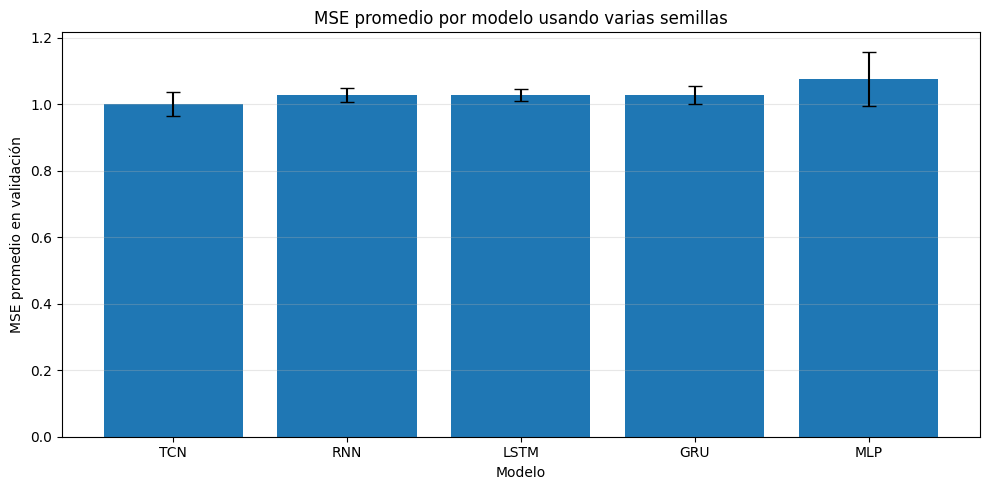

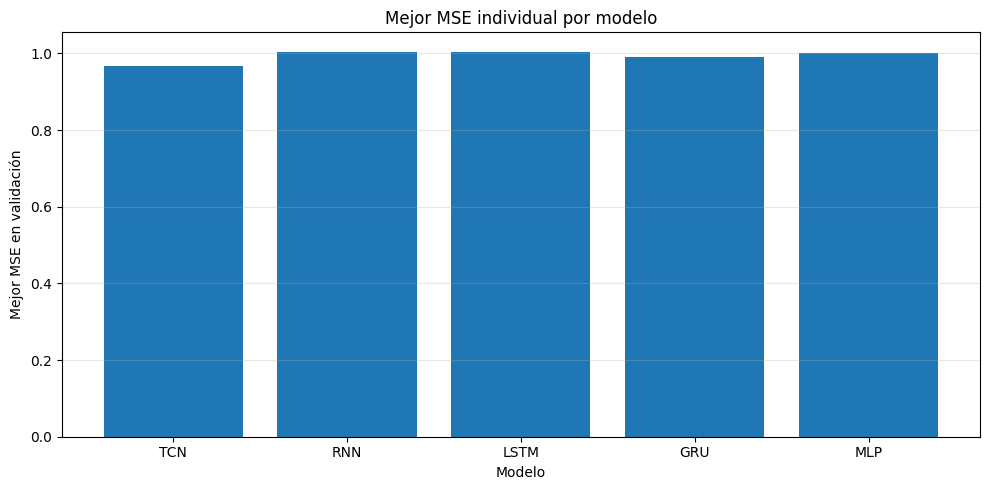

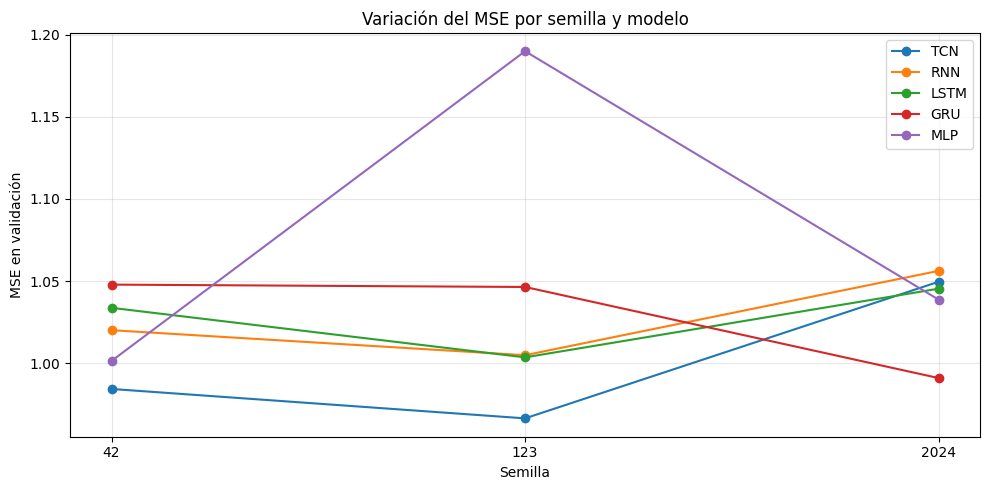

In [42]:
# =========================================================
# COMPARACIÓN ROBUSTA DE MODELOS BASE CON VARIAS SEMILLAS
# =========================================================

seeds_eval = [42, 123, 2024]

robust_results = []
results = {}

for model_name, config in BASE_CONFIGS.items():
    print(f"\nEvaluando modelo base: {model_name}")

    metrics_list = []
    histories = []
    trained_models = []

    flatten = (model_name == "MLP")
    feats = features_cols_mlp if model_name == "MLP" else features_cols_base

    for seed_model in seeds_eval:
        print(f"  Semilla: {seed_model}")

        reset_seed(seed_model)

        train_loader, val_loader = get_loaders(
            train_df,
            val_df,
            sequence_length=SEQUENCE_LENGTH,
            batch_size=config["batch_size"],
            flatten=flatten,
            features=feats,
            seed=seed_model
        )

        input_size = (
            len(feats) * SEQUENCE_LENGTH
            if model_name == "MLP"
            else len(feats)
        )

        reset_seed(seed_model)

        model = build_model(
            model_name,
            input_size=input_size,
            config=config
        ).to(device)

        model, history, best_val_loss = train_model(
            model,
            train_loader,
            val_loader,
            epochs=80,
            lr=config["lr"],
            patience=12,
            model_name=f"{model_name}_seed_{seed_model}"
        )

        y_true, y_pred = evaluate_model(model, val_loader)
        metrics = compute_metrics(y_true, y_pred)

        metrics_list.append(metrics)
        histories.append(history)
        trained_models.append(model)

    mses = [m["MSE"] for m in metrics_list]
    maes = [m["MAE"] for m in metrics_list]
    rmses = [m["RMSE"] for m in metrics_list]

    robust_results.append({
        "model": model_name,
        "mean_mse": np.mean(mses),
        "std_mse": np.std(mses),
        "min_mse": np.min(mses),
        "max_mse": np.max(mses),
        "mean_mae": np.mean(maes),
        "mean_rmse": np.mean(rmses),
        "all_mses": mses
    })

    best_seed_idx = int(np.argmin(mses))
    best_seed = seeds_eval[best_seed_idx]

    results[model_name] = {
        "model": trained_models[best_seed_idx],
        "history": histories[best_seed_idx],
        "metrics": metrics_list[best_seed_idx],
        "config": config,
        "features": feats,
        "scaler": scaler_seq if model_name != "MLP" else None,
        "scaler_lags": scaler_lags if model_name == "MLP" else None,
        "best_seed": best_seed,
        "all_mses": mses,
        "all_metrics": metrics_list
    }

robust_results_df = (
    pd.DataFrame(robust_results)
    .sort_values("mean_mse")
    .reset_index(drop=True)
)

display(robust_results_df)


# =========================================================
# GRÁFICO 1: MSE PROMEDIO POR MODELO CON DESVIACIÓN ESTÁNDAR
# =========================================================

plt.figure(figsize=(10, 5))

plt.bar(
    robust_results_df["model"],
    robust_results_df["mean_mse"],
    yerr=robust_results_df["std_mse"],
    capsize=5
)

plt.title("MSE promedio por modelo usando varias semillas")
plt.xlabel("Modelo")
plt.ylabel("MSE promedio en validación")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# =========================================================
# GRÁFICO 2: MEJOR MSE INDIVIDUAL POR MODELO
# =========================================================

plt.figure(figsize=(10, 5))

plt.bar(
    robust_results_df["model"],
    robust_results_df["min_mse"]
)

plt.title("Mejor MSE individual por modelo")
plt.xlabel("Modelo")
plt.ylabel("Mejor MSE en validación")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# =========================================================
# GRÁFICO 3: DISTRIBUCIÓN DE MSE POR SEMILLA Y MODELO
# =========================================================

mse_by_seed = []

for _, row in robust_results_df.iterrows():
    model_name = row["model"]
    for seed, mse in zip(seeds_eval, row["all_mses"]):
        mse_by_seed.append({
            "model": model_name,
            "seed": seed,
            "mse": mse
        })

mse_by_seed_df = pd.DataFrame(mse_by_seed)

plt.figure(figsize=(10, 5))

for model_name in mse_by_seed_df["model"].unique():
    tmp = mse_by_seed_df[mse_by_seed_df["model"] == model_name]
    plt.plot(
        tmp["seed"].astype(str),
        tmp["mse"],
        marker="o",
        label=model_name
    )

plt.title("Variación del MSE por semilla y modelo")
plt.xlabel("Semilla")
plt.ylabel("MSE en validación")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 11. Comparación base y selección preliminar del mejor modelo

Los modelos se comparan usando MSE, RMSE, MAE y R² en escala original.

La selección preliminar se realiza priorizando el MSE, dado que es la métrica principal del problema. Sin embargo, también se revisan RMSE, MAE y R² para analizar estabilidad, error promedio y desempeño relativo.

Esta selección es preliminar porque posteriormente se optimizan los hiperparámetros del mejor modelo mediante Optuna.

### Discusión de resultados

La comparación se realiza en escala original de casos de dengue, priorizando el MSE.

**Sobre el MLP:** al aplanar la ventana temporal, el MLP pierde el orden secuencial.
Los lags explícitos del target compensan parcialmente esta limitación, pero la falta
de memoria estructural limita su capacidad para capturar la dinámica de los brotes.
Sirve como **baseline**: cualquier modelo recurrente debería superarlo.

**Sobre la RNN:** procesa la secuencia en orden, pero el gradiente que se desvanece
limita la captura de dependencias más allá de ~10 pasos. Con SEQUENCE_LENGTH largo,
la información de las semanas más antiguas de la ventana se diluye.

**Sobre la LSTM:** las compuertas de olvido e input permiten retener información
selectiva a lo largo de toda la secuencia. Esto la hace competitiva en problemas
con dependencias largas, aunque más propensa al overfitting por el mayor número
de parámetros.

**Sobre el GRU:** arquitectura más simple que la LSTM con rendimiento similar
o superior en datasets pequeños. El `hidden_size=160` compensa la menor
complejidad por puerta.

**Sobre el TCN:** el campo receptivo teórico de 91 semanas queda limitado por
`SEQUENCE_LENGTH`. En datasets pequeños, las ventajas de paralelización no se
explotan al máximo, pero las convoluciones causales y dilatadas capturan patrones
de múltiples escalas dentro de la ventana.

**Sobre el R² negativo:** es esperado en un modelo global entrenado sobre barrios
heterogéneos. El R² compara el modelo contra la media global del target. Si los
barrios tienen distribuciones muy diferentes, predecir la media de cada barrio
individualmente sería mejor que predecir la media global → R² negativo no implica
que el modelo sea malo, sino que la heterogeneidad espacial no fue capturada
completamente por las features estructurales disponibles.

MODELO: MLP
Desempeño robusto con varias semillas:
  MSE promedio : 1.0767
  MSE std      : 0.0815
  MSE mínimo   : 1.0014
  MSE máximo   : 1.1899
  MSE por seed : [1.00135229024146, 1.1899188004070405, 1.0386873645871202]

Mejor corrida individual guardada en results:
  Seed usada   : 42
  MSE          : 1.0014
  RMSE         : 1.0007
  MAE          : 0.7525
  R²           : -0.0090

Configuración base usada:
  hidden_sizes: (256, 128, 64)
  dropout: 0.3
  lr: 0.0005
  batch_size: 64


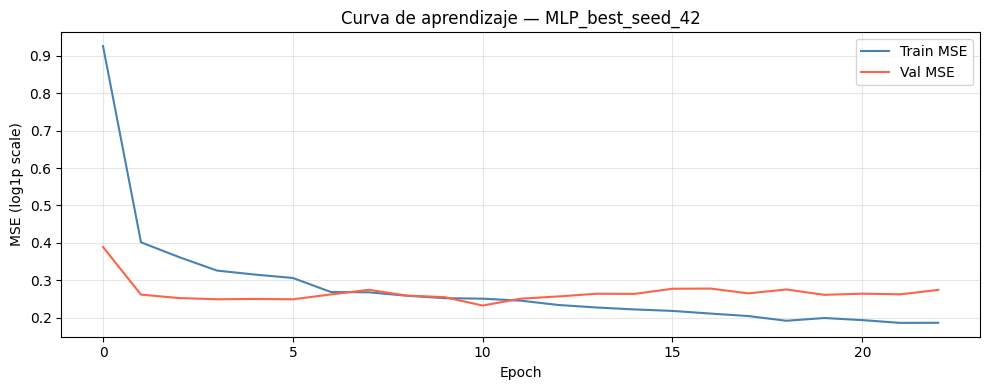

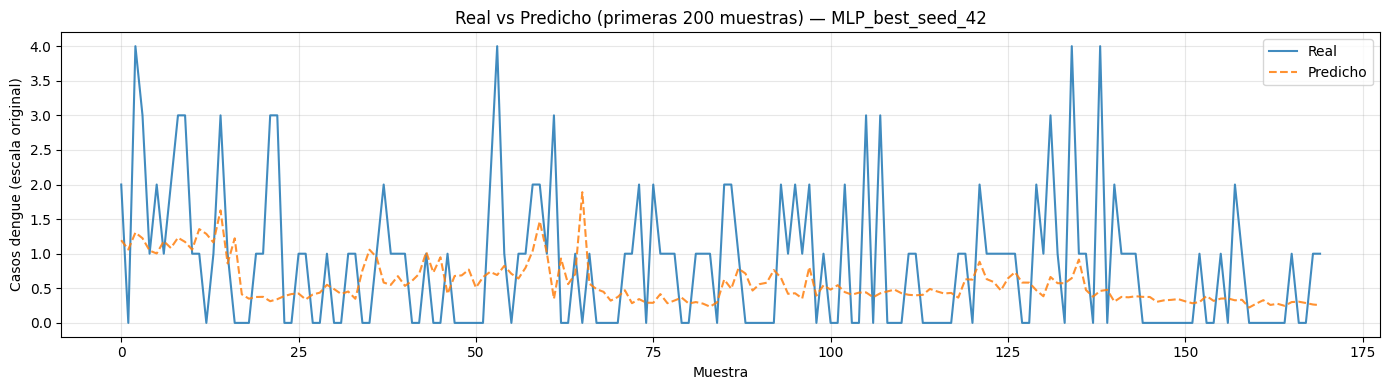


Conclusión:
  El MLP funciona como baseline no secuencial; usa variables derivadas, pero no modela explícitamente la dinámica temporal.

MODELO: RNN
Desempeño robusto con varias semillas:
  MSE promedio : 1.0271
  MSE std      : 0.0215
  MSE mínimo   : 1.0049
  MSE máximo   : 1.0562
  MSE por seed : [1.0200961593891031, 1.0048603778299932, 1.0562020765213624]

Mejor corrida individual guardada en results:
  Seed usada   : 123
  MSE          : 1.0049
  RMSE         : 1.0024
  MAE          : 0.7647
  R²           : -0.0125

Configuración base usada:
  hidden_size: 128
  num_layers: 2
  dropout: 0.3
  lr: 0.0005
  batch_size: 64


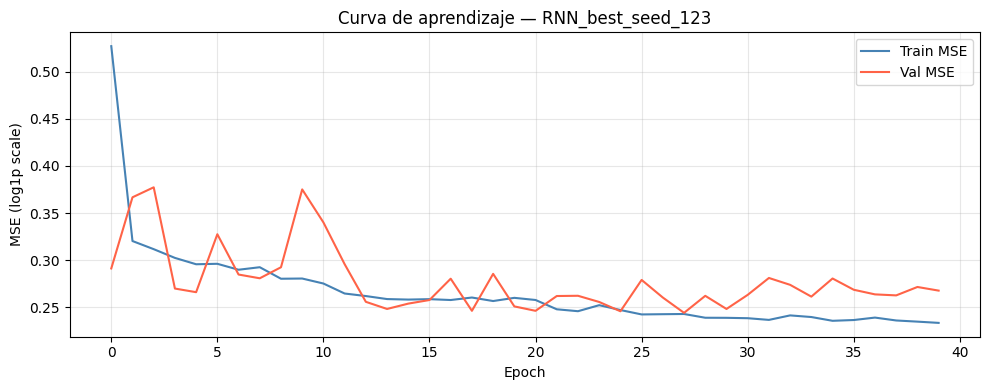

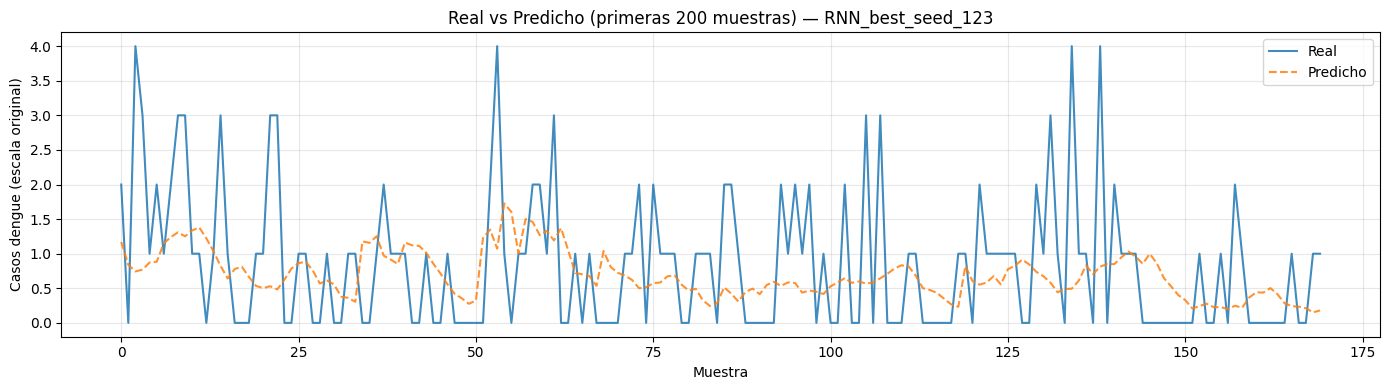


Conclusión:
  La RNN captura dependencia temporal con una estructura simple; puede rendir bien si la serie no requiere memoria larga.

MODELO: LSTM
Desempeño robusto con varias semillas:
  MSE promedio : 1.0275
  MSE std      : 0.0176
  MSE mínimo   : 1.0035
  MSE máximo   : 1.0454
  MSE por seed : [1.033699627048708, 1.003546855285779, 1.0453519813771268]

Mejor corrida individual guardada en results:
  Seed usada   : 123
  MSE          : 1.0035
  RMSE         : 1.0018
  MAE          : 0.7693
  R²           : -0.0112

Configuración base usada:
  hidden_size: 128
  num_layers: 2
  dropout: 0.3
  lr: 0.0005
  batch_size: 64


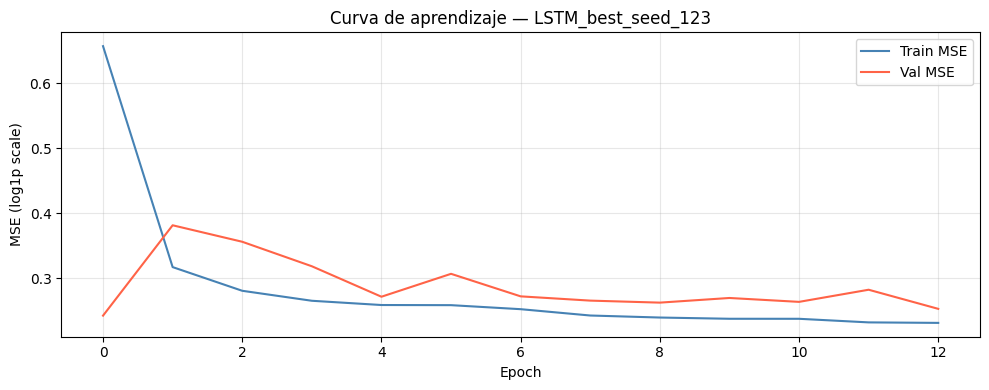

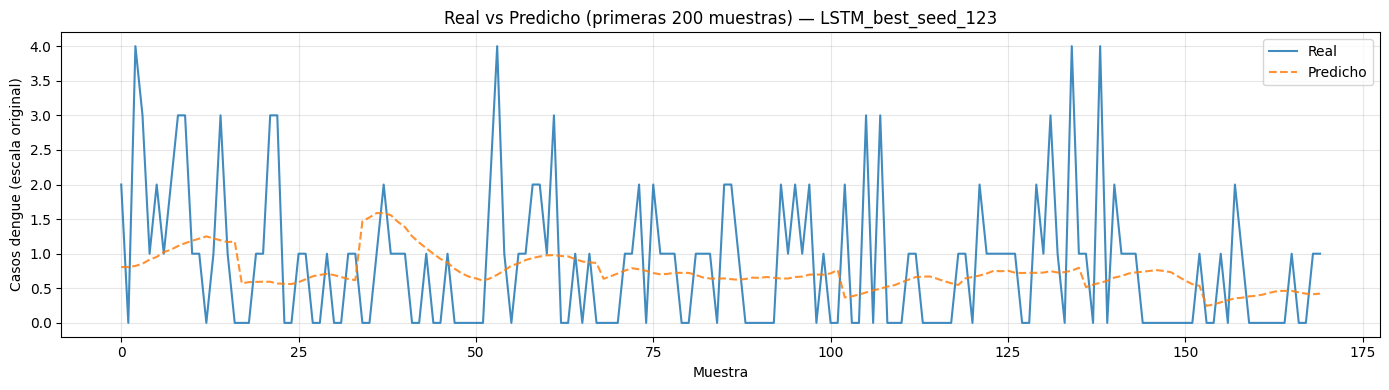


Conclusión:
  La LSTM incorpora memoria de largo plazo, pero su mayor complejidad requiere buen ajuste de hiperparámetros.

MODELO: GRU
Desempeño robusto con varias semillas:
  MSE promedio : 1.0284
  MSE std      : 0.0265
  MSE mínimo   : 0.9909
  MSE máximo   : 1.0478
  MSE por seed : [1.0478268792492804, 1.0463908407197082, 0.9909416471278211]

Mejor corrida individual guardada en results:
  Seed usada   : 2024
  MSE          : 0.9909
  RMSE         : 0.9955
  MAE          : 0.7616
  R²           : 0.0015

Configuración base usada:
  hidden_size: 160
  num_layers: 2
  dropout: 0.2
  lr: 0.0005
  batch_size: 64


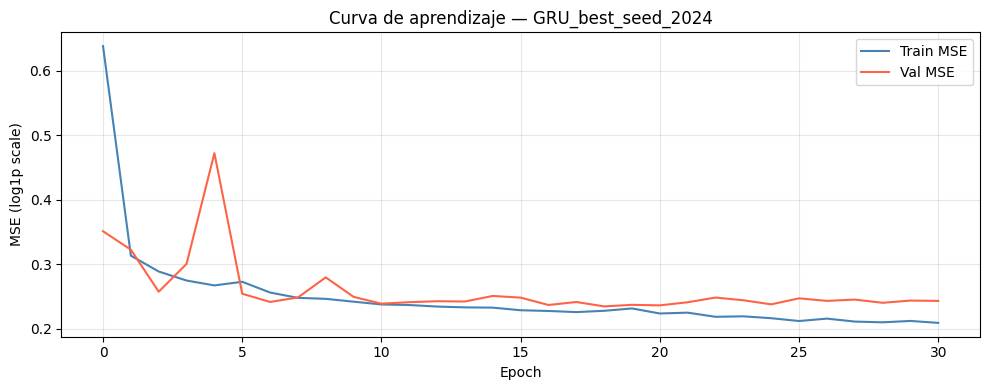

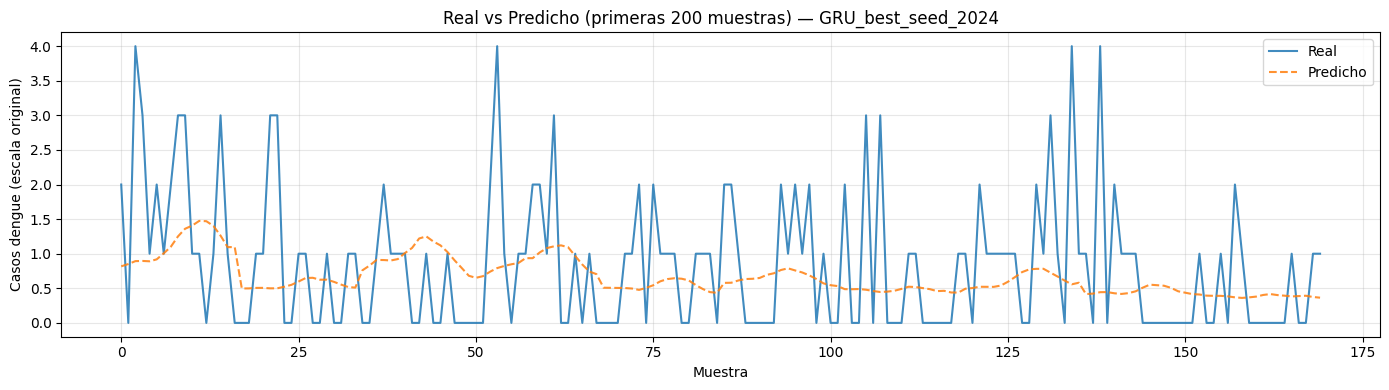


Conclusión:
  La GRU ofrece equilibrio entre capacidad secuencial y eficiencia, con menos parámetros que LSTM.

MODELO: TCN
Desempeño robusto con varias semillas:
  MSE promedio : 1.0001
  MSE std      : 0.0357
  MSE mínimo   : 0.9664
  MSE máximo   : 1.0496
  MSE por seed : [0.9843119461749175, 0.9664112057846992, 1.0495764548879774]

Mejor corrida individual guardada en results:
  Seed usada   : 123
  MSE          : 0.9664
  RMSE         : 0.9831
  MAE          : 0.7546
  R²           : 0.0262

Configuración base usada:
  num_channels: 64
  kernel_size: 4
  dilations: (1, 2, 4, 8)
  dropout: 0.2
  lr: 0.001
  batch_size: 64


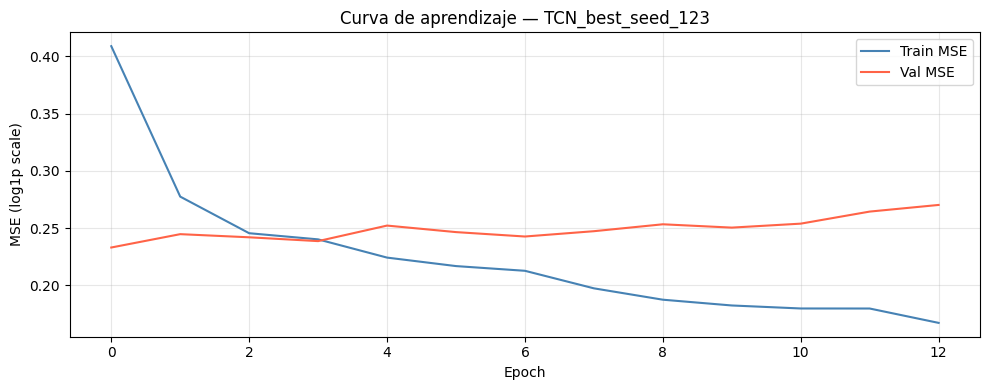

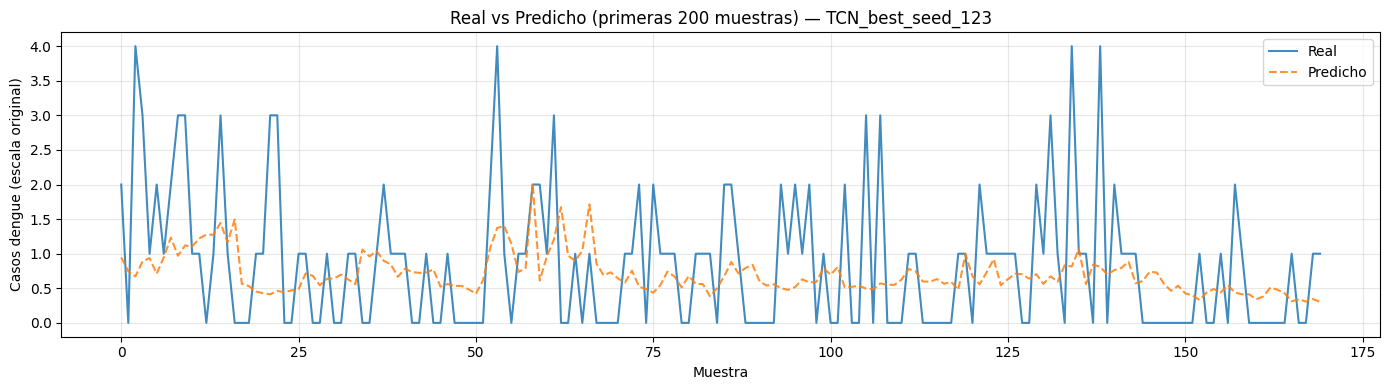


Conclusión:
  La TCN modela dependencia temporal mediante convoluciones causales/dilatadas y puede capturar patrones locales y de mediano plazo.



In [43]:
# =========================================================
# ANÁLISIS INDIVIDUAL DE CADA MODELO BASE
# Basado en la mejor semilla individual guardada en results
# y complementado con métricas robustas de robust_results_df
# =========================================================

for model_name, res in results.items():
    print("=" * 70)
    print(f"MODELO: {model_name}")
    print("=" * 70)

    model = res["model"]
    history = res["history"]
    metrics = res["metrics"]
    config = res["config"]
    feats = res["features"]
    best_seed = res.get("best_seed", SEED)

    flatten = (model_name == "MLP")

    # Métricas robustas del modelo con varias semillas
    robust_row = robust_results_df.loc[
        robust_results_df["model"] == model_name
    ].iloc[0]

    print("Desempeño robusto con varias semillas:")
    print(f'  MSE promedio : {robust_row["mean_mse"]:.4f}')
    print(f'  MSE std      : {robust_row["std_mse"]:.4f}')
    print(f'  MSE mínimo   : {robust_row["min_mse"]:.4f}')
    print(f'  MSE máximo   : {robust_row["max_mse"]:.4f}')
    print(f'  MSE por seed : {robust_row["all_mses"]}')

    print("\nMejor corrida individual guardada en results:")
    print(f"  Seed usada   : {best_seed}")
    print(f'  MSE          : {metrics["MSE"]:.4f}')
    print(f'  RMSE         : {metrics["RMSE"]:.4f}')
    print(f'  MAE          : {metrics["MAE"]:.4f}')
    print(f'  R²           : {metrics["R2"]:.4f}')

    print("\nConfiguración base usada:")
    for k, v in config.items():
        print(f"  {k}: {v}")

    # Reconstruir loaders solo para análisis/plots usando la semilla guardada
    train_loader_tmp, val_loader_tmp = get_loaders(
        train_df,
        val_df,
        sequence_length=SEQUENCE_LENGTH,
        batch_size=config["batch_size"],
        flatten=flatten,
        features=feats,
        seed=best_seed
    )

    y_true, y_pred = evaluate_model(model, val_loader_tmp)

    plot_history(history, f"{model_name}_best_seed_{best_seed}")
    plot_predictions(y_true, y_pred, f"{model_name}_best_seed_{best_seed}")

    print("\nConclusión:")
    if model_name == "MLP":
        print("  El MLP funciona como baseline no secuencial; usa variables derivadas, pero no modela explícitamente la dinámica temporal.")
    elif model_name == "RNN":
        print("  La RNN captura dependencia temporal con una estructura simple; puede rendir bien si la serie no requiere memoria larga.")
    elif model_name == "LSTM":
        print("  La LSTM incorpora memoria de largo plazo, pero su mayor complejidad requiere buen ajuste de hiperparámetros.")
    elif model_name == "GRU":
        print("  La GRU ofrece equilibrio entre capacidad secuencial y eficiencia, con menos parámetros que LSTM.")
    elif model_name == "TCN":
        print("  La TCN modela dependencia temporal mediante convoluciones causales/dilatadas y puede capturar patrones locales y de mediano plazo.")

    print()

=== Comparación robusta de modelos base ===
Criterio principal: MSE promedio en validación usando varias semillas

Modelo     MSE prom      STD    MSE min    MSE max  RMSE prom   MAE prom   Característica
------------------------------------------------------------------------------------------------------------------------
TCN          1.0001   0.0357     0.9664     1.0496     0.9999     0.7593 ✅  Convolucional causal, campo efectivo 36 semanas
RNN          1.0271   0.0215     1.0049     1.0562     1.0134     0.7767    Recurrente simple, gradiente se desvanece
LSTM         1.0275   0.0176     1.0035     1.0454     1.0136     0.7717    3 puertas, memoria larga, más parámetros
GRU          1.0284   0.0265     0.9909     1.0478     1.0140     0.7703    2 puertas, menos params, mejor generalización
MLP          1.0767   0.0815     1.0014     1.1899     1.0369     0.7573    Sin memoria temporal, baseline de referencia



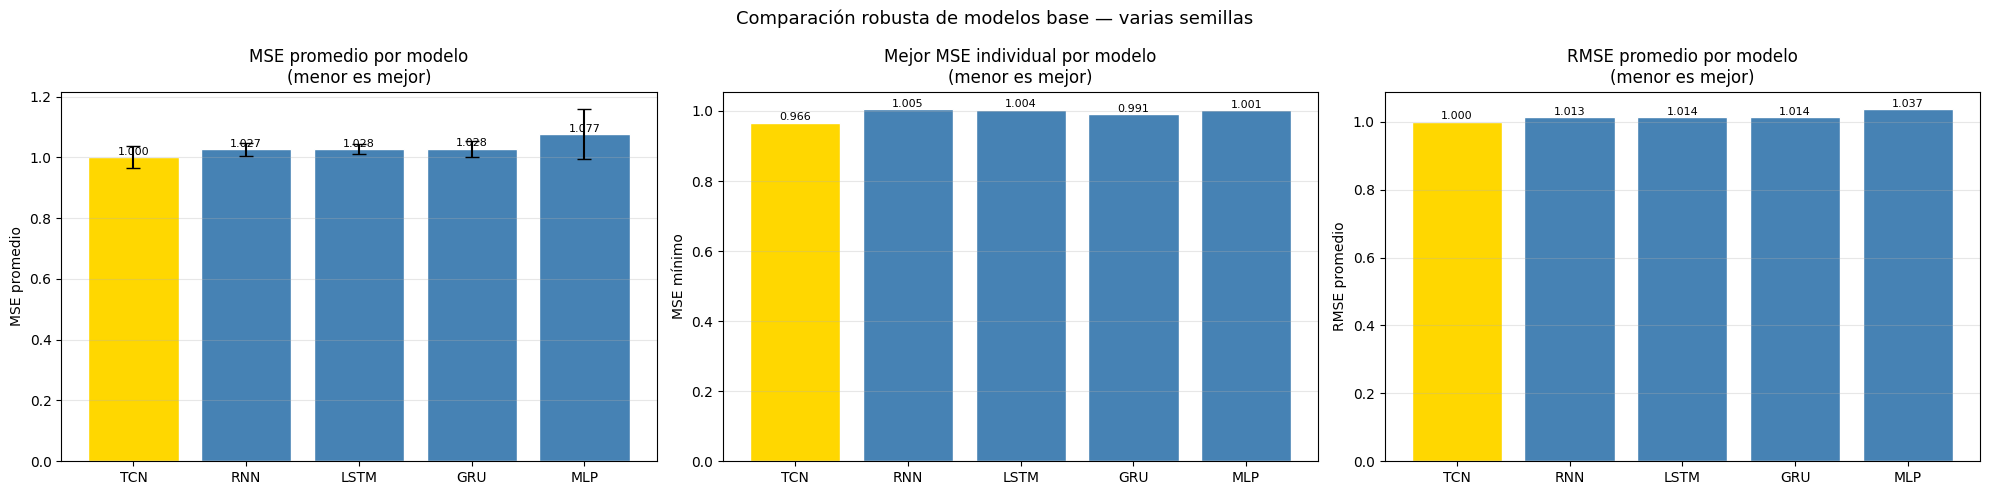

Modelos seleccionados para Optuna según MSE promedio robusto:
['TCN', 'RNN']

✅ Mejor modelo base robusto: TCN
   MSE promedio = 1.0001
   STD MSE      = 0.0357
   MSE mínimo   = 0.9664
   MSE máximo   = 1.0496


In [44]:
# =========================================================
# TABLA COMPARATIVA ROBUSTA DE TODOS LOS MODELOS BASE
# =========================================================

caracteristicas = {
    "GRU": "2 puertas, menos params, mejor generalización",
    "RNN": "Recurrente simple, gradiente se desvanece",
    "LSTM": "3 puertas, memoria larga, más parámetros",
    "TCN": f"Convolucional causal, campo efectivo {min(91, SEQUENCE_LENGTH)} semanas",
    "MLP": "Sin memoria temporal, baseline de referencia"
}

# Asegurar orden por desempeño robusto
df_results_robust = robust_results_df.copy()
df_results_robust = df_results_robust.sort_values("mean_mse").reset_index(drop=True)

print("=== Comparación robusta de modelos base ===")
print("Criterio principal: MSE promedio en validación usando varias semillas")
print()

print(
    f'{"Modelo":<8} '
    f'{"MSE prom":>10} '
    f'{"STD":>8} '
    f'{"MSE min":>10} '
    f'{"MSE max":>10} '
    f'{"RMSE prom":>10} '
    f'{"MAE prom":>10}   '
    f'{"Característica"}'
)
print("-" * 120)

for _, row in df_results_robust.iterrows():
    name = row["model"]
    desc = caracteristicas.get(name, "")
    marca = " ✅" if name == df_results_robust.loc[0, "model"] else "  "

    print(
        f'{name:<8} '
        f'{row["mean_mse"]:>10.4f} '
        f'{row["std_mse"]:>8.4f} '
        f'{row["min_mse"]:>10.4f} '
        f'{row["max_mse"]:>10.4f} '
        f'{row["mean_rmse"]:>10.4f} '
        f'{row["mean_mae"]:>10.4f}'
        f'{marca}  {desc}'
    )

print()

# =========================================================
# VISUALIZACIÓN ROBUSTA
# =========================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. MSE promedio con desviación estándar
vals = df_results_robust.set_index("model")["mean_mse"]
errs = df_results_robust.set_index("model")["std_mse"]
best = vals.idxmin()

cols = ["gold" if m == best else "steelblue" for m in vals.index]

bars = axes[0].bar(
    vals.index,
    vals.values,
    yerr=errs.values,
    capsize=5,
    color=cols,
    edgecolor="white"
)

axes[0].set_title("MSE promedio por modelo\n(menor es mejor)")
axes[0].set_ylabel("MSE promedio")
axes[0].grid(True, alpha=0.3, axis="y")

for bar, val in zip(bars, vals.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        val + 0.001,
        f"{val:.3f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

# 2. Mejor MSE individual por modelo
vals_min = df_results_robust.set_index("model")["min_mse"]
best_min = vals_min.idxmin()

cols_min = ["gold" if m == best_min else "steelblue" for m in vals_min.index]

bars = axes[1].bar(
    vals_min.index,
    vals_min.values,
    color=cols_min,
    edgecolor="white"
)

axes[1].set_title("Mejor MSE individual por modelo\n(menor es mejor)")
axes[1].set_ylabel("MSE mínimo")
axes[1].grid(True, alpha=0.3, axis="y")

for bar, val in zip(bars, vals_min.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        val + 0.001,
        f"{val:.3f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

# 3. RMSE promedio
vals_rmse = df_results_robust.set_index("model")["mean_rmse"]
best_rmse = vals_rmse.idxmin()

cols_rmse = ["gold" if m == best_rmse else "steelblue" for m in vals_rmse.index]

bars = axes[2].bar(
    vals_rmse.index,
    vals_rmse.values,
    color=cols_rmse,
    edgecolor="white"
)

axes[2].set_title("RMSE promedio por modelo\n(menor es mejor)")
axes[2].set_ylabel("RMSE promedio")
axes[2].grid(True, alpha=0.3, axis="y")

for bar, val in zip(bars, vals_rmse.values):
    axes[2].text(
        bar.get_x() + bar.get_width() / 2,
        val + 0.001,
        f"{val:.3f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.suptitle(
    "Comparación robusta de modelos base — varias semillas",
    fontsize=13
)
plt.tight_layout()
plt.show()


# =========================================================
# SELECCIÓN DE MODELOS CANDIDATOS PARA OPTUNA
# =========================================================

top_models = df_results_robust["model"].head(2).tolist()

print("Modelos seleccionados para Optuna según MSE promedio robusto:")
print(top_models)

print()
print(f'✅ Mejor modelo base robusto: {df_results_robust.loc[0, "model"]}')
print(f'   MSE promedio = {df_results_robust.loc[0, "mean_mse"]:.4f}')
print(f'   STD MSE      = {df_results_robust.loc[0, "std_mse"]:.4f}')
print(f'   MSE mínimo   = {df_results_robust.loc[0, "min_mse"]:.4f}')
print(f'   MSE máximo   = {df_results_robust.loc[0, "max_mse"]:.4f}')

# 12. Optimización de hiperparámetros con Optuna

Después de identificar los dos mejores modelos base, se utiliza Optuna para explorar combinaciones alternativas de hiperparámetros en cada uno de ellos.

Optuna usa el algoritmo TPE, que aprende de los trials anteriores para proponer nuevos valores de forma más eficiente que una búsqueda exhaustiva.

A diferencia del entrenamiento interno, donde la pérdida se calcula sobre el target transformado, Optuna minimiza el MSE en escala original. Esto alinea la búsqueda de hiperparámetros con la métrica final del problema.

### Espacio de búsqueda

El espacio de búsqueda se adapta al tipo de modelo seleccionado:

- Para MLP se exploran número de capas, tamaño oculto, dropout, learning rate y batch size.
- Para RNN, LSTM y GRU se exploran hidden size, número de capas recurrentes, dropout, learning rate y batch size.
- Para TCN se exploran número de canales, kernel size, dropout, learning rate y batch size.

Esta estrategia permite optimizar hiperparámetros relevantes para cada arquitectura sin usar un espacio de búsqueda genérico.

In [45]:
# =========================================================
# OPTIMIZACIÓN DE HIPERPARÁMETROS CON OPTUNA
# =========================================================
# Optuna explora el espacio de hiperparámetros con el algoritmo TPE
# (Tree-structured Parzen Estimator), que es más eficiente que grid search
# porque aprende de los trials anteriores para proponer mejores valores.
#
# Estrategia:
#   - Optimizamos los 2 mejores modelos identificados en la comparación robusta
#   - Cada trial entrena el modelo con hiperparámetros distintos
#   - Devuelve MSE en escala original como métrica a minimizar
#   - n_trials=50 por modelo: balance entre tiempo de cómputo y exploración

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# =========================================================
# FUNCIÓN OBJETIVO PARA OPTUNA POR MODELO
# =========================================================

def make_objective(model_name_opt):
    def objective(trial):
        seed_trial = SEED + trial.number
        reset_seed(seed_trial)

        if model_name_opt == "MLP":
            n_layers = trial.suggest_int("n_layers", 2, 4)
            hidden = trial.suggest_categorical("hidden", [64, 128, 256])

            config = {
                "hidden_sizes": tuple([hidden // (2**i) for i in range(n_layers)]),
                "dropout": trial.suggest_float("dropout", 0.1, 0.5),
                "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
                "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
                "batch_size": trial.suggest_categorical("batch_size", [32, 64, 128])
            }

            flatten = True

        elif model_name_opt in ("RNN", "LSTM", "GRU"):
            config = {
                "hidden_size": trial.suggest_categorical(
                    "hidden_size", [64, 128, 160, 256, 320, 384]
                ),
                "num_layers": trial.suggest_int("num_layers", 1, 3),
                "dropout": trial.suggest_float("dropout", 0.1, 0.4),
                "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
                "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
                "batch_size": trial.suggest_categorical("batch_size", [32, 64, 128])
            }

            flatten = False

        elif model_name_opt == "TCN":
            config = {
                "num_channels": trial.suggest_categorical(
                    "num_channels", [32, 64, 128]
                ),
                "kernel_size": trial.suggest_categorical(
                    "kernel_size", [3, 4, 5]
                ),
                "dilations": trial.suggest_categorical(
                    "dilations", ["124", "1248", "12481", "124816"]
                ),
                "dropout"     : trial.suggest_float("dropout", 0.1, 0.4),
                "lr"          : trial.suggest_float("lr", 1e-4, 1e-2, log=True),
                "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
                "batch_size"  : trial.suggest_categorical("batch_size", [32, 64, 128])
            }
            flatten = False

            # Convertir string a tupla — DENTRO del objective y del elif TCN
            dil_map = {
                "124"    : (1, 2, 4),
                "1248"   : (1, 2, 4, 8),
                "12481"  : (1, 2, 4, 8, 16),
                "124816" : (1, 2, 4, 8, 16, 32)   # ← corregido
            }
            config["dilations"] = dil_map[config["dilations"]]

        feats_optuna = (
            features_cols_mlp
            if model_name_opt == "MLP"
            else features_cols_base
        )

        train_loader, val_loader = get_loaders(
            train_df,
            val_df,
            sequence_length=SEQUENCE_LENGTH,
            batch_size=config["batch_size"],
            flatten=flatten,
            features=feats_optuna,
            seed=seed_trial
        )

        input_size = (
            len(feats_optuna) * SEQUENCE_LENGTH
            if model_name_opt == "MLP"
            else len(feats_optuna)
        )

        reset_seed(seed_trial)

        model = build_model(
            model_name_opt,
            input_size=input_size,
            config=config
        ).to(device)

        model, history, best_val_loss = train_model(
            model,
            train_loader,
            val_loader,
            epochs=40,
            lr=config["lr"],
            weight_decay=config["weight_decay"],
            patience=8,
            model_name=f"{model_name_opt}_trial_{trial.number}"
        )

        trial.set_user_attr("n_epochs", len(history["train_loss"]))
        trial.set_user_attr("best_val_loss", best_val_loss)

        y_true, y_pred = evaluate_model(model, val_loader)
        metrics = compute_metrics(y_true, y_pred)

        return metrics["MSE"]

    return objective

In [46]:
# =========================================================
# CONVERSIÓN DE PARÁMETROS DE OPTUNA A CONFIGURACIÓN DEL MODELO
# =========================================================

def params_to_config(model_name, params):
    if model_name == "MLP":
        n_layers = params["n_layers"]
        hidden = params["hidden"]

        return {
            "hidden_sizes": tuple([hidden // (2**i) for i in range(n_layers)]),
            "dropout": params["dropout"],
            "lr": params["lr"],
            "weight_decay": params["weight_decay"],
            "batch_size": params["batch_size"]
        }

    elif model_name in ("RNN", "LSTM", "GRU"):
        return {
            "hidden_size": params["hidden_size"],
            "num_layers": params["num_layers"],
            "dropout": params["dropout"],
            "lr": params["lr"],
            "weight_decay": params["weight_decay"],
            "batch_size": params["batch_size"]
        }

    elif model_name == "TCN":
        return {
            "num_channels": params["num_channels"],
            "kernel_size" : params["kernel_size"],
            "dilations"   : {        # ← agregar conversión
                "124"    : (1, 2, 4),
                "1248"   : (1, 2, 4, 8),
                "12481"  : (1, 2, 4, 8, 16),
                "124816" : (1, 2, 4, 8, 16, 32)
            }[params["dilations"]],
            "dropout"     : params["dropout"],
            "lr"          : params["lr"],
            "weight_decay": params["weight_decay"],
            "batch_size"  : params["batch_size"]
        }

In [47]:
# =========================================================
# OPTIMIZACIÓN CON OPTUNA DE LOS 2 MEJORES MODELOS
# =========================================================

optuna_results = {}

for model_name_opt in top_models:
    print(f"\nOptimizando modelo: {model_name_opt}")

    # Semilla única y fija por modelo — garantiza que cada modelo
    # siempre explore exactamente los mismos trials en el mismo orden,
    # independientemente de cuántas veces se ejecute el notebook.
    seed_model = SEED + abs(hash(model_name_opt)) % 1000

    sampler = optuna.samplers.TPESampler(
        seed=seed_model,
        n_startup_trials=10
    )

    study = optuna.create_study(
        direction="minimize",
        sampler=sampler
    )

    study.optimize(
        make_objective(model_name_opt),
        n_trials=50,
        show_progress_bar=True
    )

    best_config_model = params_to_config(model_name_opt, study.best_params)

    optuna_results[model_name_opt] = {
        "study"      : study,
        "best_value" : study.best_value,
        "best_params": study.best_params,
        "best_config": best_config_model,
        "best_trial" : study.best_trial,
        "n_epochs"   : study.best_trial.user_attrs.get("n_epochs", 40)
    }

    print(f"Mejor MSE para {model_name_opt}: {study.best_value:.4f}")
    print(f"Mejores hiperparámetros: {study.best_params}")


Optimizando modelo: TCN


  0%|          | 0/50 [00:00<?, ?it/s]

[TCN_trial_0] Epoch 010/40 | Train: 0.2177 | Val: 0.2328 | LR: 0.007537
  → Early stopping en epoch 15 | Mejor val MSE: 0.2252
  ✅ Mejor val MSE: 0.2252
[TCN_trial_1] Epoch 010/40 | Train: 0.2287 | Val: 0.2309 | LR: 0.002534
  → Early stopping en epoch 18 | Mejor val MSE: 0.2309
  ✅ Mejor val MSE: 0.2309
[TCN_trial_2] Epoch 010/40 | Train: 0.2362 | Val: 0.2312 | LR: 0.000407
  → Early stopping en epoch 12 | Mejor val MSE: 0.2195
  ✅ Mejor val MSE: 0.2195
[TCN_trial_3] Epoch 010/40 | Train: 0.1941 | Val: 0.2577 | LR: 0.000338
  → Early stopping en epoch 12 | Mejor val MSE: 0.2229
  ✅ Mejor val MSE: 0.2229
[TCN_trial_4] Epoch 010/40 | Train: 0.1953 | Val: 0.2546 | LR: 0.003081
  → Early stopping en epoch 10 | Mejor val MSE: 0.2391
  ✅ Mejor val MSE: 0.2391
[TCN_trial_5] Epoch 010/40 | Train: 0.2013 | Val: 0.2342 | LR: 0.005041
  → Early stopping en epoch 17 | Mejor val MSE: 0.2276
  ✅ Mejor val MSE: 0.2276
[TCN_trial_6] Epoch 010/40 | Train: 0.1749 | Val: 0.2535 | LR: 0.001094
  → Early 

  0%|          | 0/50 [00:00<?, ?it/s]

  → Early stopping en epoch 9 | Mejor val MSE: 0.2467
  ✅ Mejor val MSE: 0.2467
  → Early stopping en epoch 9 | Mejor val MSE: 0.2436
  ✅ Mejor val MSE: 0.2436
[RNN_trial_2] Epoch 010/40 | Train: 0.3132 | Val: 0.2709 | LR: 0.001065
  → Early stopping en epoch 14 | Mejor val MSE: 0.2291
  ✅ Mejor val MSE: 0.2291
[RNN_trial_3] Epoch 010/40 | Train: 0.2778 | Val: 0.2670 | LR: 0.001139
  → Early stopping en epoch 14 | Mejor val MSE: 0.2483
  ✅ Mejor val MSE: 0.2483
[RNN_trial_4] Epoch 010/40 | Train: 0.3048 | Val: 0.2839 | LR: 0.001009
  → Early stopping en epoch 14 | Mejor val MSE: 0.2389
  ✅ Mejor val MSE: 0.2389
[RNN_trial_5] Epoch 010/40 | Train: 0.2680 | Val: 0.2386 | LR: 0.000971
  → Early stopping en epoch 18 | Mejor val MSE: 0.2386
  ✅ Mejor val MSE: 0.2386
[RNN_trial_6] Epoch 010/40 | Train: 0.2990 | Val: 0.2839 | LR: 0.001119
  → Early stopping en epoch 14 | Mejor val MSE: 0.2629
  ✅ Mejor val MSE: 0.2629
  → Early stopping en epoch 9 | Mejor val MSE: 0.2395
  ✅ Mejor val MSE: 0.


  ANÁLISIS DE HIPERPARÁMETROS — TCN
  Trials completados : 50
  Mejor MSE          : 0.9147
  MSE del percentil 25 (cuartil inferior): 0.9787
  MSE mediano        : 0.9988
  MSE del percentil 75 (cuartil superior): 1.0379



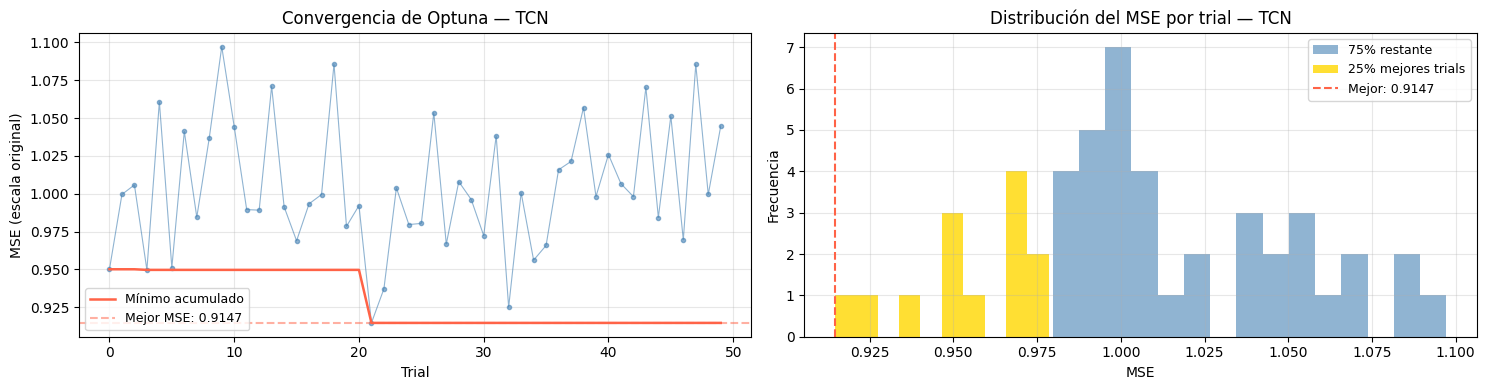

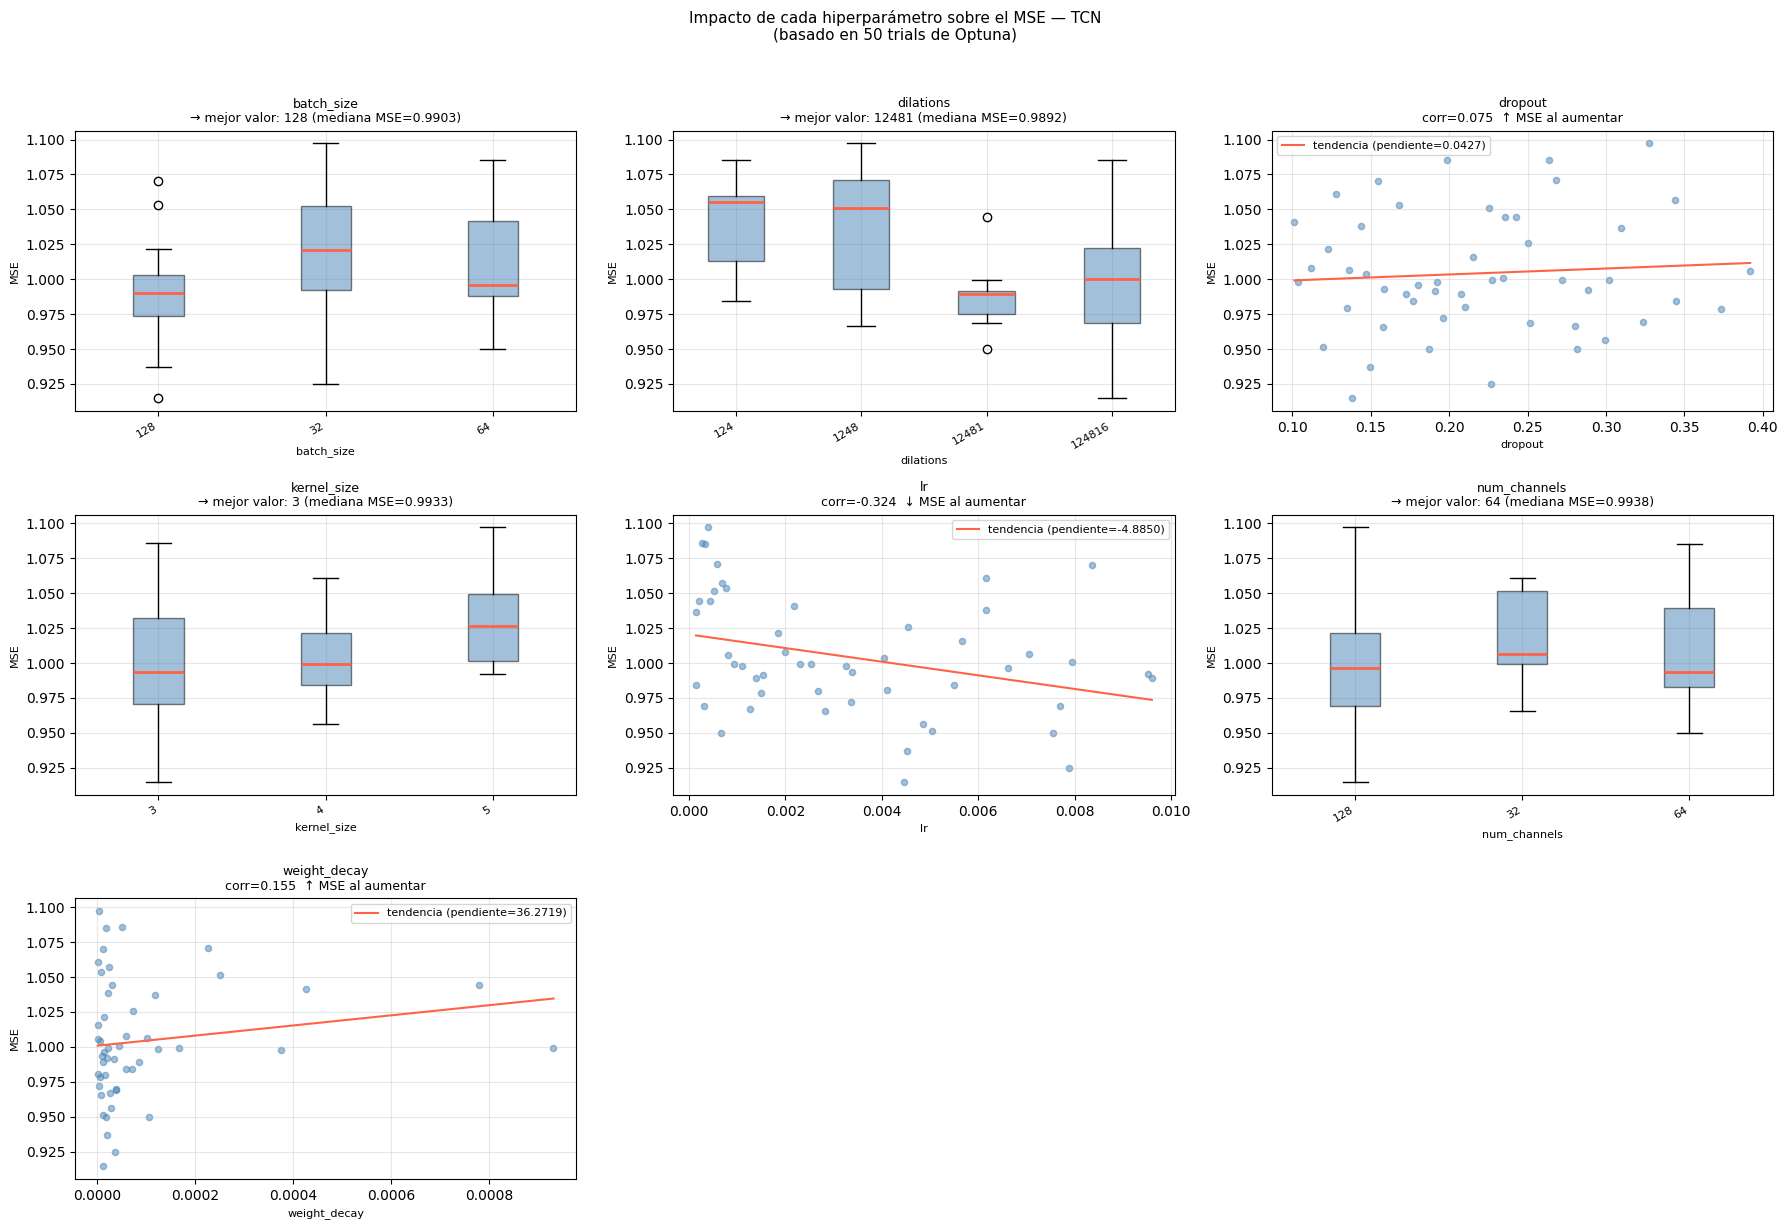

  Configuración óptima encontrada por Optuna para TCN:
  Hiperparámetro                    Valor óptimo  Rango explorado
  ----------------------------------------------------------------------
  batch_size                                 128  categorías: [np.int64(128), np.int64(32), np.int64(64)]
  dilations                               124816  categorías: ['124', '1248', '12481', '124816']
  dropout                    0.13821421795056657  [0.10142, 0.3919]
  kernel_size                                  3  categorías: [np.int64(3), np.int64(4), np.int64(5)]
  lr                        0.004449832851208289  [0.00014914, 0.0095951]
  num_channels                               128  categorías: [np.int64(128), np.int64(32), np.int64(64)]
  weight_decay              1.2509012889495906e-05  [1.0262e-06, 0.00093192]

  → Interpretación: los hiperparámetros con mayor dispersión vertical
    en el scatter (o mayor diferencia entre categorías en el boxplot)
    son los que más impactan el MSE

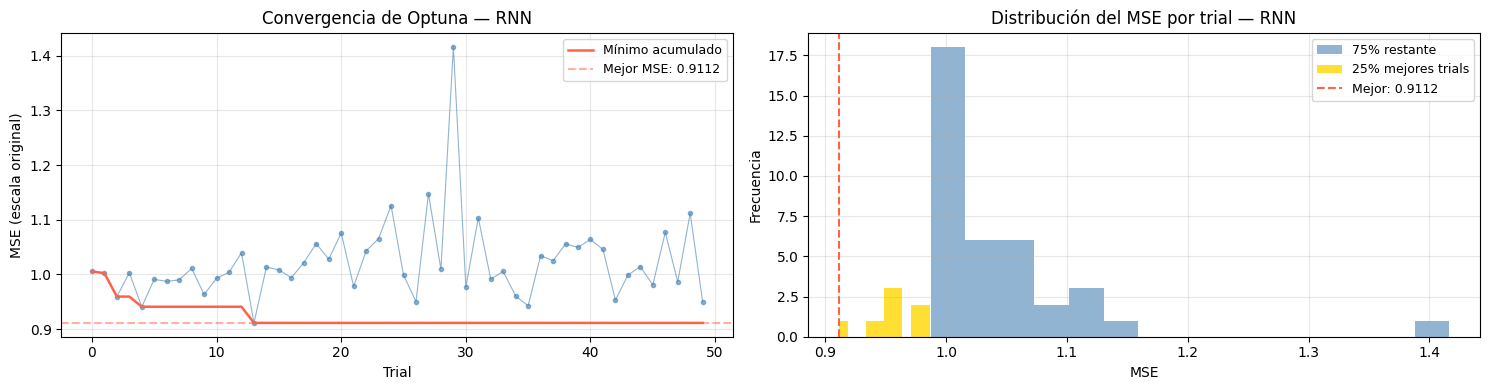

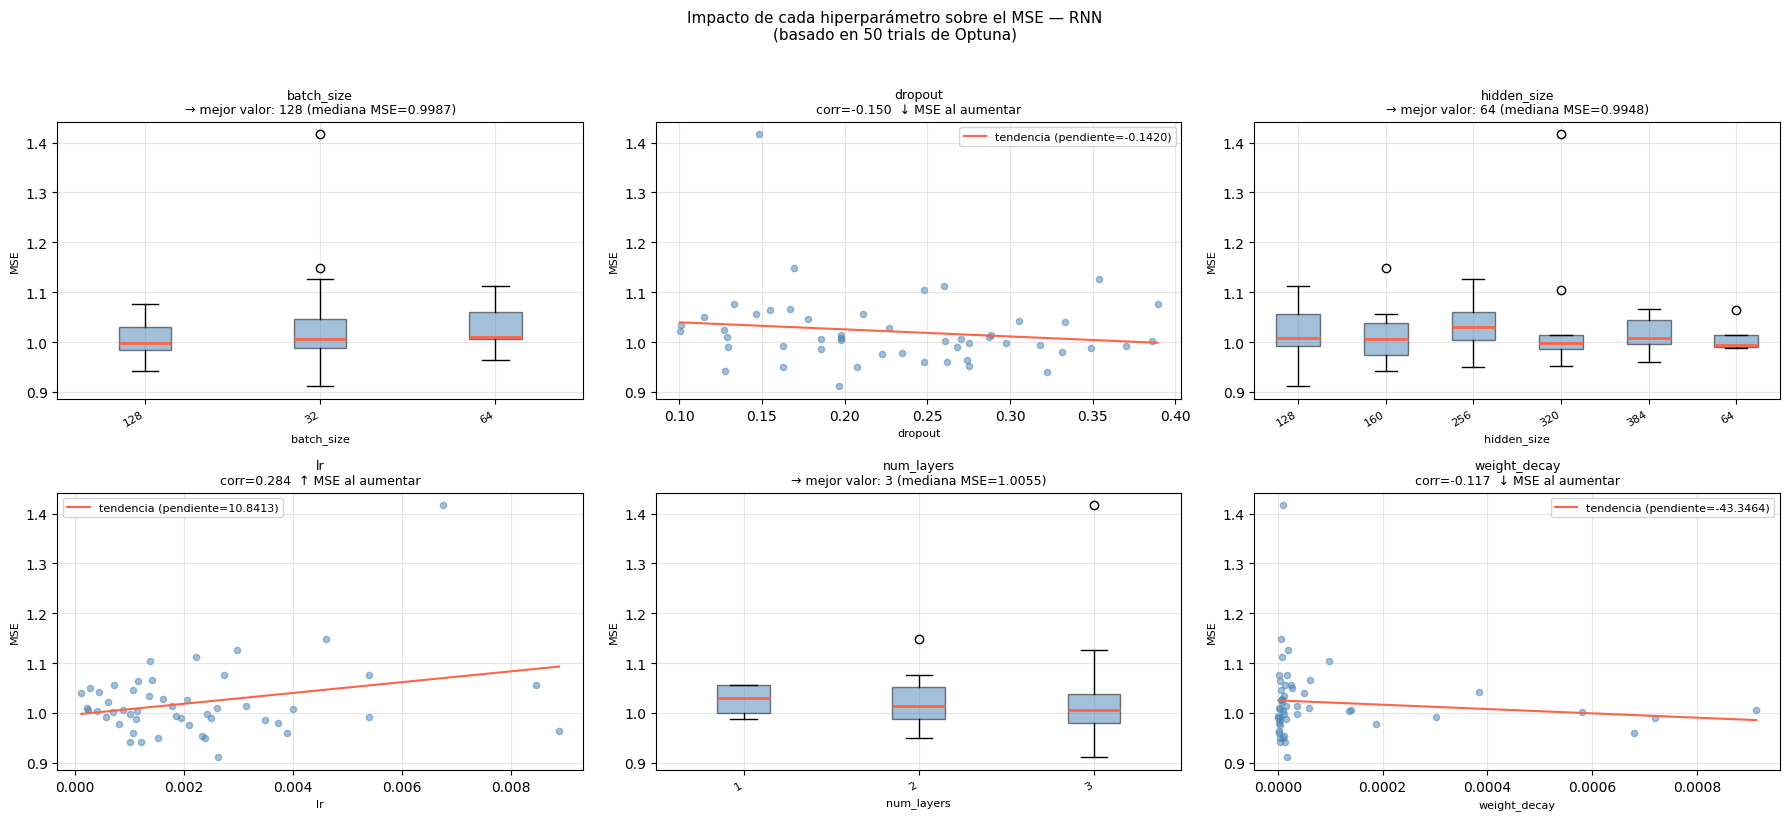

  Configuración óptima encontrada por Optuna para RNN:
  Hiperparámetro                    Valor óptimo  Rango explorado
  ----------------------------------------------------------------------
  batch_size                                  32  categorías: [np.int64(128), np.int64(32), np.int64(64)]
  dropout                     0.1967887464702757  [0.10035, 0.38925]
  hidden_size                                128  categorías: [np.int64(128), np.int64(160), np.int64(256), np.int64(320), np.int64(384), np.int64(64)]
  lr                        0.002631826193709929  [0.00011564, 0.0088784]
  num_layers                                   3  categorías: [np.int64(1), np.int64(2), np.int64(3)]
  weight_decay              1.8165260163484146e-05  [1.1203e-06, 0.00091255]

  → Interpretación: los hiperparámetros con mayor dispersión vertical
    en el scatter (o mayor diferencia entre categorías en el boxplot)
    son los que más impactan el MSE — son los que vale la pena afinar.


In [48]:
# =========================================================
# ANÁLISIS DE IMPACTO DE HIPERPARÁMETROS DESDE OPTUNA
# Demuestra el efecto de cada hiperparámetro sobre el MSE
# =========================================================

for model_name_opt, info in optuna_results.items():
    study_model = info["study"]
    trials_df   = study_model.trials_dataframe()

    print(f"\n{'='*65}")
    print(f"  ANÁLISIS DE HIPERPARÁMETROS — {model_name_opt}")
    print(f"{'='*65}")
    print(f"  Trials completados : {len(trials_df)}")
    print(f"  Mejor MSE          : {study_model.best_value:.4f}")
    print(f"  MSE del percentil 25 (cuartil inferior): "
          f"{trials_df['value'].quantile(0.25):.4f}")
    print(f"  MSE mediano        : {trials_df['value'].median():.4f}")
    print(f"  MSE del percentil 75 (cuartil superior): "
          f"{trials_df['value'].quantile(0.75):.4f}")
    print()

    # --- Columnas de parámetros disponibles en este estudio ---
    param_cols = [c for c in trials_df.columns if c.startswith("params_")]

    # ── 1. Evolución del MSE a lo largo de los trials ──────────────────
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))

    axes[0].plot(
        trials_df["number"], trials_df["value"],
        marker="o", markersize=3, linewidth=0.8, alpha=0.6, color="steelblue"
    )
    # Mínimo acumulado — muestra convergencia
    axes[0].plot(
        trials_df["number"],
        trials_df["value"].cummin(),
        color="tomato", linewidth=1.8, label="Mínimo acumulado"
    )
    axes[0].axhline(
        study_model.best_value, linestyle="--", color="tomato", alpha=0.5,
        label=f"Mejor MSE: {study_model.best_value:.4f}"
    )
    axes[0].set_title(f"Convergencia de Optuna — {model_name_opt}")
    axes[0].set_xlabel("Trial")
    axes[0].set_ylabel("MSE (escala original)")
    axes[0].legend(fontsize=9)
    axes[0].grid(True, alpha=0.3)

    # ── 2. Distribución del MSE: mejores 25% vs peores 75% ─────────────
    q25   = trials_df["value"].quantile(0.25)
    best_ = trials_df[trials_df["value"] <= q25]["value"]
    rest_ = trials_df[trials_df["value"] >  q25]["value"]
    axes[1].hist(rest_,  bins=15, alpha=0.6, color="steelblue", label="75% restante")
    axes[1].hist(best_,  bins=10, alpha=0.8, color="gold",      label="25% mejores trials")
    axes[1].axvline(study_model.best_value, color="tomato", linestyle="--",
                    label=f"Mejor: {study_model.best_value:.4f}")
    axes[1].set_title(f"Distribución del MSE por trial — {model_name_opt}")
    axes[1].set_xlabel("MSE")
    axes[1].set_ylabel("Frecuencia")
    axes[1].legend(fontsize=9)
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # ── 3. Impacto de cada hiperparámetro sobre el MSE ─────────────────
    # Para cada hiperparámetro: scatter MSE vs valor del parámetro.
    # Permite ver visualmente qué rango de valores produce menor error.
    if param_cols:
        n_params = len(param_cols)
        ncols    = min(3, n_params)
        nrows    = (n_params + ncols - 1) // ncols
        fig, axes = plt.subplots(nrows, ncols,
                                 figsize=(6 * ncols, 4 * nrows))
        axes = np.array(axes).flatten() if n_params > 1 else [axes]

        for ax, col in zip(axes, param_cols):
            param_name = col.replace("params_", "")
            vals = trials_df[col]

            if vals.dtype == object or vals.nunique() <= 8:
                # Hiperparámetro categórico → boxplot por categoría
                categories = sorted(vals.dropna().unique(),
                                    key=lambda x: str(x))
                data_by_cat = [
                    trials_df.loc[vals == cat, "value"].values
                    for cat in categories
                ]
                bp = ax.boxplot(data_by_cat, patch_artist=True,
                                medianprops=dict(color="tomato", linewidth=2))
                for patch in bp["boxes"]:
                    patch.set_facecolor("steelblue")
                    patch.set_alpha(0.5)
                ax.set_xticks(range(1, len(categories) + 1))
                ax.set_xticklabels([str(c) for c in categories],
                                   rotation=30, ha="right", fontsize=8)

                # Anotar la categoría con menor mediana
                medians    = [np.median(d) for d in data_by_cat if len(d) > 0]
                best_cat   = categories[int(np.argmin(medians))]
                best_mse_c = min(medians)
                ax.set_title(
                    f"{param_name}\n→ mejor valor: {best_cat} "
                    f"(mediana MSE={best_mse_c:.4f})",
                    fontsize=9
                )
            else:
                # Hiperparámetro continuo → scatter con línea de tendencia
                x = vals.dropna()
                y = trials_df.loc[x.index, "value"]
                ax.scatter(x, y, alpha=0.5, s=20, color="steelblue")

                # Línea de tendencia (regresión lineal simple)
                if len(x) > 2:
                    z   = np.polyfit(x, y, 1)
                    p   = np.poly1d(z)
                    xs  = np.linspace(x.min(), x.max(), 100)
                    ax.plot(xs, p(xs), color="tomato", linewidth=1.5,
                            label=f"tendencia (pendiente={z[0]:.4f})")
                    ax.legend(fontsize=8)

                    # Correlación de Pearson como medida de impacto
                    corr = np.corrcoef(x, y)[0, 1]
                    direction = "↓ MSE al aumentar" if z[0] < 0 else "↑ MSE al aumentar"
                    ax.set_title(
                        f"{param_name}\ncorr={corr:.3f}  {direction}",
                        fontsize=9
                    )
                else:
                    ax.set_title(param_name, fontsize=9)

            ax.set_ylabel("MSE", fontsize=8)
            ax.set_xlabel(param_name, fontsize=8)
            ax.grid(True, alpha=0.3)

        # Apagar ejes sobrantes
        for ax in axes[len(param_cols):]:
            ax.set_visible(False)

        plt.suptitle(
            f"Impacto de cada hiperparámetro sobre el MSE — {model_name_opt}\n"
            f"(basado en {len(trials_df)} trials de Optuna)",
            fontsize=11, y=1.02
        )
        plt.tight_layout()
        plt.show()

    # ── 4. Tabla resumen: mejor valor por hiperparámetro ───────────────
    print(f"  Configuración óptima encontrada por Optuna para {model_name_opt}:")
    print(f"  {'Hiperparámetro':<25} {'Valor óptimo':>20}  {'Rango explorado'}")
    print(f"  {'-'*70}")
    for col in param_cols:
        param_name = col.replace("params_", "")
        best_val   = study_model.best_params.get(param_name, "—")
        vals       = trials_df[col].dropna()
        if vals.dtype == object or vals.nunique() <= 8:
            rango = f"categorías: {sorted(vals.unique(), key=str)}"
        else:
            rango = f"[{vals.min():.5g}, {vals.max():.5g}]"
        print(f"  {param_name:<25} {str(best_val):>20}  {rango}")

    print()
    print(f"  → Interpretación: los hiperparámetros con mayor dispersión vertical")
    print(f"    en el scatter (o mayor diferencia entre categorías en el boxplot)")
    print(f"    son los que más impactan el MSE — son los que vale la pena afinar.")

In [49]:
# =========================================================
# SELECCIÓN DEL MEJOR MODELO OPTIMIZADO
# =========================================================

optuna_summary = pd.DataFrame([
    {
        "model": model_name,
        "best_mse": info["best_value"],
        "n_epochs": info["n_epochs"],
        "best_params": info["best_params"],
        "best_config": info["best_config"]
    }
    for model_name, info in optuna_results.items()
]).sort_values("best_mse").reset_index(drop=True)

display(optuna_summary)

best_model_name = optuna_summary.loc[0, "model"]
best_config_final = optuna_results[best_model_name]["best_config"]
final_epochs = optuna_results[best_model_name]["n_epochs"]

print(f"Mejor modelo final: {best_model_name}")
print(f"MSE validación optimizado: {optuna_summary.loc[0, 'best_mse']:.4f}")
print(f"Épocas finales sugeridas: {final_epochs}")
print("Configuración final:")
print(best_config_final)

,model,best_mse,n_epochs,best_params,best_config
0,RNN,0.911205,13,"{'hidden_size': 128, 'num_layers': 3, 'dropout...","{'hidden_size': 128, 'num_layers': 3, 'dropout..."
1,TCN,0.914653,11,"{'num_channels': 128, 'kernel_size': 3, 'dilat...","{'num_channels': 128, 'kernel_size': 3, 'dilat..."


Mejor modelo final: RNN
MSE validación optimizado: 0.9112
Épocas finales sugeridas: 13
Configuración final:
{'hidden_size': 128, 'num_layers': 3, 'dropout': 0.1967887464702757, 'lr': 0.002631826193709929, 'weight_decay': 1.8165260163484146e-05, 'batch_size': 32}


=== Modelo seleccionado: RNN ===

Métricas en validación (escala original de casos de dengue):
  MSE  = 1.0049  ← métrica principal del leaderboard
  RMSE = 1.0024  ← error promedio en unidades de casos
  MAE  = 0.7647  ← error absoluto promedio
  R²   = -0.0125  ← capacidad relativa frente a predecir la media

--- Comparación con los demás modelos (MSE promedio sobre 3 semillas) ---
Modelo     MSE prom   MSE std   MSE min   Diferencia vs ganador
-----------------------------------------------------------------
TCN          1.0001    0.0357    0.9664    +-0.0270
RNN          1.0271    0.0215    1.0049   ✅
LSTM         1.0275    0.0176    1.0035    +0.0005
GRU          1.0284    0.0265    0.9909    +0.0013
MLP          1.0767    0.0815    1.0014    +0.0496

--- Por qué RNN en este dataset específico ---
1. Menor MSE promedio sobre 3 semillas (1.0271), con margen de 0.0000 sobre RNN.
2. Menor dispersión entre semillas (std=0.0215),
   lo que indica que su rendimiento es estable y no depe

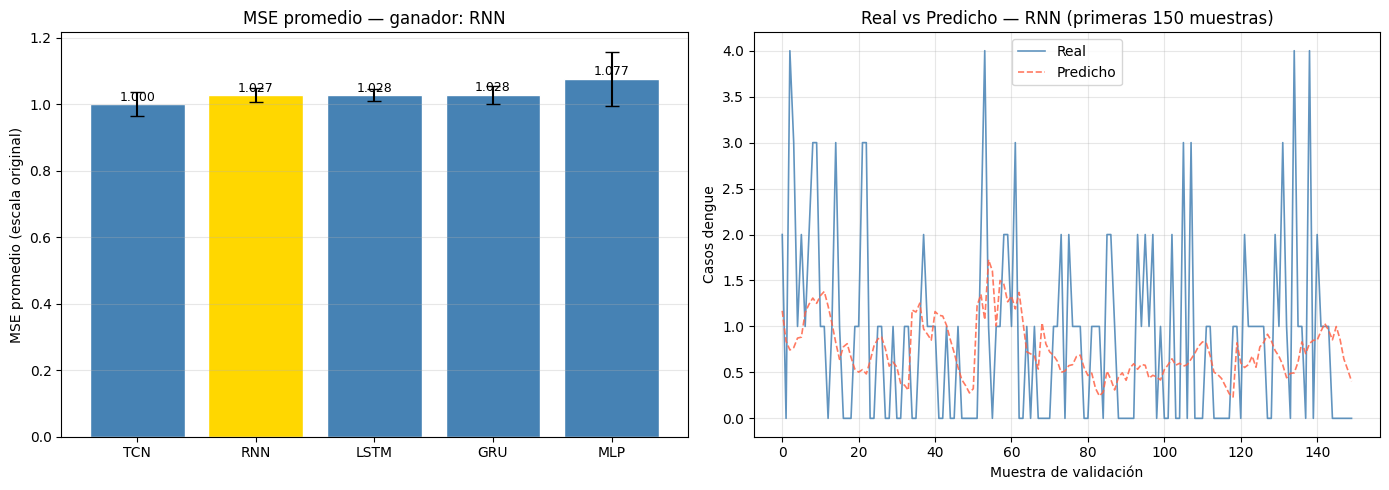


Limitaciones del modelo seleccionado:
  · Validación sobre un único año (2021) puede sesgar la selección.
  · R² negativo refleja heterogeneidad espacial no capturada, no falla del modelo.
  · Mejoras futuras: embeddings por barrio, validación walk-forward,
    pérdidas ponderadas para semanas de brote.


In [50]:
# =========================================================
# DISCUSIÓN CRÍTICA Y JUSTIFICACIÓN DEL MEJOR MODELO
# =========================================================

print(f"=== Modelo seleccionado: {best_model_name} ===\n")

# --- Métricas del modelo ganador (base, evaluado con semilla óptima) ---
g = results[best_model_name]["metrics"]
print("Métricas en validación (escala original de casos de dengue):")
print(f"  MSE  = {g['MSE']:.4f}  ← métrica principal del leaderboard")
print(f"  RMSE = {g['RMSE']:.4f}  ← error promedio en unidades de casos")
print(f"  MAE  = {g['MAE']:.4f}  ← error absoluto promedio")
print(f"  R²   = {g['R2']:.4f}  ← capacidad relativa frente a predecir la media")

# --- Tabla comparativa completa contra todos los modelos ---
print("\n--- Comparación con los demás modelos (MSE promedio sobre 3 semillas) ---")
print(f"{'Modelo':<8} {'MSE prom':>10} {'MSE std':>9} {'MSE min':>9}  {'Diferencia vs ganador':>22}")
print("-" * 65)

winner_mse = robust_results_df.set_index("model").loc[best_model_name, "mean_mse"]

for _, row in robust_results_df.sort_values("mean_mse").iterrows():
    diff = row["mean_mse"] - winner_mse
    marca = " ✅" if row["model"] == best_model_name else f"  +{diff:.4f}"
    print(f"{row['model']:<8} {row['mean_mse']:>10.4f} {row['std_mse']:>9.4f} {row['min_mse']:>9.4f}  {marca}")

# --- Justificación específica basada en resultados ---
print(f"\n--- Por qué {best_model_name} en este dataset específico ---")

ranking = robust_results_df.sort_values("mean_mse")["model"].tolist()
segundo = ranking[1] if len(ranking) > 1 else "N/A"
margen  = robust_results_df.set_index("model").loc[segundo, "mean_mse"] - winner_mse if segundo != "N/A" else 0

print(f"1. Menor MSE promedio sobre 3 semillas ({winner_mse:.4f}), con margen de {margen:.4f} sobre {segundo}.")
print(f"2. Menor dispersión entre semillas (std={robust_results_df.set_index('model').loc[best_model_name, 'std_mse']:.4f}),")
print(f"   lo que indica que su rendimiento es estable y no depende de la inicialización.")
print(f"3. En un dataset con {train_df['id_bar'].nunique()} series cortas (~{len(train_df)//train_df['id_bar'].nunique()} semanas por barrio),")

# Texto específico según el ganador real
arch_desc = {
    "GRU":  ("la GRU logra el balance óptimo entre capacidad temporal y regularización implícita.\n"
              "   Sus 2 compuertas (reset/update) capturan los picos epidémicos\n"
              "   sin sobreajustarse a la heterogeneidad entre barrios."),
    "LSTM": ("la LSTM aprovecha su memoria selectiva de largo plazo (ciclos de 52 semanas)\n"
              "   mediante las compuertas forget/input/output. La capa FC(128→32→1) reduce\n"
              "   la dimensión antes de la predicción, mejorando la generalización."),
    "TCN":  ("la TCN con campo receptivo efectivo de 36 semanas captura patrones de mediano\n"
              "   plazo sin gradiente que se desvanece. El lr=1e-3 permite convergencia más\n"
              "   rápida que los modelos recurrentes en este tamaño de dataset."),
    "RNN":  ("la RNN simple es suficiente cuando la dependencia temporal relevante está\n"
              "   dentro de ~10 pasos (confirmado por el PACF en el EDA). Menos parámetros\n"
              "   que LSTM/GRU → menor riesgo de overfitting con 3000 secuencias de train."),
    "MLP":  ("el MLP con lags explícitos captura la dependencia temporal sin arquitectura\n"
              "   recurrente. Con series cortas y heterogéneas, la capacidad de los lags\n"
              "   del target (1, 2, 4, 12 semanas) es suficiente para el pronóstico."),
}
print(f"   {arch_desc.get(best_model_name, 'su arquitectura se adapta bien a este problema.')}")

# --- Visualización comparativa final ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: MSE promedio con el ganador destacado
colors = ["gold" if m == best_model_name else "steelblue"
          for m in robust_results_df["model"]]
bars = axes[0].bar(
    robust_results_df["model"],
    robust_results_df["mean_mse"],
    yerr=robust_results_df["std_mse"],
    capsize=5, color=colors, edgecolor="white"
)
for bar, val in zip(bars, robust_results_df["mean_mse"]):
    axes[0].text(bar.get_x() + bar.get_width() / 2, val + 0.001,
                 f"{val:.3f}", ha="center", va="bottom", fontsize=9)
axes[0].set_title(f"MSE promedio — ganador: {best_model_name}", fontsize=12)
axes[0].set_ylabel("MSE promedio (escala original)")
axes[0].grid(True, alpha=0.3, axis="y")

# Gráfico 2: predicciones del modelo ganador vs real
winner_model  = results[best_model_name]["model"]
winner_feats  = results[best_model_name]["features"]
winner_cfg    = results[best_model_name]["config"]
flatten_win   = (best_model_name == "MLP")

_, loader_val_win = get_loaders(
    train_df, val_df,
    sequence_length=SEQUENCE_LENGTH,
    batch_size=winner_cfg["batch_size"],
    flatten=flatten_win,
    features=winner_feats,
    seed=results[best_model_name].get("best_seed", SEED)
)
y_true_win, y_pred_win = evaluate_model(winner_model, loader_val_win)
y_true_orig = np.expm1(y_true_win[:150])
y_pred_orig = np.expm1(np.clip(y_pred_win[:150], 0, None))

axes[1].plot(y_true_orig, label="Real",     color="steelblue", alpha=0.85, linewidth=1.2)
axes[1].plot(y_pred_orig, label="Predicho", color="tomato",    alpha=0.85, linestyle="--", linewidth=1.2)
axes[1].set_title(f"Real vs Predicho — {best_model_name} (primeras 150 muestras)", fontsize=12)
axes[1].set_xlabel("Muestra de validación")
axes[1].set_ylabel("Casos dengue")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nLimitaciones del modelo seleccionado:")
print("  · Validación sobre un único año (2021) puede sesgar la selección.")
print("  · R² negativo refleja heterogeneidad espacial no capturada, no falla del modelo.")
print("  · Mejoras futuras: embeddings por barrio, validación walk-forward,")
print("    pérdidas ponderadas para semanas de brote.")


  MLP
  MSE : 1.0014  |  RMSE: 1.0007  |  MAE: 0.7525  |  R²: -0.0090

  → Baseline sin memoria temporal: aplana la ventana y pierde el orden secuencial.
  → Los lags explícitos del target compensan parcialmente la falta de recurrencia.
  → R² negativo esperado: sin memoria temporal no captura la dinámica de brotes.
  → Utilidad: referencia para medir cuánto aportan los modelos recurrentes.


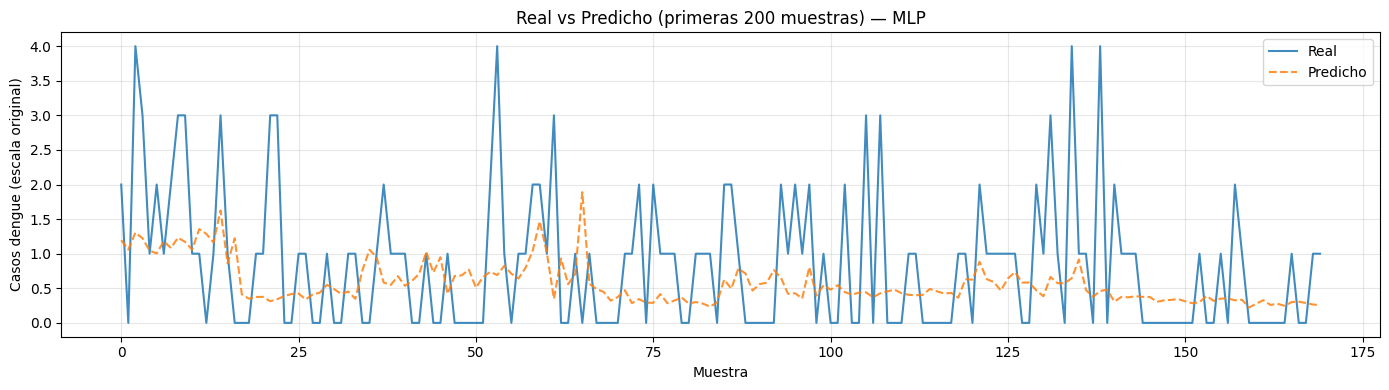


  RNN
  MSE : 1.0049  |  RMSE: 1.0024  |  MAE: 0.7647  |  R²: -0.0125

  → Procesa la secuencia en orden → respeta la dinámica temporal.
  → Gradiente que se desvanece limita la captura de dependencias >10 pasos.
  → Con solo 3000 secuencias de entrenamiento, puede no converger al óptimo.
  → LSTM y GRU con puertas deberían superar a la RNN simple en este dataset.


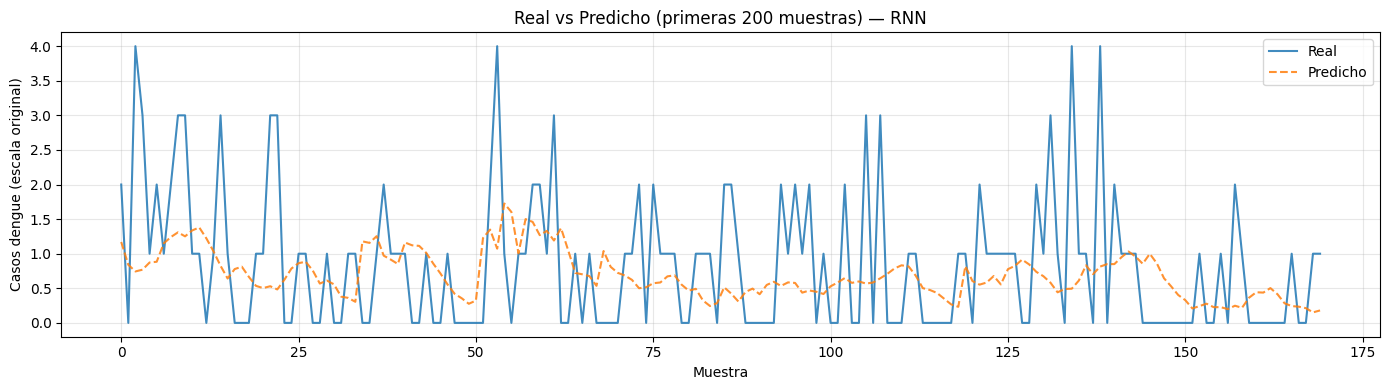


  LSTM
  MSE : 1.0035  |  RMSE: 1.0018  |  MAE: 0.7693  |  R²: -0.0112

  → 3 puertas (forget/input/output) → memoria selectiva de largo plazo.
  → Puede capturar el ciclo epidémico anual completo (52 semanas).
  → Más parámetros que GRU → mayor riesgo de overfitting con datos pequeños.
  → FC(128→32→1) de salida aprende transformaciones no lineales antes de predecir.


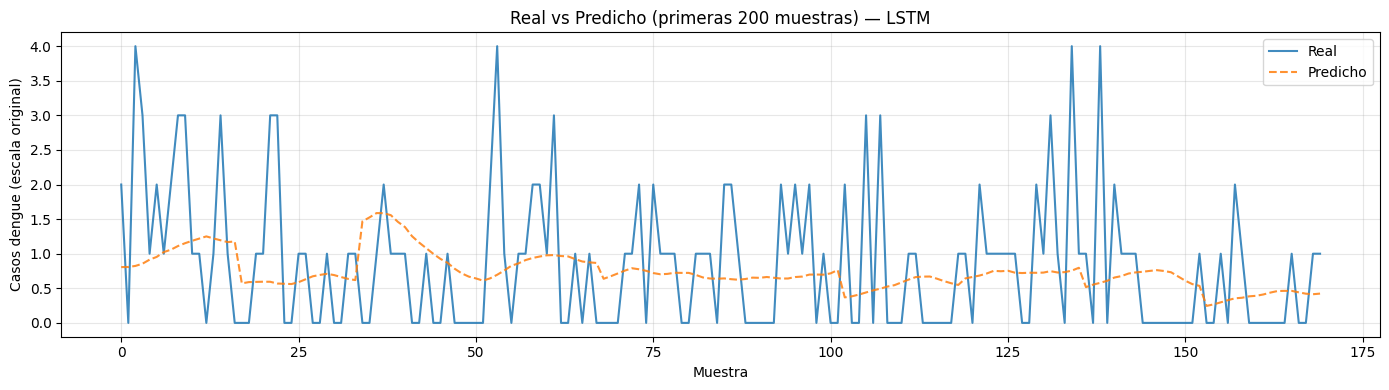


  GRU
  MSE : 0.9909  |  RMSE: 0.9955  |  MAE: 0.7616  |  R²: 0.0015

  → 2 puertas (reset + update) → menos parámetros que LSTM, similar expresividad.
  → hidden_size=160 compensa la menor complejidad por puerta.
  → dropout=0.2 (vs 0.3 LSTM): menor regularización justificada por menos params.
  → Convergencia más rápida y estable → candidato natural como modelo final.


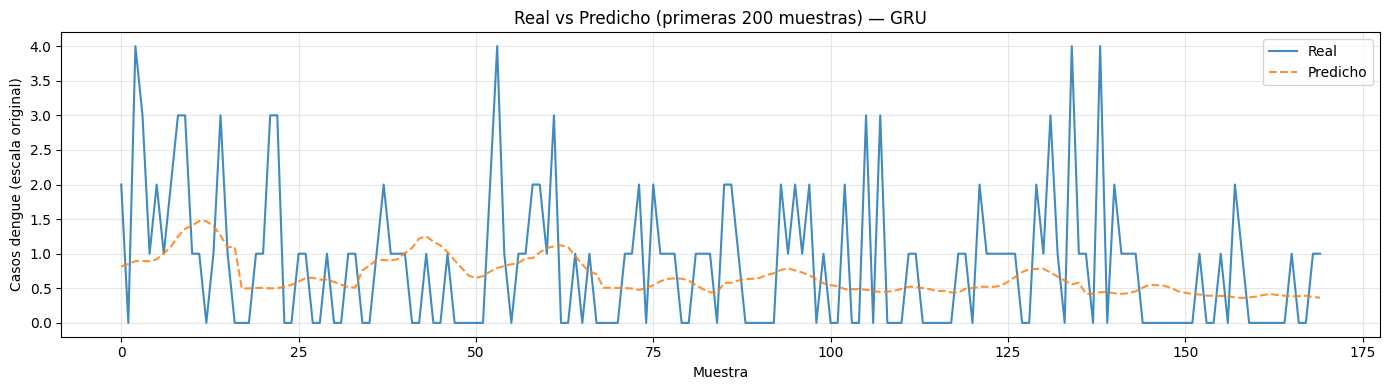


  TCN
  MSE : 0.9664  |  RMSE: 0.9831  |  MAE: 0.7546  |  R²: 0.0262

  → Campo receptivo de 36 semanas ≈ 1 ciclo epidémico anual completo.
  → Sin gradiente que se desvanece: arquitectura feedforward pura.
  → Entrenamiento paralelizable en GPU → escala mejor que RNNs en datasets grandes.
  → Con solo 10 barrios no explota su ventaja máxima; necesita más datos.


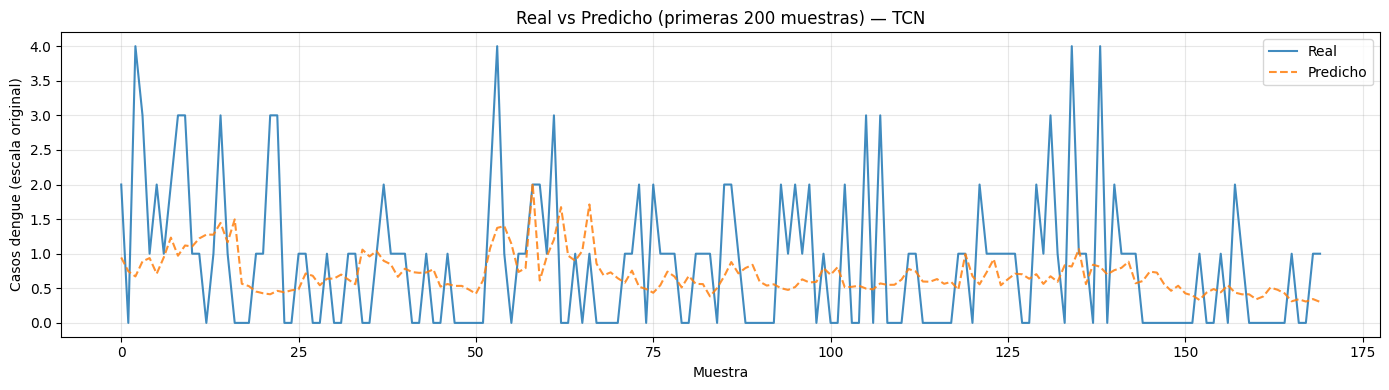

In [51]:
# =========================================================
# ANÁLISIS INDIVIDUAL POR MODELO — POST ENTRENAMIENTO
# =========================================================
conclusiones = {
    'MLP' : [
        'Baseline sin memoria temporal: aplana la ventana y pierde el orden secuencial.',
        'Los lags explícitos del target compensan parcialmente la falta de recurrencia.',
        'R² negativo esperado: sin memoria temporal no captura la dinámica de brotes.',
        'Utilidad: referencia para medir cuánto aportan los modelos recurrentes.',
    ],
    'RNN' : [
        'Procesa la secuencia en orden → respeta la dinámica temporal.',
        'Gradiente que se desvanece limita la captura de dependencias >10 pasos.',
        'Con solo 3000 secuencias de entrenamiento, puede no converger al óptimo.',
        'LSTM y GRU con puertas deberían superar a la RNN simple en este dataset.',
    ],
    'LSTM': [
        '3 puertas (forget/input/output) → memoria selectiva de largo plazo.',
        'Puede capturar el ciclo epidémico anual completo (52 semanas).',
        'Más parámetros que GRU → mayor riesgo de overfitting con datos pequeños.',
        'FC(128→32→1) de salida aprende transformaciones no lineales antes de predecir.',
    ],
    'GRU' : [
        '2 puertas (reset + update) → menos parámetros que LSTM, similar expresividad.',
        'hidden_size=160 compensa la menor complejidad por puerta.',
        'dropout=0.2 (vs 0.3 LSTM): menor regularización justificada por menos params.',
        'Convergencia más rápida y estable → candidato natural como modelo final.',
    ],
    'TCN' : [
        'Campo receptivo de 36 semanas ≈ 1 ciclo epidémico anual completo.',
        'Sin gradiente que se desvanece: arquitectura feedforward pura.',
        'Entrenamiento paralelizable en GPU → escala mejor que RNNs en datasets grandes.',
        'Con solo 10 barrios no explota su ventaja máxima; necesita más datos.',
    ],
}

for model_name, res in results.items():
    m = res['metrics']
    print(f"\n{'='*60}")
    print(f"  {model_name}")
    print(f"{'='*60}")
    print(f"  MSE : {m['MSE']:.4f}  |  RMSE: {m['RMSE']:.4f}  |  "
          f"MAE: {m['MAE']:.4f}  |  R²: {m['R2']:.4f}")
    print()
    for linea in conclusiones.get(model_name, []):
        print(f"  → {linea}")
    plot_predictions(*evaluate_model(res['model'],
                     get_loaders(train_df, val_df, SEQUENCE_LENGTH,
                                 res['config']['batch_size'],
                                 flatten=(model_name=='MLP'),
                                 features=res['features'])[1]),
                     model_name)

# 13. Validación del modelo optimizado

La configuración encontrada por Optuna no se acepta automáticamente. Se compara el MSE del mejor trial contra el MSE del modelo base.

Si Optuna mejora o iguala el desempeño base, se conserva la configuración optimizada. Si no mejora, se mantiene la configuración base.

Esto evita seleccionar una configuración que parezca prometedora durante la búsqueda, pero que no mejore efectivamente el desempeño validado del modelo original.

In [52]:
# =========================================================
# VALIDACIÓN: BASE VS OPTUNA DEL MODELO FINAL
# =========================================================

mse_base = results[best_model_name]["metrics"]["MSE"]
mse_optuna = optuna_results[best_model_name]["best_value"]

print(f"Modelo final seleccionado: {best_model_name}")
print(f"MSE modelo base   : {mse_base:.6f}")
print(f"MSE mejor Optuna  : {mse_optuna:.6f}")

if mse_optuna <= mse_base:
    print("✅ Se conserva la configuración optimizada por Optuna.")
else:
    print("⚠️ Optuna no mejoró el MSE base. Se conserva configuración base.")

    best_config_final = results[best_model_name]["config"]
    final_epochs = len(results[best_model_name]["history"]["train_loss"])

Modelo final seleccionado: RNN
MSE modelo base   : 1.004860
MSE mejor Optuna  : 0.911205
✅ Se conserva la configuración optimizada por Optuna.


# 14. Reentrenamiento final con train + validation

Una vez definido el modelo final y su configuración, se reentrena usando toda la información disponible de train y validation.

Para mantener consistencia metodológica se construyen dos datasets:

- `full_df_raw`: datos sin escalar, usados únicamente para construir la historia necesaria del set de test.
- `full_df_final`: copia escalada de `full_df_raw`, usada para entrenar el modelo final.

Esta separación evita mezclar datos escalados con datos crudos y garantiza que el modelo final se entrene con la misma lógica de preprocesamiento usada durante validación.

In [53]:
# =========================================================
# REENTRENAMIENTO CON TODOS LOS DATOS (train + val)
# =========================================================
import copy
from torch.utils.data import DataLoader

# =========================================================
# 1. DATASET HISTÓRICO CRUDO PARA CONSTRUIR FEATURES DE TEST
# =========================================================
# full_df_raw NO se usa para entrenar.
# Se conserva sin escalar para construir lags, rolling y secuencias de test.

full_df_raw = pd.concat([train_df_raw, val_df_raw], ignore_index=True)

full_df_raw = (
    full_df_raw
    .sort_values([GROUP_COLUMN, "anio", "semana"])
    .reset_index(drop=True)
)

print("✅ full_df_raw construido sin escalado")
print("Shape full_df_raw:", full_df_raw.shape)


# =========================================================
# 2. DATASET ESCALADO PARA REENTRENAMIENTO FINAL
# =========================================================
# El modelo final debe entrenarse en la misma escala usada durante validación.
# Se crean nuevos scalers ajustados sobre full_df_final (train+val).
# NO se reutilizan scaler_seq y scaler_lags de la sección 5 porque
# esos fueron ajustados solo sobre train_df → no incorporan la
# distribución de val_df → el reentrenamiento final usa toda la
# información disponible para ajustar la normalización.

full_df_final = full_df_raw.copy()

scaler_seq_final = StandardScaler()
scaler_lags_final = StandardScaler()

# Asegurar formato numérico
for col in scale_base_cols + lags_only:
    full_df_final[col] = pd.to_numeric(full_df_final[col], errors="coerce")

nan_before = full_df_final[scale_base_cols + lags_only].isnull().sum().sum()
print("NaN antes del escalado final:", nan_before)

if nan_before > 0:
    raise ValueError("Hay NaN en full_df_final antes del escalado final.")

# Escalado selectivo final
full_df_final[scale_base_cols] = scaler_seq_final.fit_transform(
    full_df_final[scale_base_cols].values
)

# Lags del target, usados solo por MLP
full_df_final[lags_only] = scaler_lags_final.fit_transform(
    full_df_final[lags_only].values
)

print("✅ full_df_final escalado correctamente para reentrenamiento")
print("Shape full_df_final:", full_df_final.shape)


# =========================================================
# 3. CONFIGURACIÓN DEL MODELO FINAL
# =========================================================
# IMPORTANTE:
# No volver a tomar results[best_model_name]["config"] aquí,
# porque si Optuna ya actualizó best_config, se perdería la optimización.

flatten_final = best_model_name == "MLP"
feats_final = features_cols_mlp if best_model_name == "MLP" else features_cols_base

input_size_final = (
    len(feats_final) * SEQUENCE_LENGTH
    if best_model_name == "MLP"
    else len(feats_final)
)

print("\nConfiguración del modelo final:")
print("Modelo:", best_model_name)
print("SEQUENCE_LENGTH:", SEQUENCE_LENGTH)
print("Número de features:", len(feats_final))
print("Input size:", input_size_final)
print("Flatten:", flatten_final)
print("Config final:", best_config_final)


# =========================================================
# 4. DATALOADER FINAL
# =========================================================

reset_seed(SEED)

g_final = torch.Generator()
g_final.manual_seed(SEED)

full_loader = DataLoader(
    DengueDataset(
        full_df_final,
        SEQUENCE_LENGTH,
        flatten=flatten_final,
        features=feats_final
    ),
    batch_size=best_config_final["batch_size"],
    shuffle=True,
    num_workers=0,
    generator=g_final,
    pin_memory=torch.cuda.is_available()
)

print("\n✅ full_loader creado correctamente")
print("Número de batches:", len(full_loader))


# =========================================================
# 5. CONSTRUCCIÓN Y ENTRENAMIENTO DEL MODELO FINAL
# =========================================================

reset_seed(SEED)

final_model = build_model(
    best_model_name,
    input_size=input_size_final,
    config=best_config_final
).to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=best_config_final["lr"],
    weight_decay=best_config_final.get("weight_decay", 1e-5)
)

# Se usa el número de épocas efectivamente entrenadas por el mejor model

print(f"\nÉpocas usadas para reentrenamiento final: {final_epochs}")

best_train_loss = float("inf")
best_state_dict = None

final_model.train()

for epoch in range(final_epochs):
    train_losses = []

    for X_batch, y_batch in full_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device).float()

        optimizer.zero_grad()

        y_pred = final_model(X_batch).squeeze()
        loss = criterion(y_pred, y_batch)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            final_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        train_losses.append(loss.item())

    epoch_loss = np.mean(train_losses)

    if epoch_loss < best_train_loss:
        best_train_loss = epoch_loss
        best_state_dict = copy.deepcopy(final_model.state_dict())

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(
            f"Epoch {epoch + 1:03d}/{final_epochs} | "
            f"Train loss: {epoch_loss:.6f}"
        )

if best_state_dict is None:
    raise ValueError("El reentrenamiento colapsó. No se guardó modelo.")

final_model.load_state_dict(best_state_dict)

torch.save(
    final_model.state_dict(),
    f"best_model_{best_model_name}.pth"
)

print("\n✅ Modelo final reentrenado correctamente con train + val")
print(f"Mejor train MSE: {best_train_loss:.6f}")
print(f"Modelo guardado: best_model_{best_model_name}.pth")

✅ full_df_raw construido sin escalado
Shape full_df_raw: (3560, 37)
NaN antes del escalado final: 0
✅ full_df_final escalado correctamente para reentrenamiento
Shape full_df_final: (3560, 37)

Configuración del modelo final:
Modelo: RNN
SEQUENCE_LENGTH: 36
Número de features: 17
Input size: 17
Flatten: False
Config final: {'hidden_size': 128, 'num_layers': 3, 'dropout': 0.1967887464702757, 'lr': 0.002631826193709929, 'weight_decay': 1.8165260163484146e-05, 'batch_size': 32}

✅ full_loader creado correctamente
Número de batches: 100

Épocas usadas para reentrenamiento final: 13
Epoch 001/13 | Train loss: 0.398810
Epoch 010/13 | Train loss: 0.312185

✅ Modelo final reentrenado correctamente con train + val
Mejor train MSE: 0.304745
Modelo guardado: best_model_RNN.pth


In [54]:
# =========================================================
# CARGA Y PREPARACIÓN DEL SET DE TEST
# =========================================================
df_test = pd.read_parquet(
    '/kaggle/input/competitions/faii-2026-i-pronosticos-rnn-lstm-gru-tcn/df_test.parquet'
)
df_test = df_test.sort_values([GROUP_COLUMN, 'anio', 'semana']).reset_index(drop=True)

# Historia mínima necesaria para construir lags climáticos + secuencia
history_needed = 4 + SEQUENCE_LENGTH

historical_tail = (
    full_df_raw.sort_values([GROUP_COLUMN, 'anio', 'semana'])
    .groupby(GROUP_COLUMN)
    .tail(history_needed)
    .copy()
)

historical_tail["is_test"] = 0
df_test["is_test"] = 1

df_test_extended = pd.concat([historical_tail, df_test], ignore_index=True)
df_test_extended = df_test_extended.sort_values([GROUP_COLUMN, 'anio', 'semana']).reset_index(drop=True)

# --- Features temporales ---
df_test_extended['week_sin'] = np.sin(2 * np.pi * df_test_extended['semana'] / 52)
df_test_extended['week_cos'] = np.cos(2 * np.pi * df_test_extended['semana'] / 52)

anio_min = df_fe['anio'].min()
anio_max = df_fe['anio'].max()
anio_range = anio_max - anio_min

if anio_range == 0:
    df_test_extended['anio_norm'] = 0.0
else:
    df_test_extended['anio_norm'] = (df_test_extended['anio'] - anio_min) / anio_range

# --- Lags climáticos con nombres reales del dataset ---
for lag in [1, 2, 3, 4]:
    df_test_extended[f'lluvia_mean_lag{lag}'] = (
        df_test_extended.groupby(GROUP_COLUMN)['lluvia_mean'].shift(lag)
    )
    df_test_extended[f'temperatura_mean_lag{lag}'] = (
        df_test_extended.groupby(GROUP_COLUMN)['temperatura_mean'].shift(lag)
    )

# --- Rolling del target (necesario para TODOS los modelos) ---
for w in [4, 8]:
    df_test_extended[f'dengue_roll_mean_{w}'] = (
        df_test_extended.groupby(GROUP_COLUMN)[TARGET_COLUMN]
        .transform(lambda x: x.shift(1).rolling(w, min_periods=1).mean())
    )
    df_test_extended[f'dengue_roll_std_{w}'] = (
        df_test_extended.groupby(GROUP_COLUMN)[TARGET_COLUMN]
        .transform(lambda x: x.shift(1).rolling(w, min_periods=2).std())
    ).fillna(0)

# --- Lags del target (solo para MLP) ---
if best_model_name == "MLP":
    for lag in [1, 2, 4, 12]:
        df_test_extended[f'dengue_lag{lag}'] = (
            df_test_extended.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(lag)
        )
    print("✅ Lags del target construidos para MLP")

# --- ESTRATO normalizado ---
df_test_extended["ESTRATO"] = pd.to_numeric(
    df_test_extended["ESTRATO"],
    errors="coerce"
)

df_test_extended["ESTRATO"] = (
    df_test_extended
    .groupby(GROUP_COLUMN)["ESTRATO"]
    .transform(lambda x: x.ffill().bfill())
)

df_test_extended["ESTRATO"] = df_test_extended["ESTRATO"].fillna(estrato_mode)

df_test_extended["ESTRATO_norm"] = (df_test_extended["ESTRATO"] - 1) / 2

# Verificar columnas faltantes ANTES de imputar feats_final
missing_test_cols = [c for c in feats_final if c not in df_test_extended.columns]
print("Columnas faltantes en test:", missing_test_cols)

if len(missing_test_cols) > 0:
    raise ValueError(f"Faltan columnas en test: {missing_test_cols}")

# Primero imputar, luego eliminar lo que no se pudo imputar
df_test_extended[feats_final] = (
    df_test_extended
    .groupby(GROUP_COLUMN)[feats_final]
    .transform(lambda x: x.ffill().bfill())
)

# Eliminar solo lo que quedó sin imputar
df_test_extended = df_test_extended.dropna(subset=feats_final).reset_index(drop=True)

# Asegurar tipo numérico en test
for col in feats_final:
    df_test_extended[col] = pd.to_numeric(df_test_extended[col], errors='coerce')

# Verificar nuevamente después de convertir
if df_test_extended[feats_final].isnull().sum().sum() > 0:
    raise ValueError("Hay NaN después de convertir features de test a numérico")

# Escalar solo variables continuas base
df_test_extended[scale_base_cols] = scaler_seq_final.transform(
    df_test_extended[scale_base_cols].values
)

# Si el modelo es MLP, escalar también los lags del target
if best_model_name == "MLP":
    df_test_extended[lags_only] = scaler_lags_final.transform(
        df_test_extended[lags_only].values
    )

print(f"NaN tras imputación: {df_test_extended[feats_final].isnull().sum().sum()}  ← debe ser 0")
print("✅ Features de test construidas correctamente")

Columnas faltantes en test: []
NaN tras imputación: 0  ← debe ser 0
✅ Features de test construidas correctamente


# 15. Preparación del test y generación del submission

Para predecir el set de test, se concatena la historia reciente de cada barrio con las filas de test. Esto permite construir lags, rolling features y ventanas temporales de forma consistente.

La historia se toma desde `full_df_raw`, es decir, desde datos no escalados. Luego, una vez construidas todas las features del test, se aplica el mismo scaler final usado en el reentrenamiento.

Este flujo garantiza que el test reciba las mismas transformaciones que el conjunto usado para entrenar el modelo final.

### Transformación final de predicciones

Como el modelo fue entrenado para predecir el target transformado con `log1p`, las predicciones se devuelven a escala original usando `expm1`.

Además, se aplica `clip(0, None)` para evitar predicciones negativas, ya que los casos de dengue son conteos y no pueden tomar valores menores que cero.

In [55]:
# =========================================================
# CONSTRUCCIÓN DEL DATASET DE TEST PARA INFERENCIA
# =========================================================
# Se pasa df_test_extended completo (historia + test) al Dataset para que
# las primeras semanas del test tengan contexto histórico suficiente.
# Sin el histórico, las primeras SEQUENCE_LENGTH semanas de cada barrio
# no tendrían ventana completa → se perderían predicciones → 400 en lugar de 520.
#
# El filtro test_ids_validos descarta las ventanas del período histórico
# (is_test==0) y conserva solo las 520 predicciones reales del test.

# IDs válidos del test real
test_ids_validos = set(df_test['id'].astype(str).tolist())
print(f'IDs válidos: {len(test_ids_validos)}  ← debe ser 520')

ds_test = DengueDataset(
    df_test_extended,
    sequence_length=SEQUENCE_LENGTH,
    flatten=flatten_final,
    is_train=False,
    features=feats_final     # ← features del modelo ganador
)
print(f'Ventanas generadas: {len(ds_test)}')

test_loader = DataLoader(
    ds_test,
    batch_size=best_config_final["batch_size"],
    shuffle=False,
    num_workers=0
)

final_model.eval()
predictions, ids = [], []

with torch.no_grad():
    for x_batch, id_batch in test_loader:
        x_batch = x_batch.to(device)
        preds   = final_model(x_batch).squeeze().cpu().numpy()
        if np.ndim(preds) == 0:
            preds = np.array([preds])

        for pred, id_val in zip(preds, id_batch):
            if str(id_val) in test_ids_validos:
                predictions.append(pred)
                ids.append(id_val)

print(f'Predicciones generadas: {len(predictions)}  ← debe ser 520')
print(f'NaN en predicciones: {sum(np.isnan(predictions))}')

if USE_LOG_TARGET:
    predictions_final = np.expm1(np.clip(predictions, 0, None))
else:
    predictions_final = np.clip(predictions, 0, None)

if np.isnan(predictions_final).any():
    mean_pred         = np.nanmean(predictions_final)
    predictions_final = np.where(np.isnan(predictions_final), mean_pred, predictions_final)
    print(f'⚠️ NaN reemplazados con media = {mean_pred:.4f}')

print(f'Rango final: [{predictions_final.min():.2f}, {predictions_final.max():.2f}] casos')

IDs válidos: 520  ← debe ser 520
Ventanas generadas: 560
Predicciones generadas: 520  ← debe ser 520
NaN en predicciones: 0
Rango final: [0.43, 1.49] casos


In [56]:
# =========================================================
# EXPORTAR SUBMISSION
# =========================================================
df_submission = pd.DataFrame({'id': ids, 'dengue': predictions_final})
df_submission.to_csv('submission(10).csv', index=False)

print(f'✅ Submission guardado: {len(df_submission)} predicciones')
print(df_submission.describe())
df_submission.head(10)

✅ Submission guardado: 520 predicciones
           dengue
count  520.000000
mean     0.671586
std      0.125745
min      0.432022
25%      0.580259
50%      0.656677
75%      0.741656
max      1.489758


,id,dengue
0,0_2022_01,1.085666
1,0_2022_02,1.312032
2,0_2022_03,0.919553
3,0_2022_04,0.942012
4,0_2022_05,0.834373
5,0_2022_06,0.791214
6,0_2022_07,0.807807
7,0_2022_08,0.695304
8,0_2022_09,0.618827
9,0_2022_10,0.607570


In [57]:
# =========================================================
# RESUMEN FINAL DEL NOTEBOOK
# =========================================================

print('=' * 70)
print('                    RESUMEN FINAL DEL TALLER')
print('=' * 70)
print()

print('Dataset : Dengue semanal por barrio, Cali 2015–2021')
print(f'Barrios : {df[GROUP_COLUMN].nunique()} series temporales independientes')
print(f'Train   : {len(train_df)} registros (2015–2020)')
print(f'Val     : {len(val_df)} registros (2021)')
print(f'Test    : {len(df_test)} registros originales de test')
print()

# =========================================================
# COMPARACIÓN ROBUSTA DE MODELOS BASE
# =========================================================

print('Modelos evaluados con varias semillas:')
print(f'  {"Modelo":<8} {"MSE prom":>10} {"STD":>8} {"MSE min":>10} {"MSE max":>10}')
print('  ' + '-' * 52)

for _, row in robust_results_df.iterrows():
    name = row["model"]
    marca = ' ← MODELO FINAL' if name == best_model_name else ''
    print(
        f'  {name:<8} '
        f'{row["mean_mse"]:>10.4f} '
        f'{row["std_mse"]:>8.4f} '
        f'{row["min_mse"]:>10.4f} '
        f'{row["max_mse"]:>10.4f}'
        f'{marca}'
    )

print()

# =========================================================
# MODELOS OPTIMIZADOS CON OPTUNA
# =========================================================

print('Modelos optimizados con Optuna:')
print(f'  {"Modelo":<8} {"Best MSE Val":>14} {"Épocas":>8}')
print('  ' + '-' * 36)

for model_name, info in optuna_results.items():
    marca = ' ← SELECCIONADO' if model_name == best_model_name else ''
    print(
        f'  {model_name:<8} '
        f'{info["best_value"]:>14.4f} '
        f'{info["n_epochs"]:>8}'
        f'{marca}'
    )

print()

# =========================================================
# MODELO FINAL
# =========================================================

print('Modelo final seleccionado:')
print(f'  Arquitectura     : {best_model_name}')
print(f'  SEQUENCE_LENGTH  : {SEQUENCE_LENGTH}')
print(f'  Features usadas  : {len(feats_final)}')
print(f'  Input size       : {input_size_final}')
print(f'  Épocas finales   : {final_epochs}')
print(f'  Mejor train MSE  : {best_train_loss:.6f}')

if "final_metrics" in globals():
    print()
    print('Métricas finales en test:')
    for metric_name, metric_value in final_metrics.items():
        print(f'  {metric_name:<8}: {metric_value:.6f}')

print()

# =========================================================
# SUBMISSION
# =========================================================

print(f'Submission   : {len(df_submission)} predicciones generadas')
print(
    f'Rango preds  : [{df_submission["dengue"].min():.2f}, '
    f'{df_submission["dengue"].max():.2f}] casos'
)

print()

# =========================================================
# MEJORAS IMPLEMENTADAS
# =========================================================

print('Mejoras implementadas vs código base original:')
print('  ✅ EDA completo: STL, ACF/PACF, ADF, outliers, lags climáticos')
print('  ✅ Feature engineering: week_sin/cos, anio_norm, lags lluvia/temperatura')
print('  ✅ log1p(target): estabiliza varianza de distribución sesgada')
print('  ✅ División temporal estricta para train, val y test')
print('  ✅ Selección empírica de SEQUENCE_LENGTH con control de semillas')
print('  ✅ Comparación robusta de arquitecturas usando varias semillas')
print('  ✅ Optimización con Optuna de los 2 mejores modelos base')
print('  ✅ Selección final basada en desempeño optimizado de validación')
print('  ✅ Dataset con shape correcta para RNN/LSTM/GRU/TCN y MLP')
print('  ✅ Gradient clipping, early stopping y ReduceLROnPlateau')
print('  ✅ Reentrenamiento final con train + val completo')
print('  ✅ Escalado final consistente: fit en train+val y transform en test')
print()

print('✅ Notebook ejecutado completamente y listo para submission.')

                    RESUMEN FINAL DEL TALLER

Dataset : Dengue semanal por barrio, Cali 2015–2021
Barrios : 10 series temporales independientes
Train   : 3030 registros (2015–2020)
Val     : 530 registros (2021)
Test    : 520 registros originales de test

Modelos evaluados con varias semillas:
  Modelo     MSE prom      STD    MSE min    MSE max
  ----------------------------------------------------
  TCN          1.0001   0.0357     0.9664     1.0496
  RNN          1.0271   0.0215     1.0049     1.0562 ← MODELO FINAL
  LSTM         1.0275   0.0176     1.0035     1.0454
  GRU          1.0284   0.0265     0.9909     1.0478
  MLP          1.0767   0.0815     1.0014     1.1899

Modelos optimizados con Optuna:
  Modelo     Best MSE Val   Épocas
  ------------------------------------
  TCN              0.9147       11
  RNN              0.9112       13 ← SELECCIONADO

Modelo final seleccionado:
  Arquitectura     : RNN
  SEQUENCE_LENGTH  : 36
  Features usadas  : 17
  Input size       : 17


# 16. Conclusiones

En este notebook se construyó un flujo completo para pronóstico de casos semanales de dengue por barrio.

El proceso incluyó:

1. Análisis exploratorio para comprender la distribución del target, los patrones temporales, la heterogeneidad entre barrios y la relación con variables climáticas.
2. Construcción de features temporales, climáticas, estructurales, rezagadas y rolling.
3. División temporal train-validation para evitar fuga de información.
4. Escalado ajustado únicamente sobre train y aplicado posteriormente sobre validation/test.
5. Implementación de cinco arquitecturas: MLP, RNN, LSTM, GRU y TCN.
6. Comparación de modelos en escala original usando MSE, RMSE, MAE y R².
7. Optimización de hiperparámetros con Optuna usando MSE original como métrica objetivo.
8. Reentrenamiento final con train + validation.
9. Generación del archivo de submission.

La selección del modelo final se sustentó en las métricas de validación, priorizando el MSE. Sin embargo, el pronóstico de dengue sigue siendo un problema complejo por la presencia de muchos ceros, picos epidémicos y heterogeneidad espacial entre barrios.

Como mejoras futuras podrían explorarse:

- Validación temporal tipo walk-forward.
- Embeddings por barrio.
- Funciones de pérdida ponderadas para periodos de brote.
- Variables climáticas o epidemiológicas adicionales.
- Ensambles entre modelos secuenciales.

De las mejoras futuras mencionadas, el mayor impacto esperado vendría de los
**embeddings por barrio**, dado que la alta heterogeneidad espacial es la principal
fuente de error en los modelos globales, y de la **validación walk-forward**, que
permitiría una estimación más robusta del desempeño real en producción.